<a href="https://colab.research.google.com/github/mardocheeogecime-gif/Rede_Colabora-o_Acad-mica_ECI_UFMG/blob/main/LAB_QUALITY_QUANTITY_ETS_METHODOLOGY_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quality & Quantity | ETS Methodological Laboratory — 2026

**Target journal:** *Quality & Quantity: International Journal of Methodology*  
**Project:** *Beyond disruption scores: Epistemic Transition Signatures in Brazil’s postgraduate research system, 2013–2024*  
**Author:** Mardochée Ogécime — UFMG / UFOP  
**ORCID:** 0000-0001-7846-6941

### Scientific purpose
This notebook **audits existing, archived empirical results** and prepares a journal-specific methodological robustness package for the six-dimensional *Epistemic Transition Signatures* (ETS) architecture: **Emergence (E), Recombination (R), Diffusion (D), Persistence (P), Translation (T), and Institutionalization (I)**.

The notebook does **not** recompute expensive upstream embeddings, historical retrieval universes, or models from scratch; it uses the authoritative artifacts stored in the researcher's Google Drive. It never treats historical audit results as new findings. Any optional new descriptive calculation is clearly labeled.

**Critical estimand distinction:** conditional D/P/T/I outcomes have *different eligibility denominators*. Missingness and sample inclusion must not be conflated with zeros. The document-level translation estimand must be distinguished from event-weighted interpretations. The reference period for the MAIN44 focal analyses is **2016–2021**, with a future three-year outcome horizon; the source CAPES corpus covers **2013–2024**.

**Reproduction status:** code is supplied; data and complete checkpoints are only accessible to the researcher under their Drive permissions. No public replication-data availability is asserted. Computational audit is not external criterion validity.

## 0. Notebook protocol


In [1]:
# CELL 1 | Dependencies and reproducible runtime
%pip -q install 'pandas>=2.0,<3' 'numpy>=1.24,<3' 'pyarrow>=14,<24' 'matplotlib>=3.7,<4' 'scipy>=1.10,<2'
import os, json, hashlib, platform, sys, re, warnings
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
print('Python:',sys.version.split()[0])
print({k:version(k) for k in ('pandas','numpy','pyarrow','matplotlib','scipy')})

Python: 3.13.16
{'pandas': '2.2.3', 'numpy': '2.1.3', 'pyarrow': '23.0.1', 'matplotlib': '3.10.0', 'scipy': '1.16.3'}


In [2]:
# CELL 2 | Mount your existing CAPES Google Drive; never edit upstream artifacts
from google.colab import drive
drive.mount('/content/drive')
ROOT_OVERRIDE = ''   # Leave blank for automatic discovery inside /content/drive/MyDrive.
BASE = Path('/content/drive/MyDrive')
if ROOT_OVERRIDE:
    ROOT = Path(ROOT_OVERRIDE)
else:
    direct = BASE/'CAPES_Epistemic_Change'
    candidates = ([direct] if direct.is_dir() else [])
    # Recovery if the project was restored under another MyDrive subfolder.
    if not candidates:
        candidates = [p for p in BASE.glob('*/CAPES_Epistemic_Change') if p.is_dir()]
    if len(candidates) != 1:
        raise RuntimeError(f'Expected exactly one CAPES_Epistemic_Change root; found {len(candidates)}: {candidates}. Set ROOT_OVERRIDE explicitly.')
    ROOT = candidates[0]
if not ROOT.is_dir(): raise FileNotFoundError(ROOT)
OUT = ROOT/'36_Quality_Quantity_ETS_Methodology_2026'
OUT.mkdir(exist_ok=True)
print('Read-only source root:',ROOT)
print('New laboratory output folder:',OUT)

Mounted at /content/drive
Read-only source root: /content/drive/MyDrive/CAPES_Epistemic_Change
New laboratory output folder: /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026


## 1. Source registry and provenance


In [3]:
# CELL 3 | Authoritative archived data sources (all checked against actual Drive folder names)
SOURCES = {
 'six_dimensions': ('27_ETS_dimensoes_finais','CAPES_ETS_MAIN44_DIMENSOES_FINAIS_2016_2021.parquet'),
 'dimension_counts': ('27_ETS_dimensoes_finais','n_validos_dimensoes_finais.csv'),
 'dimension_correlations': ('27_ETS_dimensoes_finais','correlacao_spearman_ETS_dimensoes_finais.csv'),
 'er_quadrants': ('27_ETS_dimensoes_finais','outcomes_finais_por_quadrante_ER.csv'),
 'dependency_dpi': ('27_ETS_dimensoes_finais','diagnostico_dependencia_D_P_I.csv'),
 'process_coefficients': ('28_modelo_processual_ETS','modelo_processual_coeficientes.csv'),
 'process_slopes': ('28_modelo_processual_ETS','modelo_processual_simple_slopes.csv'),
 'process_interaction': ('28_modelo_processual_ETS','interacao_E_R_resumo.csv'),
 'family_coefficients': ('32_robustez_familias_ETS','robustez_familias_coeficientes.csv'),
 'family_extremes': ('32_robustez_familias_ETS','robustez_familias_E_P10_P90.csv'),
 'hubness_dataset': ('29_auditoria_hubness_semantic_exposure','CAPES_ETS_MAIN44_COM_HUBNESS_2016_2021.parquet'),
 'hubness_conversion': ('29_auditoria_hubness_semantic_exposure','modelo_conversao_top10_given_top50.csv'),
 'diffusion_conditional': ('30_diffusion_conditional_final','coeficientes_diffusion_conditional.csv'),
 'diffusion_robustness_k': ('31_sensibilidade_diffusion_k',''),
 'translation_estimands': ('33_translation_estimand_check','translation_estimand_comparison.csv'),
 'translation_fractional': ('33_translation_estimand_check','translation_fractional_logit_document_level.csv'),
}
# Locate the stage folder by its exact name; do not match folders by vague substrings.
def resolve_stage(stage):
    hits = [p for p in ROOT.rglob(stage) if p.is_dir() and OUT not in p.parents]
    if len(hits) != 1: raise RuntimeError(f'Stage {stage}: expected 1 directory, found {len(hits)}; {hits[:6]}')
    return hits[0]
stages={s:resolve_stage(s) for s,_ in SOURCES.values()}
paths={}; audit=[]
for label,(stage,filename) in SOURCES.items():
    folder=stages[stage]
    if not filename:
        audit.append({'source':label,'status':'FOLDER_ONLY','relative_path':str(folder.relative_to(ROOT))});continue
    hits=list(folder.rglob(filename))
    status='OK' if len(hits)==1 else ('MISSING' if not hits else 'AMBIGUOUS')
    audit.append({'source':label,'status':status,'relative_path':str(hits[0].relative_to(ROOT)) if len(hits)==1 else '', 'matches':len(hits)})
    if status=='OK': paths[label]=hits[0]
INV=pd.DataFrame(audit)
display(INV)
INV.to_csv(OUT/'01_source_inventory.csv',index=False)
REQUIRED=['six_dimensions','dimension_counts','process_coefficients','family_coefficients','er_quadrants']
missing=[n for n in REQUIRED if n not in paths]
if missing: raise FileNotFoundError(f'Required archival artifacts missing/ambiguous: {missing}')

,source,status,relative_path,matches
0,six_dimensions,OK,27_ETS_dimensoes_finais/CAPES_ETS_MAIN44_DIMEN...,1.0
1,dimension_counts,OK,27_ETS_dimensoes_finais/n_validos_dimensoes_fi...,1.0
2,dimension_correlations,OK,27_ETS_dimensoes_finais/correlacao_spearman_ET...,1.0
3,er_quadrants,OK,27_ETS_dimensoes_finais/outcomes_finais_por_qu...,1.0
4,dependency_dpi,OK,27_ETS_dimensoes_finais/diagnostico_dependenci...,1.0
5,process_coefficients,OK,28_modelo_processual_ETS/modelo_processual_coe...,1.0
6,process_slopes,OK,28_modelo_processual_ETS/modelo_processual_sim...,1.0
7,process_interaction,OK,28_modelo_processual_ETS/interacao_E_R_resumo.csv,1.0
8,family_coefficients,OK,32_robustez_familias_ETS/robustez_familias_coe...,1.0
9,family_extremes,OK,32_robustez_familias_ETS/robustez_familias_E_P...,1.0


In [4]:
# CELL 4 | Hash manifest, read-only inputs, and schema tables

def sha256_file(path,chunk=4*1024*1024):
    h=hashlib.sha256()
    with path.open('rb') as f:
        while True:
            b=f.read(chunk)
            if not b: break
            h.update(b)
    return h.hexdigest()
manifest=[]
for name,p in paths.items():
    manifest.append({'role':name,'path_relative_to_project':str(p.relative_to(ROOT)),
                     'size_bytes':p.stat().st_size,'sha256':sha256_file(p)})
(pd.DataFrame(manifest)).to_csv(OUT/'02_input_hash_manifest.csv',index=False)
frame=pd.read_parquet(paths['six_dimensions'])
print('Main ETS table:',len(frame),'rows and',len(frame.columns),'columns')
print('Columns:')
print('\n'.join(frame.columns.astype(str).tolist()))
print('Duplicates (all-column exact):',int(frame.duplicated().sum()))
pd.DataFrame({'column':frame.columns,'dtype':frame.dtypes.astype(str).values}).to_csv(OUT/'03_column_schema_only.csv',index=False)
# Column names only: no record-level exports are written by this cell.
assert len(frame)==459177, f'Archived MAIN44 count differs from the expected 459177: {len(frame)}'

Main ETS table: 459177 rows and 62 columns
Columns:
ID_TRABALHO
GLOBAL_ROW
FRONTIER_NOVELTY_TOP10_RAW
FRONTIER_NOVELTY_TOP1_RAW
FRONTIER_NOVELTY_TOP50_RAW
HISTORICAL_NOVELTY_TOP10_RAW
DELTA_FRONTIER_MINUS_HISTORICAL
AREA_RAW_NORM
NM_GRANDE_AREA_CONHECIMENTO
CD_PROGRAMA
NM_GRAU_ACADEMICO
E_RAW
E_PCT_AREA_ANO
R_CROSS_AREA_TOP10
R_N_AREAS_TOP10
R_ENTROPY_TOP10_RAW
R_ENTROPY_TOP10
R_EFFECTIVE_AREAS_TOP10
R_CROSS_GRANDE_TOP10
R_CROSS_AREA_TOP50
R_N_AREAS_TOP50
R_ENTROPY_TOP50
R_EFFECTIVE_AREAS_TOP50
R_CROSS_GRANDE_TOP50
R_PCT_AREA_ANO
ER_QUADRANT
D_HITS_3Y
D_TOP1_HITS_3Y
D_RANK_WEIGHTED_3Y
P_HITS_T1
P_HITS_T2
P_HITS_T3
FUTURE_YEAR_MASK
P_N_YEARS_WITH_UPTAKE
P_T3_PRESENT
P_ALL3_PRESENT
P_TEMPORAL_ENTROPY_CONDITIONAL
P_T3_SHARE_CONDITIONAL
T_CROSS_AREA_HITS
T_CROSS_GRANDE_HITS
T_CROSS_AREA_SHARE
T_CROSS_GRANDE_SHARE
I_N_FUTURE_PROGRAMS
I_PROGRAMS_PER_HIT
ANO
N_FUTURE_DOCUMENTS_3Y
D_HITS_PER_100K
D_RANK_WEIGHTED_PER_100K
D_PCT_AREA_ANO
P_COVERAGE_PCT_AREA_ANO
P_ENTROPY_PCT_AREA_ANO
T_PCT_AREA_

## 2. Construct validity: six dimensions and eligibility populations
The archived *final* dimension counts are treated as the authoritative description of the **original stage's estimands**. For manuscript inference, stricter conditional analytical subsets may apply (e.g. the persistence logit conditional on uptake at t+1 uses n=290,520 rather than the 302,956 complete-pairwise descriptive pool). These are not contradictory if their eligibility conditions differ; document the exact filters before modeling.

In [5]:
# CELL 5 | Verify the archival denominators; do not treat missing as zero
def read_csv(name):return pd.read_csv(paths[name],encoding='utf-8-sig')
counts=read_csv('dimension_counts')
print(counts.to_string(index=False))
expected={'E_EMERGENCE':459177,'R_RECOMBINATION':459177,'D_DIFFUSION':459177,
          'P_PERSISTENCE':302956,'T_TRANSLATION':363690,'I_INSTITUTIONALIZATION':302956}
name_col=next((c for c in counts if c.upper()=='DIMENSAO'),None)
n_col=next((c for c in counts if c.upper()=='N_VALIDO'),None)
assert name_col and n_col, 'Unexpected schema in dimension count file'
for name,n in expected.items():
    v=counts.loc[counts[name_col]==name,n_col]
    assert len(v)==1 and int(v.iloc[0])==n,(name,v.tolist())
counts.to_csv(OUT/'04_dimension_eligibility_verified.csv',index=False)
print('PASS: original stage dimension sample sizes. Confirm model-level eligibility separately.')

              DIMENSAO  N_VALIDO  PCT_VALIDO
           E_EMERGENCE    459177  100.000000
       R_RECOMBINATION    459177  100.000000
           D_DIFFUSION    459177  100.000000
         P_PERSISTENCE    302956   65.978043
         T_TRANSLATION    363690   79.204751
I_INSTITUTIONALIZATION    302956   65.978043
PASS: original stage dimension sample sizes. Confirm model-level eligibility separately.


In [6]:
# CELL 6 | Map operational fields conservatively (do not guess when ambiguous)
# Display candidates; the archived naming conventions may vary by stage.
patterns={'E':r'(^E_|EMERGEN|NOVEL)', 'R':r'(^R_|RECOMB|ENTROP)',
          'D':r'(^D_|DIFFUS|UPTAKE)', 'P':r'(^P_|PERSIST|CONTINU)',
          'T':r'(^T_|TRANSL|CROSS)', 'I':r'(^I_|INSTITUT|PAIRWISE)'}
for dimension,pat in patterns.items():
    matches=[c for c in frame.columns if re.search(pat,c,re.I)]
    print(f'{dimension}:',matches[:30], '...' if len(matches)>30 else '')
# Optional explicit selections for later document-level diagnostics (none are required for archived comparisons).
VARIABLE_MAP={'E':None,'R':None,'D':None,'P':None,'T':None,'I':None}
print('No canonical operational variables are inferred from substrings. Assign VARIABLE_MAP explicitly after auditing the column definitions.')

E: ['FRONTIER_NOVELTY_TOP10_RAW', 'FRONTIER_NOVELTY_TOP1_RAW', 'FRONTIER_NOVELTY_TOP50_RAW', 'HISTORICAL_NOVELTY_TOP10_RAW', 'E_RAW', 'E_PCT_AREA_ANO'] 
R: ['R_CROSS_AREA_TOP10', 'R_N_AREAS_TOP10', 'R_ENTROPY_TOP10_RAW', 'R_ENTROPY_TOP10', 'R_EFFECTIVE_AREAS_TOP10', 'R_CROSS_GRANDE_TOP10', 'R_CROSS_AREA_TOP50', 'R_N_AREAS_TOP50', 'R_ENTROPY_TOP50', 'R_EFFECTIVE_AREAS_TOP50', 'R_CROSS_GRANDE_TOP50', 'R_PCT_AREA_ANO', 'P_TEMPORAL_ENTROPY_CONDITIONAL', 'P_ENTROPY_PCT_AREA_ANO'] 
D: ['D_HITS_3Y', 'D_TOP1_HITS_3Y', 'D_RANK_WEIGHTED_3Y', 'P_N_YEARS_WITH_UPTAKE', 'D_HITS_PER_100K', 'D_RANK_WEIGHTED_PER_100K', 'D_PCT_AREA_ANO'] 
P: ['P_HITS_T1', 'P_HITS_T2', 'P_HITS_T3', 'P_N_YEARS_WITH_UPTAKE', 'P_T3_PRESENT', 'P_ALL3_PRESENT', 'P_TEMPORAL_ENTROPY_CONDITIONAL', 'P_T3_SHARE_CONDITIONAL', 'P_COVERAGE_PCT_AREA_ANO', 'P_ENTROPY_PCT_AREA_ANO', 'P_CONTINUE_AFTER_T1', 'P_T3_GIVEN_T1', 'P_TEMPORAL_DIVERSITY_PAIRWISE', 'P_PAIRWISE_PCT_AREA_ANO'] 
T: ['R_CROSS_AREA_TOP10', 'R_CROSS_GRANDE_TOP10', 'R_CR


ARCHIVED dimension_correlations n rows: 6


,Unnamed: 0,E_EMERGENCE,R_RECOMBINATION,D_DIFFUSION,P_PERSISTENCE,T_TRANSLATION,I_INSTITUTIONALIZATION
0,E_EMERGENCE,1.000000,0.096108,-0.684062,0.097020,-0.127280,0.181739
1,R_RECOMBINATION,0.096108,1.000000,-0.052034,0.004580,0.247772,0.129274
2,D_DIFFUSION,-0.684062,-0.052034,1.000000,-0.156504,0.113728,-0.400852
3,P_PERSISTENCE,0.097020,0.004580,-0.156504,1.000000,-0.018742,0.086822
4,T_TRANSLATION,-0.127280,0.247772,0.113728,-0.018742,1.000000,0.139777
5,I_INSTITUTIONALIZATION,0.181739,0.129274,-0.400852,0.086822,0.139777,1.000000



ARCHIVED dependency_dpi n rows: 7


,MEDIDA,SPEARMAN_COM_D
0,P antigo: cobertura temporal,0.869596
1,P antigo: entropia temporal,0.729600
2,P final: diversidade temporal pairwise,-0.156504
3,P final: continuidade após t+1,0.460289
4,I antigo: número de PPGs,0.955295
5,I antigo: PPGs/hit,-0.612409
6,I final: diversidade institucional pairwise,-0.400852



ARCHIVED er_quadrants n rows: 4


,ER_QUADRANT_FINAL,N,D_HITS_MEDIA,D_PCT_MEDIA,P_CONTINUATION_RATE,P_T3_GIVEN_T1_RATE,P_PAIRWISE_MEDIA,T_CROSS_GRANDE_MEDIA,I_PAIRWISE_MEDIA,I_N_PROGRAMAS_MEDIA
0,HIGH_E_HIGH_R,6705,1.460104,0.235575,0.613088,0.450445,0.620676,0.516220,0.864967,1.164057
1,HIGH_E_ONLY,39355,0.943870,0.214472,0.544593,0.370034,0.633899,0.346903,0.795104,0.735663
2,HIGH_R_ONLY,39211,10.986993,0.516544,0.891534,0.770332,0.654032,0.546807,0.959610,9.272679
3,NEITHER,373906,11.334608,0.533413,0.900717,0.784616,0.654523,0.389158,0.936249,8.818604


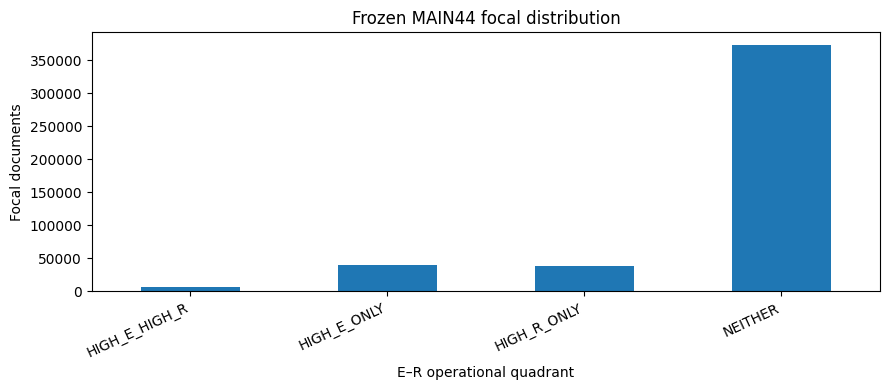

In [7]:
# CELL 7 | Frozen construct-dependence diagnostics and quadrants
for name in ('dimension_correlations','dependency_dpi','er_quadrants'):
    if name not in paths:continue
    dat=read_csv(name)
    print('\nARCHIVED',name,'n rows:',len(dat))
    display(dat.head(15))
    dat.to_csv(OUT/f'05_{name}_archived.csv',index=False)
# E-R quadrant sizes: descriptive only, no probabilistic national extrapolation.
quad=read_csv('er_quadrants')
if {'ER_QUADRANT_FINAL','N'}.issubset(quad.columns):
    assert int(quad['N'].sum())==459177
    ax=quad.plot.bar(x='ER_QUADRANT_FINAL',y='N',legend=False,figsize=(9,4))
    ax.set(xlabel='E–R operational quadrant',ylabel='Focal documents',title='Frozen MAIN44 focal distribution')
    plt.xticks(rotation=25,ha='right');plt.tight_layout()
    plt.savefig(OUT/'figure_01_er_quadrant_sizes.png',dpi=180);plt.show()

## 3. Primary process models versus distribution-appropriate robustness families
The historical project contains linear fixed-effects-type process summaries **and** distribution-aware robustness families. The revised paper must label outcomes and estimands, avoid interpreting linear coefficients as odds ratios, and avoid promoting exploratory interactions to causal claims. The journal-specific contribution is comparative methodological assessment, not a claim that ETS is already an externally validated scale.

In [8]:
# CELL 8 | Original process-model coefficient export
process=read_csv('process_coefficients')
necessary={'MODEL','OUTCOME','VARIABLE','BETA','SE_CLUSTER','CI95_LOW','CI95_HIGH','P_VALUE','N'}
assert necessary.issubset(process.columns),f'Missing: {necessary-set(process.columns)}'
assert process['P_VALUE'].dropna().between(0,1).all()
assert (process['CI95_LOW']<=process['CI95_HIGH']).all()
process['SIGNIFICANT_05_UNADJUSTED']=(process['P_VALUE']<0.05)
print('Models:',process.MODEL.nunique(),'Coefficient records:',len(process))
display(process[['MODEL','VARIABLE','BETA','SE_CLUSTER','CI95_LOW','CI95_HIGH','P_VALUE','N']].head(20))
process.to_csv(OUT/'06_primary_process_coefficients_verified.csv',index=False)

Models: 8 Coefficient records: 24


,MODEL,VARIABLE,BETA,SE_CLUSTER,CI95_LOW,CI95_HIGH,P_VALUE,N
0,D_TOTAL,E_C,-0.678232,0.003381,-0.684859,-0.671605,0.000000e+00,459177
1,D_TOTAL,R_C,0.012516,0.002874,0.006882,0.018150,1.335294e-05,459177
2,D_TOTAL,E_X_R,0.007465,0.006987,-0.006230,0.021159,2.853575e-01,459177
3,P_PAIRWISE_TOTAL,E_C,0.105600,0.002655,0.100397,0.110803,0.000000e+00,302956
4,P_PAIRWISE_TOTAL,R_C,-0.005785,0.002529,-0.010743,-0.000828,2.218077e-02,302956
5,P_PAIRWISE_TOTAL,E_X_R,-0.020379,0.008761,-0.037550,-0.003208,2.001211e-02,302956
6,P_PAIRWISE_COND_D,E_C,0.010151,0.003023,0.004226,0.016075,7.852610e-04,302956
7,P_PAIRWISE_COND_D,R_C,-0.000338,0.002406,-0.005053,0.004377,8.882448e-01,302956
8,P_PAIRWISE_COND_D,E_X_R,-0.008182,0.008233,-0.024318,0.007954,3.203053e-01,302956
9,P_T3_GIVEN_T1,E_C,-0.673317,0.004734,-0.682596,-0.664037,0.000000e+00,290520


In [9]:
# CELL 9 | Distribution-aware robustness family evidence
robust=read_csv('family_coefficients')
required={'MODEL','VARIABLE','BETA','SE_CLUSTER','CI95_LOW','CI95_HIGH','P_VALUE','N'}
assert required.issubset(robust.columns), required-set(robust.columns)
assert robust['P_VALUE'].dropna().between(0,1).all()
assert (robust['CI95_LOW']<=robust['CI95_HIGH']).all()
print('Families:',list(robust.MODEL.unique()))
display(robust[['MODEL','VARIABLE','BETA','SE_CLUSTER','CI95_LOW','CI95_HIGH','P_VALUE','N']])
robust.to_csv(OUT/'07_distribution_aware_robustness_verified.csv',index=False)
# Model-specific denominators are validated against the methodological register.
expected_models={'D_GROUPED_BINOMIAL':427649,'P_LOGIT_T3_GIVEN_T1':290520,
                 'T_GROUPED_BINOMIAL':363690,'I_FRACTIONAL_LOGIT':302956}
for key,n in expected_models.items():
    rows=robust.loc[robust.MODEL==key,'N'].dropna().unique()
    if len(rows):assert len(rows)==1 and int(rows[0])==n,(key,rows)
print('PASS: conditional model sample sizes wherever the matching archived model is present.')

Families: ['D_GROUPED_BINOMIAL', 'P_LOGIT_T3_GIVEN_T1', 'T_GROUPED_BINOMIAL', 'I_FRACTIONAL_LOGIT']


,MODEL,VARIABLE,BETA,SE_CLUSTER,CI95_LOW,CI95_HIGH,P_VALUE,N
0,D_GROUPED_BINOMIAL,E_C,0.263529,0.007687,0.248464,0.278595,1.353872e-257,427649
1,D_GROUPED_BINOMIAL,R_C,-0.043703,0.006687,-0.056809,-0.030597,6.325277e-11,427649
2,D_GROUPED_BINOMIAL,E_X_R,0.073697,0.022137,0.030309,0.117085,8.712477e-04,427649
3,P_LOGIT_T3_GIVEN_T1,E_C,-4.160573,0.039834,-4.238647,-4.082499,0.000000e+00,290520
4,P_LOGIT_T3_GIVEN_T1,R_C,0.109000,0.026382,0.057292,0.160707,3.602027e-05,290520
5,P_LOGIT_T3_GIVEN_T1,E_X_R,0.359700,0.100885,0.161968,0.557432,3.632577e-04,290520
6,T_GROUPED_BINOMIAL,E_C,-0.458872,0.028113,-0.513972,-0.403772,6.807115e-60,363690
7,T_GROUPED_BINOMIAL,R_C,1.490066,0.028533,1.434143,1.545990,0.000000e+00,363690
8,T_GROUPED_BINOMIAL,E_X_R,0.193146,0.067243,0.061352,0.324940,4.074227e-03,363690
9,I_FRACTIONAL_LOGIT,E_C,-2.006853,0.070058,-2.144164,-1.869542,1.818072e-180,302956


PASS: conditional model sample sizes wherever the matching archived model is present.


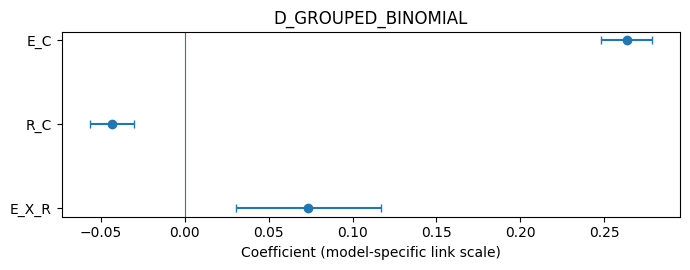

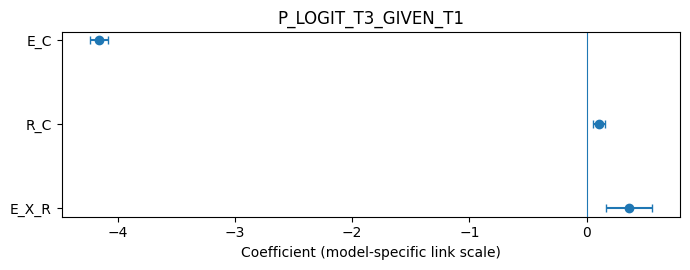

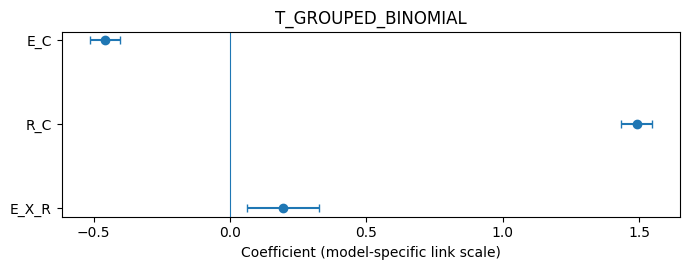

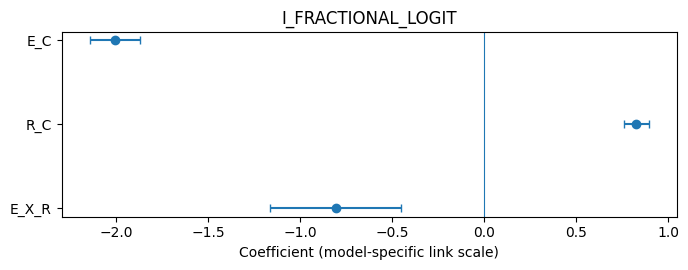

Caution: never rank the magnitudes of coefficients across logit, grouped binomial, and fractional logit without common-scale marginal effects.


In [10]:
# CELL 10 | Summary figure: effects are NOT directly comparable across different links
variables=['E_C','R_C','E_X_R']
use=robust[robust.VARIABLE.isin(variables)].copy()
for model,one in use.groupby('MODEL',sort=False):
    fig,ax=plt.subplots(figsize=(7,2.8))
    z=one.set_index('VARIABLE').reindex(variables).dropna(subset=['BETA'])
    x=z['BETA'].to_numpy(float)
    err=np.vstack([x-z.CI95_LOW.to_numpy(float),z.CI95_HIGH.to_numpy(float)-x])
    ax.errorbar(x,np.arange(len(z)),xerr=err,fmt='o',capsize=3)
    ax.axvline(0,linewidth=.8)
    ax.set_yticks(range(len(z)),z.index.tolist());ax.invert_yaxis()
    ax.set(xlabel='Coefficient (model-specific link scale)',title=model)
    fig.tight_layout();fig.savefig(OUT/f'figure_02_{model}_coefficients.png',dpi=180);plt.show()
print('Caution: never rank the magnitudes of coefficients across logit, grouped binomial, and fractional logit without common-scale marginal effects.')

## 4. Hubness and document-level estimand diagnostics
The original ETS project documented semantic exposure bias and the distinction between being retrieved as an antecedent and being conditionally taken up. This stage **reads existing results**; it does not infer criterion validity from cosine neighborhoods. Document-weighted T must not be silently replaced by event-weighted T.

In [11]:
# CELL 11 | Archived hubness, conditional diffusion and translation estimand checks
extra=['hubness_conversion','diffusion_conditional','translation_estimands','translation_fractional']
for name in extra:
    if name not in paths:
        print('NOT FOUND:',name);continue
    d=read_csv(name)
    print('\nARCHIVED:',name,'shape',d.shape)
    display(d.head(12))
    d.to_csv(OUT/f'08_{name}_archived.csv',index=False)
if 'hubness_dataset' in paths:
    import pyarrow.parquet as pq
    p=paths['hubness_dataset']
    meta=pq.ParquetFile(p).metadata
    print('Hubness audit dataset:',meta.num_rows,'rows',meta.num_columns,'columns')
    schema=pq.read_schema(p)
    (OUT/'09_hubness_schema.txt').write_text(str(schema),encoding='utf8')


ARCHIVED: hubness_conversion shape (4, 9)


,VARIABLE,BETA,SE,CI95_LOW,CI95_HIGH,P_VALUE,N,N_PPG,R2_WITHIN
0,E_C,0.173968,0.004149,0.165837,0.182100,0.000000e+00,427649,4250,0.013388
1,R_C,-0.024340,0.001950,-0.028163,-0.020517,9.626767e-36,427649,4250,0.013388
2,E_X_R,0.039386,0.006804,0.026050,0.052721,7.101244e-09,427649,4250,0.013388
3,H50_PCT_AREA_ANO,0.200855,0.004373,0.192285,0.209425,0.000000e+00,427649,4250,0.013388



ARCHIVED: diffusion_conditional shape (15, 13)


,MODEL,VARIABLE,BETA,SE,CI95_LOW,CI95_HIGH,P_VALUE,N,N_PPG,N_FE,R2,MIN_H50,WEIGHTED_BY_H50
0,H50_EXPOSURE_DIAGNOSTIC,E_C,-0.819575,0.003270,-0.825983,-0.813166,0.000000e+00,459177,4251,264,0.681065,0,False
1,H50_EXPOSURE_DIAGNOSTIC,R_C,0.021534,0.002931,0.015789,0.027279,2.035248e-13,459177,4251,264,0.681065,0,False
2,H50_EXPOSURE_DIAGNOSTIC,E_X_R,-0.019561,0.007573,-0.034404,-0.004717,9.798683e-03,459177,4251,264,0.681065,0,False
3,D_CONVERSION_OLS,E_C,0.099573,0.001653,0.096334,0.102813,0.000000e+00,427649,4250,264,0.021485,1,False
4,D_CONVERSION_OLS,R_C,-0.011053,0.001307,-0.013615,-0.008491,2.742412e-17,427649,4250,264,0.021485,1,False
5,D_CONVERSION_OLS,E_X_R,0.026971,0.004917,0.017334,0.036608,4.130813e-08,427649,4250,264,0.021485,1,False
6,D_CONVERSION_WLS_H50,E_C,0.043037,0.001288,0.040512,0.045562,1.074062e-244,427649,4250,264,0.011298,1,True
7,D_CONVERSION_WLS_H50,R_C,-0.007283,0.001140,-0.009517,-0.005049,1.663496e-10,427649,4250,264,0.011298,1,True
8,D_CONVERSION_WLS_H50,E_X_R,0.010714,0.003661,0.003538,0.017890,3.428132e-03,427649,4250,264,0.011298,1,True
9,D_CONVERSION_WLS_H50_GE5,E_C,0.038765,0.001313,0.036191,0.041339,1.719527e-191,347241,4244,264,0.009773,5,True



ARCHIVED: translation_estimands shape (2, 4)


,MODEL,E_BETA,R_BETA,EXR_BETA
0,DOCUMENT_WEIGHTED_FRACTIONAL_LOGIT,-0.518701,1.428625,-0.027904
1,EDGE_WEIGHTED_GROUPED_BINOMIAL,-0.458870,1.490070,0.193150



ARCHIVED: translation_fractional shape (3, 8)


,VARIABLE,BETA,SE_CLUSTER,CI95_LOW,CI95_HIGH,P_VALUE,N,N_PPG
0,E_C,-0.518701,0.023707,-0.565165,-0.472237,4.029514e-106,363690,4248
1,R_C,1.428625,0.024653,1.380305,1.476944,0.000000e+00,363690,4248
2,E_X_R,-0.027904,0.048948,-0.123841,0.068032,5.686260e-01,363690,4248


Hubness audit dataset: 459177 rows 76 columns


In [12]:
# CELL 12 | Scope-separation checklist for two simultaneously developed papers
scope=pd.DataFrame([
 {'question':'What is measured?','ETS_QQ':'Six-dimensional operational signature of longitudinal research transitions','NEW_SCIENTOMETRICS':'Sensitivity of antecedent retrieval to fields, methods and windows'},
 {'question':'Primary estimand','ETS_QQ':'E/R predicting conditional D/P/T/I, with eligibility-specific populations','NEW_SCIENTOMETRICS':'Ranked antecedent-set overlap/stability in 108 balanced focals'},
 {'question':'Analytical population','ETS_QQ':'MAIN44 focal corpus 2016–2021, n=459,177; outcomes conditional','NEW_SCIENTOMETRICS':'Balanced 108 focals, 2016–2024'},
 {'question':'Claim limits','ETS_QQ':'No causal epistemic influence or independently validated ETS scale','NEW_SCIENTOMETRICS':'No criterion-validity proof from rank concordance'},
])
display(scope)
scope.to_csv(OUT/'10_manuscript_distinctness_matrix.csv',index=False)

,question,ETS_QQ,NEW_SCIENTOMETRICS
0,What is measured?,Six-dimensional operational signature of longi...,"Sensitivity of antecedent retrieval to fields,..."
1,Primary estimand,"E/R predicting conditional D/P/T/I, with eligi...",Ranked antecedent-set overlap/stability in 108...
2,Analytical population,"MAIN44 focal corpus 2016–2021, n=459,177; outc...","Balanced 108 focals, 2016–2024"
3,Claim limits,No causal epistemic influence or independently...,No criterion-validity proof from rank concordance


## 5. Final export, QA and recommended new methodological experiments

**Recommended upgrades for *Quality & Quantity*** (not represented as completed)

In [13]:
# CELL 13 | Audit report; all generated material stays in new folder
versions={p:version(p) for p in ('numpy','pandas','pyarrow','scipy','matplotlib')}
report={
 'journal':'Quality & Quantity: International Journal of Methodology',
 'project':'Beyond disruption scores: Epistemic Transition Signatures in Brazil’s postgraduate research system, 2013–2024',
 'status':'ARCHIVAL AUDIT — NOT A FULL RECOMPUTATION',
 'utc_time':datetime.now(timezone.utc).isoformat(),
 'root':str(ROOT),
 'python':platform.python_version(),
 'versions':versions,
 'upstream_files':manifest,
 'main44_rows':int(len(frame)),
 'expected_main44_rows':459177,
 'main44_columns':list(frame.columns),
 'completed_tests':['required input discovery','MAIN44 row count','dimension-count integrity',
                    'primary coefficient CI/p-value bounds','robustness model CI/p-value bounds',
                    'available model-level eligibility checks'],
 'not_completed':['full upstream embedding generation','full raw-data rerun','external expert criterion validation',
                  'new multiresolution/cross-period robustness models'],
 'release_warning':'May contain filenames and document metadata; review before public release.'}
(OUT/'11_QQ_ETS_lab_audit_report.json').write_text(json.dumps(report,indent=2,ensure_ascii=False),encoding='utf8')
print('Saved verified outputs:',OUT)
print('Files created:',len(list(OUT.iterdir())))
print('Status:',report['status'])

Saved verified outputs: /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026
Files created: 21
Status: ARCHIVAL AUDIT — NOT A FULL RECOMPUTATION


# 6. Continued laboratory — Quality & Quantity methodological validation

In [14]:
# CELL 14 | Dedicated continuation output and frozen eligibility registry
from pathlib import Path
from scipy.special import expit
from scipy.stats import norm
import numpy as np
import pandas as pd
import json
QOUT = OUT/'QQ_CONTINUATION_V1'
QOUT.mkdir(parents=True,exist_ok=True)
assert len(frame)==459177
registry = pd.DataFrame([
    {'dimension':'E','construct':'Emergence','archived_valid_n':459177,'primary_model_n':459177,'condition':'Historical frontier score is defined'},
    {'dimension':'R','construct':'Recombination','archived_valid_n':459177,'primary_model_n':459177,'condition':'Top-10 antecedent entropy is defined'},
    {'dimension':'D','construct':'Diffusion','archived_valid_n':459177,'primary_model_n':427649,'condition':'Positive future semantic exposure H50'},
    {'dimension':'P','construct':'Persistence','archived_valid_n':302956,'primary_model_n':290520,'condition':'Year t+1 uptake for t+3|t+1 primary logit'},
    {'dimension':'T','construct':'Translation','archived_valid_n':363690,'primary_model_n':363690,'condition':'At least one future top-10 uptake event'},
    {'dimension':'I','construct':'Institutionalization','archived_valid_n':302956,'primary_model_n':302956,'condition':'At least two future uptake events'},
])
registry['model_minus_archived_n']=registry['primary_model_n']-registry['archived_valid_n']
registry.to_csv(QOUT/'14_eligibility_estimand_registry.csv',index=False)
display(registry)
assert registry.loc[registry.dimension.eq('D'),'primary_model_n'].item()==427649
assert registry.loc[registry.dimension.eq('P'),'primary_model_n'].item()==290520
print('PASS: separate archived variable coverage from model-specific risk sets.')

,dimension,construct,archived_valid_n,primary_model_n,condition,model_minus_archived_n
0,E,Emergence,459177,459177,Historical frontier score is defined,0
1,R,Recombination,459177,459177,Top-10 antecedent entropy is defined,0
2,D,Diffusion,459177,427649,Positive future semantic exposure H50,-31528
3,P,Persistence,302956,290520,Year t+1 uptake for t+3|t+1 primary logit,-12436
4,T,Translation,363690,363690,At least one future top-10 uptake event,0
5,I,Institutionalization,302956,302956,At least two future uptake events,0


PASS: separate archived variable coverage from model-specific risk sets.


# 6.1 Eligibility integrity, data ranges, and conditioning checks

In [15]:
# CELL 15 | Validate actual analytic eligibility and ranges against archived variables
checks=[]
def record(label,observed,expected,details=''):
    status=('MATCH' if observed==expected else 'REVIEW') if expected is not None else 'INFORMATIONAL'
    checks.append({'check':label,'observed_n':int(observed),'expected_n':expected,'status':status,'details':details})
for v in ['E_PCT_AREA_ANO','R_PCT_AREA_ANO','D_PCT_AREA_ANO','P_T3_GIVEN_T1',
          'T_CROSS_GRANDE_SHARE','I_PROGRAM_DIVERSITY_PAIRWISE']:
    if v not in frame.columns:continue
    x=pd.to_numeric(frame[v],errors='coerce')
    if v.endswith('_PCT_AREA_ANO') or v in ['P_T3_GIVEN_T1','T_CROSS_GRANDE_SHARE','I_PROGRAM_DIVERSITY_PAIRWISE']:
        invalid=int(((x<0)|(x>1)).sum())
        checks.append({'check':'bounded_0_1_'+v,'observed_n':invalid,'expected_n':0,
                      'status':'MATCH' if invalid==0 else 'REVIEW', 'details':'Out-of-range nonmissing values'})
    record('nonmissing_'+v,int(x.notna().sum()),None,'Coverage only; not necessarily the model risk set')
if 'P_HITS_T1' in frame and 'P_T3_GIVEN_T1' in frame:
    eligible=pd.to_numeric(frame['P_HITS_T1'],errors='coerce')>0
    y=pd.to_numeric(frame['P_T3_GIVEN_T1'],errors='coerce')
    record('P_t1_positive_and_t3_observed',int((eligible & y.notna()).sum()),290520,
           'Check archived persistence-logit risk set; a mismatch requires reconstructing sample flags')
if 'I_N_FUTURE_PROGRAMS' in frame and 'I_PROGRAM_DIVERSITY_PAIRWISE' in frame:
    hit_count=pd.to_numeric(frame.get('D_HITS_3Y'),errors='coerce') if 'D_HITS_3Y' in frame else None
    if hit_count is not None:
        eligible=hit_count>=2
        measure=pd.to_numeric(frame['I_PROGRAM_DIVERSITY_PAIRWISE'],errors='coerce')
        record('I_at_least_two_uptake_and_observed',int((eligible & measure.notna()).sum()),302956,
               'Pairwise diversity requires two uptake events; check against definitive model eligibility')
res=pd.DataFrame(checks)
res.to_csv(QOUT/'15_field_eligibility_integrity.csv',index=False)
display(res)
print('REVIEW findings are diagnostic discrepancies, not grounds to recode missing outcomes.')

,check,observed_n,expected_n,status,details
0,bounded_0_1_E_PCT_AREA_ANO,0,0.0,MATCH,Out-of-range nonmissing values
1,nonmissing_E_PCT_AREA_ANO,459177,NaN,INFORMATIONAL,Coverage only; not necessarily the model risk set
2,bounded_0_1_R_PCT_AREA_ANO,0,0.0,MATCH,Out-of-range nonmissing values
3,nonmissing_R_PCT_AREA_ANO,459177,NaN,INFORMATIONAL,Coverage only; not necessarily the model risk set
4,bounded_0_1_D_PCT_AREA_ANO,0,0.0,MATCH,Out-of-range nonmissing values
5,nonmissing_D_PCT_AREA_ANO,459177,NaN,INFORMATIONAL,Coverage only; not necessarily the model risk set
6,bounded_0_1_P_T3_GIVEN_T1,0,0.0,MATCH,Out-of-range nonmissing values
7,nonmissing_P_T3_GIVEN_T1,290520,NaN,INFORMATIONAL,Coverage only; not necessarily the model risk set
8,bounded_0_1_T_CROSS_GRANDE_SHARE,0,0.0,MATCH,Out-of-range nonmissing values
9,nonmissing_T_CROSS_GRANDE_SHARE,363690,NaN,INFORMATIONAL,Coverage only; not necessarily the model risk set


REVIEW findings are diagnostic discrepancies, not grounds to recode missing outcomes.


# 6.2 Link-scale transformation — audited coefficients and odds ratios

In [16]:
# CELL 16 | Link-aware exponentiation and evidence table (no invented marginal effects)
link_map={'D_GROUPED_BINOMIAL':'logit','P_LOGIT_T3_GIVEN_T1':'logit',
          'T_GROUPED_BINOMIAL':'logit','I_FRACTIONAL_LOGIT':'logit'}
qq=robust[robust.MODEL.isin(link_map)].copy()
qq['LINK']=qq.MODEL.map(link_map)
for k in ['BETA','SE_CLUSTER','CI95_LOW','CI95_HIGH','P_VALUE']:
    qq[k]=pd.to_numeric(qq[k],errors='raise')
qq['ODDS_RATIO_CONDITIONAL']=np.exp(qq.BETA)
qq['OR_CI95_LOW']=np.exp(qq.CI95_LOW)
qq['OR_CI95_HIGH']=np.exp(qq.CI95_HIGH)
qq['STATISTICAL_NOTE']='Conditional odds ratio on link scale; E_C/R_C centering must be checked'
cols=['MODEL','VARIABLE','N','BETA','SE_CLUSTER','CI95_LOW','CI95_HIGH',
      'P_VALUE','ODDS_RATIO_CONDITIONAL','OR_CI95_LOW','OR_CI95_HIGH','STATISTICAL_NOTE']
qq[cols].to_csv(QOUT/'16_conditional_odds_ratios.csv',index=False)
display(qq[cols].round(5))
# Model-level E slope at a chosen numerical R_C; point estimates only, no SE without covariances.
rows=[]
for model,g in qq.groupby('MODEL'):
    bb=dict(zip(g.VARIABLE,g.BETA))
    if not {'E_C','E_X_R'}.issubset(bb):continue
    for rc in [-0.20,0.00,0.20]:
        b=bb['E_C']+rc*bb['E_X_R']
        rows.append({'model':model,'R_C_value':rc,'d_logodds_d_E_C':b,
                     'OR_per_one_unit_E_C':float(np.exp(b)),
                     'status':'POINT_ESTIMATE_ONLY_NO_COVARIANCE'})
slopes=pd.DataFrame(rows)
slopes.to_csv(QOUT/'16b_interaction_simple_slopes_points_only.csv',index=False)
display(slopes)

,MODEL,VARIABLE,N,BETA,SE_CLUSTER,CI95_LOW,CI95_HIGH,P_VALUE,ODDS_RATIO_CONDITIONAL,OR_CI95_LOW,OR_CI95_HIGH,STATISTICAL_NOTE
0,D_GROUPED_BINOMIAL,E_C,427649,0.26353,0.00769,0.24846,0.27859,0.00000,1.30152,1.28205,1.32127,Conditional odds ratio on link scale; E_C/R_C ...
1,D_GROUPED_BINOMIAL,R_C,427649,-0.04370,0.00669,-0.05681,-0.03060,0.00000,0.95724,0.94477,0.96987,Conditional odds ratio on link scale; E_C/R_C ...
2,D_GROUPED_BINOMIAL,E_X_R,427649,0.07370,0.02214,0.03031,0.11709,0.00087,1.07648,1.03077,1.12422,Conditional odds ratio on link scale; E_C/R_C ...
3,P_LOGIT_T3_GIVEN_T1,E_C,290520,-4.16057,0.03983,-4.23865,-4.08250,0.00000,0.01560,0.01443,0.01687,Conditional odds ratio on link scale; E_C/R_C ...
4,P_LOGIT_T3_GIVEN_T1,R_C,290520,0.10900,0.02638,0.05729,0.16071,0.00004,1.11516,1.05897,1.17434,Conditional odds ratio on link scale; E_C/R_C ...
5,P_LOGIT_T3_GIVEN_T1,E_X_R,290520,0.35970,0.10089,0.16197,0.55743,0.00036,1.43290,1.17582,1.74618,Conditional odds ratio on link scale; E_C/R_C ...
6,T_GROUPED_BINOMIAL,E_C,363690,-0.45887,0.02811,-0.51397,-0.40377,0.00000,0.63200,0.59812,0.66780,Conditional odds ratio on link scale; E_C/R_C ...
7,T_GROUPED_BINOMIAL,R_C,363690,1.49007,0.02853,1.43414,1.54599,0.00000,4.43739,4.19605,4.69262,Conditional odds ratio on link scale; E_C/R_C ...
8,T_GROUPED_BINOMIAL,E_X_R,363690,0.19315,0.06724,0.06135,0.32494,0.00407,1.21306,1.06327,1.38395,Conditional odds ratio on link scale; E_C/R_C ...
9,I_FRACTIONAL_LOGIT,E_C,302956,-2.00685,0.07006,-2.14416,-1.86954,0.00000,0.13441,0.11717,0.15419,Conditional odds ratio on link scale; E_C/R_C ...


,model,R_C_value,d_logodds_d_E_C,OR_per_one_unit_E_C,status
0,D_GROUPED_BINOMIAL,-0.2,0.248790,1.282473,POINT_ESTIMATE_ONLY_NO_COVARIANCE
1,D_GROUPED_BINOMIAL,0.0,0.263529,1.301516,POINT_ESTIMATE_ONLY_NO_COVARIANCE
2,D_GROUPED_BINOMIAL,0.2,0.278269,1.320841,POINT_ESTIMATE_ONLY_NO_COVARIANCE
3,I_FRACTIONAL_LOGIT,-0.2,-1.845506,0.157945,POINT_ESTIMATE_ONLY_NO_COVARIANCE
4,I_FRACTIONAL_LOGIT,0.0,-2.006853,0.134411,POINT_ESTIMATE_ONLY_NO_COVARIANCE
5,I_FRACTIONAL_LOGIT,0.2,-2.168200,0.114383,POINT_ESTIMATE_ONLY_NO_COVARIANCE
6,P_LOGIT_T3_GIVEN_T1,-0.2,-4.232513,0.014516,POINT_ESTIMATE_ONLY_NO_COVARIANCE
7,P_LOGIT_T3_GIVEN_T1,0.0,-4.160573,0.015599,POINT_ESTIMATE_ONLY_NO_COVARIANCE
8,P_LOGIT_T3_GIVEN_T1,0.2,-4.088633,0.016762,POINT_ESTIMATE_ONLY_NO_COVARIANCE
9,T_GROUPED_BINOMIAL,-0.2,-0.497501,0.608048,POINT_ESTIMATE_ONLY_NO_COVARIANCE


# 6.3 Translation estimand sensitivity

In [17]:
# CELL 17 | Contrast translation estimands, verify consistency and mark inference limits
fraction=read_csv('translation_fractional')
event=robust.loc[robust.MODEL.eq('T_GROUPED_BINOMIAL')]
cols_need=['VARIABLE','BETA','SE_CLUSTER','CI95_LOW','CI95_HIGH','P_VALUE','N']
a=event[cols_need].set_index('VARIABLE'); b=fraction[cols_need].set_index('VARIABLE')
comparison=(a.add_prefix('EVENT_').join(b.add_prefix('DOCUMENT_'),how='inner'))
comparison['COEFFICIENT_DIFFERENCE_EVENT_MINUS_DOCUMENT']=comparison.EVENT_BETA-comparison.DOCUMENT_BETA
comparison['SIGN_CHANGE']=np.sign(comparison.EVENT_BETA)!=np.sign(comparison.DOCUMENT_BETA)
comparison['INTERPRETATION']='Not a test of coefficient equality; different weighting estimands'
comparison.reset_index().to_csv(QOUT/'17_translation_estimand_sensitivity.csv',index=False)
display(comparison.round(6))
assert {'E_C','R_C','E_X_R'}.issubset(comparison.index)
assert comparison.loc['E_X_R','SIGN_CHANGE'], 'Archived interaction sign contrast differs from expected; review inputs.'
print('PASS: interaction E×R changes sign across event- vs document-weighted estimands.')

,EVENT_BETA,EVENT_SE_CLUSTER,EVENT_CI95_LOW,EVENT_CI95_HIGH,EVENT_P_VALUE,EVENT_N,DOCUMENT_BETA,DOCUMENT_SE_CLUSTER,DOCUMENT_CI95_LOW,DOCUMENT_CI95_HIGH,DOCUMENT_P_VALUE,DOCUMENT_N,COEFFICIENT_DIFFERENCE_EVENT_MINUS_DOCUMENT,SIGN_CHANGE,INTERPRETATION
VARIABLE,,,,,,,,,,,,,,,
E_C,-0.458872,0.028113,-0.513972,-0.403772,0.000000,363690,-0.518701,0.023707,-0.565165,-0.472237,0.000000,363690,0.059829,False,Not a test of coefficient equality; different ...
R_C,1.490066,0.028533,1.434143,1.545990,0.000000,363690,1.428625,0.024653,1.380305,1.476944,0.000000,363690,0.061442,False,Not a test of coefficient equality; different ...
E_X_R,0.193146,0.067243,0.061352,0.324940,0.004074,363690,-0.027904,0.048948,-0.123841,0.068032,0.568626,363690,0.221050,True,Not a test of coefficient equality; different ...


PASS: interaction E×R changes sign across event- vs document-weighted estimands.


# 6.4 Disciplinary and temporal composition of the E–R quadrants

In [18]:
# CELL 18 | New descriptive area-year composition and common-support contrast
required=['ER_QUADRANT_FINAL','NM_GRANDE_AREA_CONHECIMENTO','ANO','D_PCT_AREA_ANO']
missing=[v for v in required if v not in frame]
if missing: raise KeyError(f'Cannot compute area-year composition diagnostic: missing {missing}')
d=frame[required].copy()
d['D_PCT_AREA_ANO']=pd.to_numeric(d['D_PCT_AREA_ANO'],errors='coerce')
d=d.dropna(subset=required)
d['STRATUM']=d['NM_GRANDE_AREA_CONHECIMENTO'].astype(str)+' | '+d['ANO'].astype(str)
q=['HIGH_E_HIGH_R','HIGH_E_ONLY','HIGH_R_ONLY','NEITHER']
d=d[d['ER_QUADRANT_FINAL'].isin(q)]
agg=(d.groupby(['STRATUM','ER_QUADRANT_FINAL'],observed=True)
       .agg(n=('D_PCT_AREA_ANO','size'),mean_D=('D_PCT_AREA_ANO','mean')).reset_index())
wide=agg.pivot(index='STRATUM',columns='ER_QUADRANT_FINAL',values='n').reindex(columns=q)
common=wide.notna().all(axis=1)
# Distribution of strata across eligible documents, not equal stratum weights.
stratum_counts=d.groupby('STRATUM').size()
weights=stratum_counts.loc[common[common].index]
weights=weights/weights.sum()
result=[]
for g in q:
    sub=agg[(agg.ER_QUADRANT_FINAL==g)&agg.STRATUM.isin(weights.index)].set_index('STRATUM')
    mean=float((sub.loc[weights.index,'mean_D']*weights).sum()) if len(weights) else np.nan
    result.append({'quadrant':g,'observed_n':int((d.ER_QUADRANT_FINAL==g).sum()),
                   'common_support_n':int(sub.n.sum()),
                   'standardized_mean_D':mean,'common_support_strata':int(common.sum()),
                   'total_strata':len(wide),'estimator':'Area-year standardization, pooled eligible-stratum weights'})
out=pd.DataFrame(result)
agg.to_csv(QOUT/'18_area_year_quadrant_cells.csv',index=False)
out.to_csv(QOUT/'18_area_year_standardized_quadrants.csv',index=False)
display(out)
if not common.all(): print('WARNING: some area-year strata lack at least one quadrant; common-support restriction applied.')
print('This is a descriptive sensitivity estimate, not a causal adjustment or a refitted regression.')

,quadrant,observed_n,common_support_n,standardized_mean_D,common_support_strata,total_strata,estimator
0,HIGH_E_HIGH_R,6705,6705,0.234889,48,48,"Area-year standardization, pooled eligible-str..."
1,HIGH_E_ONLY,39355,39355,0.214446,48,48,"Area-year standardization, pooled eligible-str..."
2,HIGH_R_ONLY,39211,39211,0.516987,48,48,"Area-year standardization, pooled eligible-str..."
3,NEITHER,373906,373906,0.533418,48,48,"Area-year standardization, pooled eligible-str..."


This is a descriptive sensitivity estimate, not a causal adjustment or a refitted regression.


# 6.5 Hubness information audit and next modeling gate

In [19]:
# CELL 19 | Discover H10/H50 source variables; no guessed aliases or invented predictions
import pyarrow.parquet as pq
hub=pq.ParquetFile(paths['hubness_dataset'])
cols=hub.schema_arrow.names
candidate=[v for v in cols if any(token in v.upper() for token in ['H10','H50','HUB','EXPOS','CONVERS'])]
hmap=pd.DataFrame({'column':candidate, 'requires_explicit_selection':[True]*len(candidate)})
hmap.to_csv(QOUT/'19_hubness_variable_discovery.csv',index=False)
display(hmap)
# Identify actual contents of the stage-31 folder; do not classify an existing folder as missing.
stage31=stages['31_sensibilidade_diffusion_k']
items=[{'relative_path':str(p.relative_to(stage31)), 'bytes':p.stat().st_size}
       for p in stage31.rglob('*') if p.is_file()]
items_df=pd.DataFrame(items,columns=['relative_path','bytes'])
items_df.to_csv(QOUT/'19_stage31_k_sensitivity_inventory.csv',index=False)
print('Stage-31 archived files:',len(items_df))
display(items_df.head(40))
criteria={
  'complete coefficient covariance matrices':False,
  'reconstructed regression intercepts and categorical design':False,
  'confirmed frozen E_C/R_C scaling and centering':False,
  'exact original conditioning/risk-set flags':False,
  'criterion-related human validation':False,
}
print('Prediction/readiness gate (False = not yet verified, NOT a claim of absence):')
print(json.dumps(criteria,indent=2))

,column,requires_explicit_selection
0,H50_SEMANTIC_EXPOSURE_3Y,True
1,D10_GIVEN_H50_RATE,True
2,H50_PCT_AREA_ANO,True
3,D10_GIVEN_H50_PCT_AREA_ANO,True


Stage-31 archived files: 2


,relative_path,bytes
0,sensibilidade_kK_coeficientes.csv,2595
1,sensibilidade_kK_simple_slopes.csv,1361


Prediction/readiness gate (False = not yet verified, NOT a claim of absence):
{
  "complete coefficient covariance matrices": false,
  "reconstructed regression intercepts and categorical design": false,
  "confirmed frozen E_C/R_C scaling and centering": false,
  "exact original conditioning/risk-set flags": false,
  "criterion-related human validation": false
}


In [20]:
# CELL 20 | Freeze continuation outputs; fail if a required new artifact was not generated
required=[
 '14_eligibility_estimand_registry.csv','15_field_eligibility_integrity.csv',
 '16_conditional_odds_ratios.csv','16b_interaction_simple_slopes_points_only.csv',
 '17_translation_estimand_sensitivity.csv','18_area_year_standardized_quadrants.csv',
 '19_hubness_variable_discovery.csv','19_stage31_k_sensitivity_inventory.csv']
missing=[x for x in required if not (QOUT/x).is_file()]
assert not missing, f'Incomplete laboratory: {missing}'
status={'journal':'Quality & Quantity','laboratory':'ETS methodological continuation',
        'status':'ARCHIVE-BASED CHECKS AND NEW DESCRIPTIVE STANDARDIZATION; NO REFIT CLAIMED',
        'created_utc':datetime.now(timezone.utc).isoformat(),
        'main44_n':int(len(frame)),
        'files':[{'name':p.name,'sha256':sha256_file(p)} for p in sorted(QOUT.glob('*.csv'))],
        'limits':['No full archived covariance matrix; interaction slope intervals not computed',
                  'Unconfirmed model-specific E_C/R_C scaling; no marginal probabilities claimed',
                  'No causal effects or independent external construct validity established']}
(QOUT/'20_continuation_manifest.json').write_text(json.dumps(status,indent=2),encoding='utf-8')
print('PASS. Continuation exports:',QOUT)
print('Files generated:',len(list(QOUT.iterdir())))

PASS. Continuation exports: /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026/QQ_CONTINUATION_V1
Files generated: 10


# Quality & Quantity — ETS methodological continuation (Cells 21–27)

In [21]:
# CELL 21 | Dedicated extension output, preflight, and reproducible metadata
from pathlib import Path
import numpy as np, pandas as pd, json, hashlib, re
from datetime import datetime, timezone
from IPython.display import display
import pyarrow.parquet as pq
assert 'QOUT' in globals() and QOUT.exists(), 'Run cells 14–20 first.'
assert len(frame)==459177 and {'MODEL','VARIABLE','BETA','N'}.issubset(robust.columns)
V2=OUT/'QQ_CONTINUATION_V2'; V2.mkdir(parents=True,exist_ok=True)
META={'name':'Quality & Quantity ETS methodological diagnostics','read_only_sources':True,
      'original_source_root':str(ROOT),'saved_utc':datetime.now(timezone.utc).isoformat()}
(V2/'21_runtime_manifest.json').write_text(json.dumps(META,indent=2),encoding='utf-8')
print('Ready; new outputs:',V2)


Ready; new outputs: /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026/QQ_CONTINUATION_V2


# 7.1 Sensitivity to the semantic neighborhood cutoff k

In [22]:
# CELL 22 | Read Stage-31 k-sensitivity data, preserving original schemas and labels
stage31=stages['31_sensibilidade_diffusion_k']
kfiles=sorted([p for p in stage31.rglob('*.csv') if p.is_file()])
assert kfiles, 'No Stage-31 CSV found; do not infer that a missing file is a zero outcome.'
frames=[]; columns=[]
for f in kfiles:
    dat=pd.read_csv(f,encoding='utf-8-sig')
    columns.extend({'source_file':str(f.relative_to(stage31)),'column':str(c),'nrows':len(dat)} for c in dat.columns)
    frames.append((f,dat))
    print('ARCHIVED',f.name,'shape=',dat.shape,'columns=',list(dat.columns))
pd.DataFrame(columns).to_csv(V2/'22_stage31_schemas.csv',index=False)
# Identify coefficient table by field names, never by a guessed row layout.
coef_tables=[]
for f,dat in frames:
    canon={str(c).upper().strip():c for c in dat.columns}
    if 'BETA' in canon and any('K' in str(c).upper() for c in dat.columns):
        z=dat.copy();z.insert(0,'SOURCE_FILE',f.name);coef_tables.append(z)
if coef_tables:
    coeff=pd.concat(coef_tables,ignore_index=True,sort=False)
    coeff.to_csv(V2/'22_k_sensitivity_archived_coefficients.csv',index=False)
    display(coeff.head(35))
else:
    print('REVIEW: coefficient or k identifier differs; inspect the printed schemas. Raw input files remain unchanged.')


ARCHIVED sensibilidade_kK_coeficientes.csv shape= (15, 12) columns= ['STRONG_K', 'BROAD_K', 'VARIABLE', 'BETA', 'SE', 'CI95_LOW', 'CI95_HIGH', 'P_VALUE', 'N', 'N_PPG', 'R2', 'MEAN_CONVERSION']
ARCHIVED sensibilidade_kK_simple_slopes.csv shape= (15, 7) columns= ['STRONG_K', 'BROAD_K', 'R_PERCENTILE', 'E_P10_P90_PP', 'CI95_LOW_PP', 'CI95_HIGH_PP', 'P_VALUE']


,SOURCE_FILE,STRONG_K,BROAD_K,VARIABLE,BETA,SE,CI95_LOW,CI95_HIGH,P_VALUE,N,N_PPG,R2,MEAN_CONVERSION
0,sensibilidade_kK_coeficientes.csv,5,25,E_C,0.057741,0.001436,0.054926,0.060556,0.000000e+00,291511,4242,0.015959,0.210882
1,sensibilidade_kK_coeficientes.csv,5,25,R_C,-0.005479,0.001334,-0.008093,-0.002865,3.997177e-05,291511,4242,0.015959,0.210882
2,sensibilidade_kK_coeficientes.csv,5,25,E_X_R,0.007238,0.004111,-0.000820,0.015296,7.833633e-02,291511,4242,0.015959,0.210882
3,sensibilidade_kK_coeficientes.csv,5,50,E_C,0.035665,0.000941,0.033820,0.037510,0.000000e+00,347241,4244,0.014387,0.113723
4,sensibilidade_kK_coeficientes.csv,5,50,R_C,-0.004798,0.000849,-0.006461,-0.003135,1.571109e-08,347241,4244,0.014387,0.113723
5,sensibilidade_kK_coeficientes.csv,5,50,E_X_R,0.005731,0.002653,0.000531,0.010930,3.075466e-02,347241,4244,0.014387,0.113723
6,sensibilidade_kK_coeficientes.csv,10,25,E_C,0.055326,0.001651,0.052090,0.058562,3.246569e-246,291511,4242,0.010860,0.407756
7,sensibilidade_kK_coeficientes.csv,10,25,R_C,-0.006881,0.001574,-0.009967,-0.003796,1.236272e-05,291511,4242,0.010860,0.407756
8,sensibilidade_kK_coeficientes.csv,10,25,E_X_R,0.010937,0.004940,0.001256,0.020619,2.681185e-02,291511,4242,0.010860,0.407756
9,sensibilidade_kK_coeficientes.csv,10,50,E_C,0.038765,0.001313,0.036191,0.041339,1.719527e-191,347241,4244,0.009773,0.214158


# 7.2 Exact exposure, conversion and conditional risk-set definitions

In [23]:
# CELL 23 | Verify H50 and H10/H50 variables against the frozen hubness table
p=paths['hubness_dataset']
arrow=pq.ParquetFile(p); cols=set(arrow.schema_arrow.names)
needed=['ID_TRABALHO','H50_SEMANTIC_EXPOSURE_3Y','D10_GIVEN_H50_RATE',
        'H50_PCT_AREA_ANO','D10_GIVEN_H50_PCT_AREA_ANO']
missing=[c for c in needed if c not in cols]
if missing: raise KeyError('Explicit required fields absent: '+repr(missing))
h=pd.read_parquet(p,columns=needed)
assert len(h)==459177, 'Unexpected archive row count; do not proceed with false denominators.'
h['H50_SEMANTIC_EXPOSURE_3Y']=pd.to_numeric(h['H50_SEMANTIC_EXPOSURE_3Y'],errors='coerce')
h['D10_GIVEN_H50_RATE']=pd.to_numeric(h['D10_GIVEN_H50_RATE'],errors='coerce')
pos=h.H50_SEMANTIC_EXPOSURE_3Y>0
valid_conversion=pos & h.D10_GIVEN_H50_RATE.notna()
summary=pd.DataFrame([
 {'check':'all focal documents','observed_n':len(h),'expected_n':459177},
 {'check':'positive future exposure H50','observed_n':int(pos.sum()),'expected_n':427649},
 {'check':'positive exposure with observed conversion rate','observed_n':int(valid_conversion.sum()),'expected_n':427649},
 {'check':'conversion observed despite zero or missing exposure','observed_n':int((~pos & h.D10_GIVEN_H50_RATE.notna()).sum()),'expected_n':0},
 {'check':'conversion values outside [0, 1]','observed_n':int(((h.D10_GIVEN_H50_RATE<0)|(h.D10_GIVEN_H50_RATE>1)).sum()),'expected_n':0},
])
summary['status']=np.where(summary.observed_n==summary.expected_n,'MATCH','REVIEW')
summary.to_csv(V2/'23_exposure_conversion_risksets.csv',index=False)
display(summary)
# Expose detailed distribution without collapsing missing observations into zeros.
quant=[]
for var in ['H50_SEMANTIC_EXPOSURE_3Y','D10_GIVEN_H50_RATE','H50_PCT_AREA_ANO','D10_GIVEN_H50_PCT_AREA_ANO']:
    x=pd.to_numeric(h[var],errors='coerce')
    quant.append({'variable':var,'nonmissing_n':int(x.notna().sum()),'mean':float(x.mean()),
                  'p10':float(x.quantile(.10)),'median':float(x.median()),'p90':float(x.quantile(.90))})
pd.DataFrame(quant).to_csv(V2/'23_exposure_conversion_distribution.csv',index=False)
display(pd.DataFrame(quant))
if (summary.status=='REVIEW').any(): print('REVIEW: do not treat differences as zeros or silently redefine the risk set.')


,check,observed_n,expected_n,status
0,all focal documents,459177,459177,MATCH
1,positive future exposure H50,427649,427649,MATCH
2,positive exposure with observed conversion rate,427649,427649,MATCH
3,conversion observed despite zero or missing ex...,0,0,MATCH
4,"conversion values outside [0, 1]",0,0,MATCH


,variable,nonmissing_n,mean,p10,median,p90
0,H50_SEMANTIC_EXPOSURE_3Y,459177,51.410428,1.000000,17.000000,127.000000
1,D10_GIVEN_H50_RATE,427649,0.222553,0.000000,0.190476,0.444444
2,H50_PCT_AREA_ANO,459177,0.500287,0.099269,0.499740,0.900323
3,D10_GIVEN_H50_PCT_AREA_ANO,427649,0.500309,0.081511,0.500915,0.900966


# 7.3 Emergence–recombination measurement scales

In [24]:
# CELL 24 | Predictor scale/centering audit and observed support
fcols=set(frame.columns)
items=[]
for col in ['E_C','R_C','E_PCT_AREA_ANO','R_PCT_AREA_ANO','E_RAW','R_ENTROPY_TOP10']:
    if col in fcols:
        x=pd.to_numeric(frame[col],errors='coerce')
        items.append({'field':col,'present':True,'nonmissing_n':int(x.notna().sum()),
                      'minimum':float(x.min()),'p01':float(x.quantile(.01)),
                      'median':float(x.median()),'p99':float(x.quantile(.99)),
                      'maximum':float(x.max()),'mean':float(x.mean())})
    else: items.append({'field':col,'present':False,'nonmissing_n':0})
scales=pd.DataFrame(items)
scales.to_csv(V2/'24_predictor_scaling_candidates.csv',index=False)
display(scales)
model_centering_verified=('E_C' in fcols and 'R_C' in fcols)
print('Both E_C/R_C directly archived in frozen MAIN44:',model_centering_verified)
print('IMPORTANT: presence is not enough to establish precise model preprocessing or categorical FE; archived model code or design matrix must be consulted.')


,field,present,nonmissing_n,minimum,p01,median,p99,maximum,mean
0,E_C,False,0,NaN,NaN,NaN,NaN,NaN,NaN
1,R_C,False,0,NaN,NaN,NaN,NaN,NaN,NaN
2,E_PCT_AREA_ANO,True,459177,0.000160,0.010286,0.500286,0.990282,1.000000,0.500287
3,R_PCT_AREA_ANO,True,459177,0.000856,0.017879,0.499863,0.989640,1.000000,0.500287
4,E_RAW,True,459177,0.001944,0.023680,0.038959,0.081163,0.118789,0.040789
5,R_ENTROPY_TOP10,True,459177,-0.000000,-0.000000,0.530103,0.879588,1.000000,0.488389


Both E_C/R_C directly archived in frozen MAIN44: False
IMPORTANT: presence is not enough to establish precise model preprocessing or categorical FE; archived model code or design matrix must be consulted.


# 7.4 Sensitivity of document-weighted vs event-weighted translation

In [25]:
# CELL 25 | Cross-estimand coefficient contrast and evidence classification
file=QOUT/'17_translation_estimand_sensitivity.csv'
assert file.exists(), 'Run Cell 17 first.'
t=pd.read_csv(file,encoding='utf-8-sig')
if 'VARIABLE' not in t.columns:
    t=t.rename(columns={t.columns[0]:'VARIABLE'})
required={'VARIABLE','EVENT_BETA','DOCUMENT_BETA','EVENT_CI95_LOW','EVENT_CI95_HIGH',
          'DOCUMENT_CI95_LOW','DOCUMENT_CI95_HIGH'}
assert required.issubset(t.columns),sorted(required-set(t.columns))
t['event_ci_excludes_zero']=(t.EVENT_CI95_LOW*t.EVENT_CI95_HIGH)>0
t['document_ci_excludes_zero']=(t.DOCUMENT_CI95_LOW*t.DOCUMENT_CI95_HIGH)>0
t['event_minus_document']=t.EVENT_BETA-t.DOCUMENT_BETA
t['sign_change']=(np.sign(t.EVENT_BETA)!=np.sign(t.DOCUMENT_BETA))
t['paired_comparison_p_value']=np.nan
t['inference']='Descriptive only: paired cross-model covariance or aligned bootstrap not available'
t.to_csv(V2/'25_translation_estimand_comparison.csv',index=False)
display(t[['VARIABLE','EVENT_BETA','DOCUMENT_BETA','event_minus_document','sign_change',
           'event_ci_excludes_zero','document_ci_excludes_zero','inference']])
print('DO NOT treat differing individual p-values as a significance test of the difference.')


,VARIABLE,EVENT_BETA,DOCUMENT_BETA,event_minus_document,sign_change,event_ci_excludes_zero,document_ci_excludes_zero,inference
0,E_C,-0.458872,-0.518701,0.059829,False,True,True,Descriptive only: paired cross-model covarianc...
1,R_C,1.490066,1.428625,0.061442,False,True,True,Descriptive only: paired cross-model covarianc...
2,E_X_R,0.193146,-0.027904,0.221050,True,True,False,Descriptive only: paired cross-model covarianc...


DO NOT treat differing individual p-values as a significance test of the difference.


# 7.5 Archived robustness coefficients: recover interpretable contrasts without changing models

In [26]:
# CELL 26 | Robustness coefficient integrity and link-scale evidence map
required={'MODEL','VARIABLE','BETA','SE_CLUSTER','CI95_LOW','CI95_HIGH','P_VALUE','N'}
assert required.issubset(robust.columns)
r=robust.copy()
for col in ['BETA','SE_CLUSTER','CI95_LOW','CI95_HIGH','P_VALUE','N']:
    r[col]=pd.to_numeric(r[col],errors='raise')
r['ci_contains_beta']=(r.BETA>=r.CI95_LOW)&(r.BETA<=r.CI95_HIGH)
r['ci_excludes_zero']=(r.CI95_LOW*r.CI95_HIGH)>0
r['p_report']='p < 0.001' # rewritten where needed below
r.loc[r.P_VALUE>=.001,'p_report']=r.loc[r.P_VALUE>=.001,'P_VALUE'].map(lambda z:f'p = {z:.3f}')
r['reference']='Archived coefficients; SE may reflect clustering; link-scale inference only'
r.to_csv(V2/'26_archived_model_evidence.csv',index=False)
display(r[['MODEL','VARIABLE','BETA','SE_CLUSTER','CI95_LOW','CI95_HIGH','p_report','N','ci_contains_beta']])
assert r.ci_contains_beta.all(),'Unexpected archive inconsistency; inspect source files.'


,MODEL,VARIABLE,BETA,SE_CLUSTER,CI95_LOW,CI95_HIGH,p_report,N,ci_contains_beta
0,D_GROUPED_BINOMIAL,E_C,0.263529,0.007687,0.248464,0.278595,p < 0.001,427649,True
1,D_GROUPED_BINOMIAL,R_C,-0.043703,0.006687,-0.056809,-0.030597,p < 0.001,427649,True
2,D_GROUPED_BINOMIAL,E_X_R,0.073697,0.022137,0.030309,0.117085,p < 0.001,427649,True
3,P_LOGIT_T3_GIVEN_T1,E_C,-4.160573,0.039834,-4.238647,-4.082499,p < 0.001,290520,True
4,P_LOGIT_T3_GIVEN_T1,R_C,0.109000,0.026382,0.057292,0.160707,p < 0.001,290520,True
5,P_LOGIT_T3_GIVEN_T1,E_X_R,0.359700,0.100885,0.161968,0.557432,p < 0.001,290520,True
6,T_GROUPED_BINOMIAL,E_C,-0.458872,0.028113,-0.513972,-0.403772,p < 0.001,363690,True
7,T_GROUPED_BINOMIAL,R_C,1.490066,0.028533,1.434143,1.545990,p < 0.001,363690,True
8,T_GROUPED_BINOMIAL,E_X_R,0.193146,0.067243,0.061352,0.324940,p = 0.004,363690,True
9,I_FRACTIONAL_LOGIT,E_C,-2.006853,0.070058,-2.144164,-1.869542,p < 0.001,302956,True


# 7.6 Reproducibility freeze and next requirements

In [27]:
# CELL 27 | Freeze output inventory and next-stage evidence requirements
req=['21_runtime_manifest.json','22_stage31_schemas.csv','23_exposure_conversion_risksets.csv',
     '23_exposure_conversion_distribution.csv','24_predictor_scaling_candidates.csv',
     '25_translation_estimand_comparison.csv','26_archived_model_evidence.csv']
assert all((V2/q).exists() for q in req),[q for q in req if not (V2/q).exists()]
assets=[]
for p in sorted(V2.iterdir()):
    if p.is_file(): assets.append({'name':p.name,'sha256':sha256_file(p),'bytes':p.stat().st_size})
manifest={'target_journal':'Quality & Quantity','source':'frozen CAPES ETS archives',
  'audit_utc':datetime.now(timezone.utc).isoformat(),
  'scope':'Archive-backed diagnostics; no regression refitting, no inferred causal effects',
  'remaining':['Recover original model scripts/formula, FE design and E_C/R_C scaling',
               'Recover coefficient covariance or refit from risk-set exact data',
               'Generate predicted outcomes and marginal effects only after those checks',
               'Replicate paired event-vs-document-weighted estimand difference if claiming inference',
               'Carry out domain-expert criterion validation if claiming external validity'],
  'files':assets}
(V2/'27_audit_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('PASS: QA export',V2,'files',len(assets)+1)
print('NEXT: verify original model specifications; current figures are archival diagnostics.')


PASS: QA export /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026/QQ_CONTINUATION_V2 files 9
NEXT: verify original model specifications; current figures are archival diagnostics.


# Experiment A — Top-k multiverse

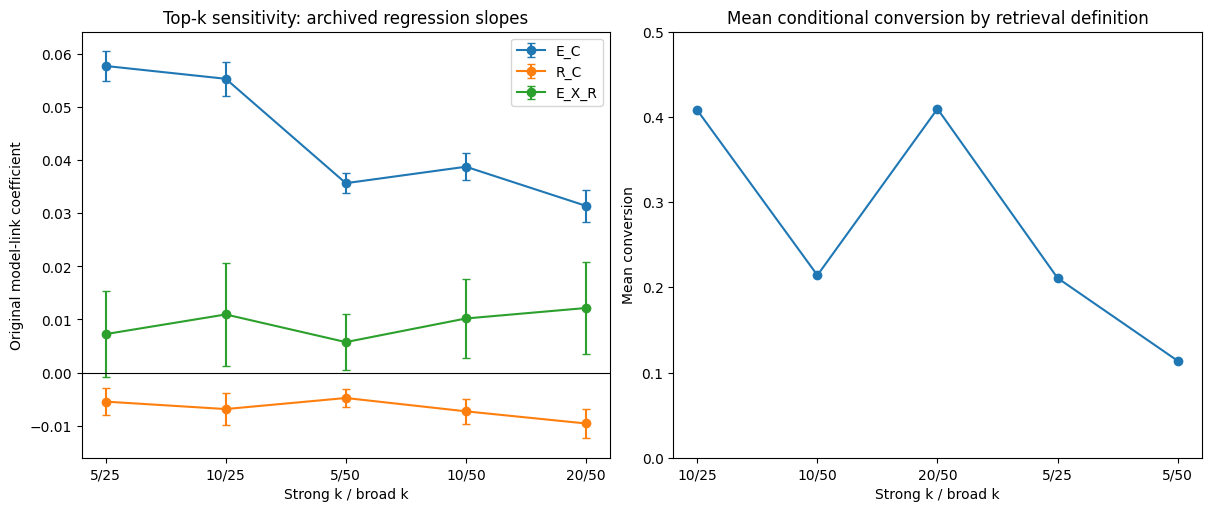

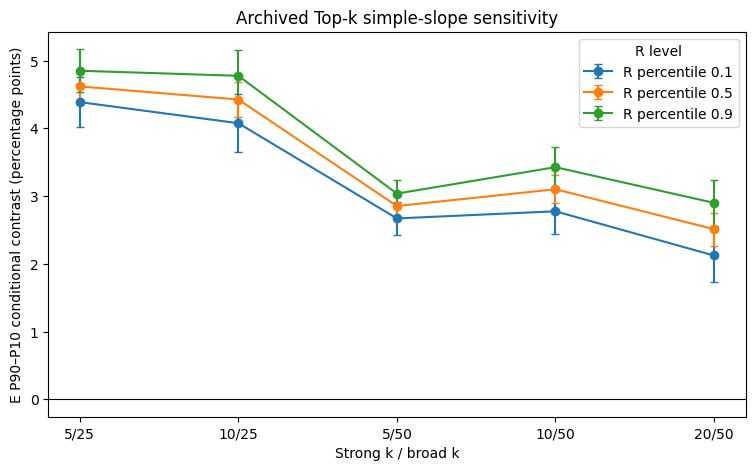

NEW multiverse experiment: 5 configurations; 15 coefficient records; 15 archived simple slopes.


,spec,E_C,E_X_R,R_C,focal_n,n_programs,mean_conversion,within_r2,interaction_sign,methodological_note
0,10/25,0.055326,0.010937,-0.006881,291511,4242,0.407756,0.010860,1.0,Different top-k definitions and (potentially) ...
1,10/50,0.038765,0.010180,-0.007310,347241,4244,0.214158,0.009773,1.0,Different top-k definitions and (potentially) ...
2,20/50,0.031393,0.012154,-0.009599,347241,4244,0.409448,0.005622,1.0,Different top-k definitions and (potentially) ...
3,5/25,0.057741,0.007238,-0.005479,291511,4242,0.210882,0.015959,1.0,Different top-k definitions and (potentially) ...
4,5/50,0.035665,0.005731,-0.004798,347241,4244,0.113723,0.014387,1.0,Different top-k definitions and (potentially) ...


In [28]:
# CELL 28 | Substantive experiment A: multiverse analysis of semantic k thresholds
# Consumes the actual archived Stage-31 coefficient and simple-slope files.
from pathlib import Path
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, hashlib

QQNEW = OUT / 'QQ_SUBSTANTIVE_MODELS_V3'
QQNEW.mkdir(parents=True,exist_ok=True)
STAGE31 = ROOT/'31_sensibilidade_diffusion_k'
assert STAGE31.is_dir(), f'Stage-31 source folder missing: {STAGE31}'

def resolve_unique(folder,name):
    hits=list(folder.rglob(name))
    if len(hits)!=1: raise RuntimeError(f'Expected one {name} under {folder}, found {len(hits)}: {hits[:5]}')
    return hits[0]

kc=pd.read_csv(resolve_unique(STAGE31,'sensibilidade_kK_coeficientes.csv'),encoding='utf-8-sig')
ks=pd.read_csv(resolve_unique(STAGE31,'sensibilidade_kK_simple_slopes.csv'),encoding='utf-8-sig')
req={'STRONG_K','BROAD_K','VARIABLE','BETA','SE','CI95_LOW','CI95_HIGH','P_VALUE','N','N_PPG','R2','MEAN_CONVERSION'}
assert req.issubset(kc.columns),sorted(req-set(kc.columns))
assert {'STRONG_K','BROAD_K','R_PERCENTILE','E_P10_P90_PP','CI95_LOW_PP','CI95_HIGH_PP','P_VALUE'}.issubset(ks.columns)
for t in (kc,ks):
    for col in ('STRONG_K','BROAD_K'):
        t[col]=pd.to_numeric(t[col],errors='raise').astype(int)
    t['spec']=t['STRONG_K'].astype(str)+'/'+t['BROAD_K'].astype(str)
assert (kc.STRONG_K<kc.BROAD_K).all() and (ks.STRONG_K<ks.BROAD_K).all()
assert not kc.duplicated(['spec','VARIABLE']).any()
assert not ks.duplicated(['spec','R_PERCENTILE']).any()
kc['ci_includes_zero']=(kc.CI95_LOW<=0)&(kc.CI95_HIGH>=0)
kc['ci_contains_beta']=(kc.CI95_LOW<=kc.BETA)&(kc.CI95_HIGH>=kc.BETA)
assert kc.ci_contains_beta.all()

# This is a multiverse of different eligible sets and conversion definitions.
# Coefficients across strong/broad k pairs do NOT estimate the same numerical outcome.
summary=(kc.pivot(index='spec',columns='VARIABLE',values='BETA')
    .reset_index().merge(kc.groupby('spec',as_index=False).agg(
       focal_n=('N','first'),n_programs=('N_PPG','first'),
       mean_conversion=('MEAN_CONVERSION','first'),within_r2=('R2','first')),on='spec'))
summary['interaction_sign']=np.sign(summary.get('E_X_R',np.nan))
summary['methodological_note']='Different top-k definitions and (potentially) different risk sets; no pooled coefficient'
summary.to_csv(QQNEW/'28_topk_multiverse_summary.csv',index=False)
kc.to_csv(QQNEW/'28_topk_coefficients_long.csv',index=False)
ks.to_csv(QQNEW/'28_topk_archived_slopes_long.csv',index=False)

fig,axs=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
for var in ['E_C','R_C','E_X_R']:
    sub=kc[kc.VARIABLE.eq(var)].sort_values(['BROAD_K','STRONG_K'])
    axs[0].errorbar(sub['spec'],sub.BETA,yerr=[sub.BETA-sub.CI95_LOW,sub.CI95_HIGH-sub.BETA],
                    marker='o',capsize=3,label=var)
axs[0].axhline(0,lw=0.8,color='black'); axs[0].set_title('Top-k sensitivity: archived regression slopes')
axs[0].set_xlabel('Strong k / broad k');axs[0].set_ylabel('Original model-link coefficient');axs[0].legend()
axs[1].plot(summary.spec,summary.mean_conversion,marker='o')
axs[1].set_ylim(0,max(0.5,summary.mean_conversion.max()*1.08))
axs[1].set_title('Mean conditional conversion by retrieval definition')
axs[1].set_xlabel('Strong k / broad k'); axs[1].set_ylabel('Mean conversion')
fig.savefig(QQNEW/'28_topk_multiverse.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)

slopefig,ax=plt.subplots(figsize=(9,5))
for pct,g in ks.groupby('R_PERCENTILE'):
    gg=g.sort_values(['BROAD_K','STRONG_K'])
    ax.errorbar(gg.spec,gg.E_P10_P90_PP,yerr=[gg.E_P10_P90_PP-gg.CI95_LOW_PP,
        gg.CI95_HIGH_PP-gg.E_P10_P90_PP],capsize=3,marker='o',label=f'R percentile {pct}')
ax.axhline(0,lw=0.8,color='black'); ax.set_ylabel('E P90–P10 conditional contrast (percentage points)')
ax.set_xlabel('Strong k / broad k');ax.legend(title='R level');ax.set_title('Archived Top-k simple-slope sensitivity')
slopefig.savefig(QQNEW/'28_topk_simple_slopes.png',dpi=180,bbox_inches='tight');plt.show();plt.close(slopefig)
print('NEW multiverse experiment: %s configurations; %s coefficient records; %s archived simple slopes.' %
      (kc.spec.nunique(),len(kc),len(ks)))
display(summary)


# Experiment B — translation estimand refit and marginal predictions

Cross-area share vs archival event count identity: max discrepancy = 2.9689005587307804e-08 rows > 1e-6 = 0
Fitting on 363,690 documents, 4,248 program clusters, 16 regressors.
Both models converged, elapsed seconds: 8.1


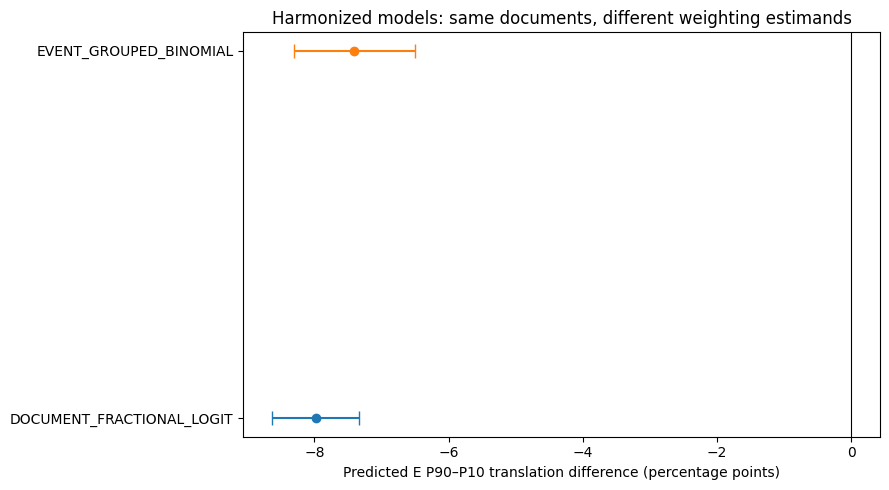

REFIT COMPLETE: archived models unchanged. New coefficient, prediction and design files saved.


,model,E_p10,E_p90,mean_predicted_E_p10,mean_predicted_E_p90,delta_probability,delta_percentage_points,delta_se_pp,ci95_low_pp,ci95_high_pp,N,estimand,inference
0,DOCUMENT_FRACTIONAL_LOGIT,0.079825,0.816832,0.440862,0.361029,-0.079833,-7.983279,0.329101,-8.628317,-7.338240,363690,"Average E P90-P10 standardized difference, con...",Within-model PPG-cluster sandwich delta method...
1,EVENT_GROUPED_BINOMIAL,0.079825,0.816832,0.451211,0.377176,-0.074035,-7.403490,0.462631,-8.310247,-6.496733,363690,"Average E P90-P10 standardized difference, con...",Within-model PPG-cluster sandwich delta method...


In [29]:
# CELL 29 | Substantive experiment B: refit TWO translation estimands on the SAME 363,690 focal documents
# New harmonized models (broad-area and year FE), NOT a reproduction of the archived FE models.
%pip -q install 'statsmodels>=0.14,<0.16'
import statsmodels.api as sm
from scipy.special import expit
from scipy.stats import norm
from time import perf_counter

required=['ID_TRABALHO','ANO','NM_GRANDE_AREA_CONHECIMENTO','CD_PROGRAMA',
          'E_PCT_AREA_ANO','R_PCT_AREA_ANO','T_CROSS_GRANDE_SHARE',
          'T_CROSS_GRANDE_HITS','D_HITS_3Y']
missing=[c for c in required if c not in frame.columns]
assert not missing, f'Cannot fit translation without: {missing}'
d=frame[required].copy()
for v in ['E_PCT_AREA_ANO','R_PCT_AREA_ANO','T_CROSS_GRANDE_SHARE','T_CROSS_GRANDE_HITS','D_HITS_3Y']:
    d[v]=pd.to_numeric(d[v],errors='coerce')
# Exact eligibility: a positive future TOP-10 uptake event and a recorded cross-area share.
d=d[d['D_HITS_3Y'].ge(1)&d['T_CROSS_GRANDE_SHARE'].notna()].copy()
assert len(d)==363690, f'Translation risk set unexpectedly changed: {len(d)} (expected 363690)'
assert d[['E_PCT_AREA_ANO','R_PCT_AREA_ANO','CD_PROGRAMA','ANO','NM_GRANDE_AREA_CONHECIMENTO']].notna().all().all()
assert d['T_CROSS_GRANDE_HITS'].between(0,d['D_HITS_3Y']).all()
assert d['T_CROSS_GRANDE_SHARE'].between(0,1).all()
# Critical identity: grouped binomial counts MUST have exactly this denominator.
ratio=d.T_CROSS_GRANDE_HITS / d.D_HITS_3Y
err=(ratio-d.T_CROSS_GRANDE_SHARE).abs()
print('Cross-area share vs archival event count identity: max discrepancy =',err.max(),
      'rows > 1e-6 =',int((err>1e-6).sum()))
if not (err<=1e-6).all():
    raise ValueError('STOP: T_CROSS_GRANDE_SHARE does not equal cross-grande events / D_HITS_3Y. '
                     'Recover the correct numerator/denominator and estimand before fitting.')

# Preprocessing is EXPLICIT and new. Not assumed equivalent to hidden original E_C/R_C.
d['E_C_QQ']=d.E_PCT_AREA_ANO-0.5
d['R_C_QQ']=d.R_PCT_AREA_ANO-0.5
d['E_X_R_QQ']=d.E_C_QQ*d.R_C_QQ
field=pd.get_dummies(d.NM_GRANDE_AREA_CONHECIMENTO.astype(str),prefix='area',drop_first=True,dtype=float)
year=pd.get_dummies(d.ANO.astype(str),prefix='year',drop_first=True,dtype=float)
X=pd.concat([d[['E_C_QQ','R_C_QQ','E_X_R_QQ']].reset_index(drop=True),
             field.reset_index(drop=True),year.reset_index(drop=True)],axis=1)
X.insert(0,'Intercept',1.0)
assert X.notna().all().all()
X_np=np.ascontiguousarray(X.to_numpy(dtype=np.float64))
prog=pd.factorize(d.CD_PROGRAMA.astype(str))[0]
num=d['T_CROSS_GRANDE_HITS'].to_numpy(np.float64)
den=d['D_HITS_3Y'].to_numpy(np.float64)
y_doc=d['T_CROSS_GRANDE_SHARE'].to_numpy(np.float64)
assert np.isfinite(X_np).all() and np.isfinite(y_doc).all() and np.all(den>=1)

print(f'Fitting on {len(d):,} documents, {len(np.unique(prog)):,} program clusters, {X_np.shape[1]} regressors.')
started=perf_counter()
# Model A: one document = one unit of analysis (fractional logit quasi-ML).
doc_fit=sm.GLM(y_doc,X_np,family=sm.families.Binomial()).fit(
    cov_type='cluster',cov_kwds={'groups':prog},maxiter=75,disp=0)
# Model B: events count as trials (grouped binomial), with the very same documents and covariates.
y_count=np.column_stack([num,den-num])
evt_fit=sm.GLM(y_count,X_np,family=sm.families.Binomial()).fit(
    cov_type='cluster',cov_kwds={'groups':prog},maxiter=75,disp=0)
assert doc_fit.converged and evt_fit.converged, 'Model fitting did not converge; do not export as complete'
print('Both models converged, elapsed seconds:',round(perf_counter()-started,1))

coefs=[]
fits={'DOCUMENT_FRACTIONAL_LOGIT':doc_fit,'EVENT_GROUPED_BINOMIAL':evt_fit}
for tag,fit in fits.items():
    for j,name in enumerate(X.columns):
        coefs.append({'model':tag,'term':name,'beta':float(fit.params[j]),'cluster_se':float(fit.bse[j]),
          'ci95_low':float(fit.conf_int()[j,0]),'ci95_high':float(fit.conf_int()[j,1]),
          'p_value':float(fit.pvalues[j]),'N':len(d),'N_ppg':len(np.unique(prog)),
          'model_status':'NEW_HARMONIZED_REFIT_NOT_ORIGINAL_REPLICATION'})
pd.DataFrame(coefs).to_csv(QQNEW/'29_translation_harmonized_coefficients.csv',index=False)

# Average counterfactual predictions: fix E at observed P10 vs P90 while retaining every
# document's observed R, field and year. Cluster-sandwich delta-method interval WITHIN model.
Elo,Ehi=np.nanquantile(d.E_PCT_AREA_ANO,[0.1,0.9])
Eix,Rix,ERix=[X.columns.get_loc(s) for s in ['E_C_QQ','R_C_QQ','E_X_R_QQ']]

def counterfactual(fit,e_value):
    xx=X_np.copy()
    ec=float(e_value)-0.5
    xx[:,Eix]=ec
    xx[:,ERix]=ec*xx[:,Rix]
    eta=xx @ np.asarray(fit.params)
    p=expit(eta)
    # Analytical delta-method gradient of the mean fitted probability.
    gradient=((p*(1-p))[:,None]*xx).mean(axis=0)
    return float(p.mean()),gradient

pred=[]
for tag,fit in fits.items():
    lo,glo=counterfactual(fit,Elo)
    hi,ghi=counterfactual(fit,Ehi)
    delta=hi-lo
    gdiff=ghi-glo
    cov=np.asarray(fit.cov_params())
    sed=float(np.sqrt(max(0.0,gdiff@cov@gdiff)))
    pred.append({'model':tag,'E_p10':float(Elo),'E_p90':float(Ehi),
        'mean_predicted_E_p10':lo,'mean_predicted_E_p90':hi,
        'delta_probability':delta,'delta_percentage_points':100*delta,
        'delta_se_pp':100*sed,'ci95_low_pp':100*(delta-1.96*sed),
        'ci95_high_pp':100*(delta+1.96*sed),'N':len(d),
        'estimand':'Average E P90-P10 standardized difference, conditional on observed R/area/year',
        'inference':'Within-model PPG-cluster sandwich delta method; no cross-model difference test'})
pred=pd.DataFrame(pred)
pred.to_csv(QQNEW/'29_translation_marginal_predictions.csv',index=False)

fig,ax=plt.subplots(figsize=(9,5))
for i,row in pred.iterrows():
    ax.errorbar(row.delta_percentage_points,i,xerr=[[row.delta_percentage_points-row.ci95_low_pp],
        [row.ci95_high_pp-row.delta_percentage_points]],fmt='o',capsize=5)
ax.set_yticks(range(len(pred)),pred.model.tolist())
ax.axvline(0,color='black',lw=.8)
ax.set_xlabel('Predicted E P90–P10 translation difference (percentage points)')
ax.set_title('Harmonized models: same documents, different weighting estimands')
fig.tight_layout();fig.savefig(QQNEW/'29_translation_marginal_effects.png',dpi=180);plt.show();plt.close(fig)

pd.DataFrame([{'check':'same_document_n','value':len(d)},
 {'check':'exact_count_share_identity_max_abs_error','value':float(err.max())},
 {'check':'cluster_count','value':len(np.unique(prog))},
 {'check':'predictor_coding','value':'E_C_QQ=E_PCT_AREA_ANO-0.5; R_C_QQ=R_PCT_AREA_ANO-0.5'},
 {'check':'fixed_effects','value':'broad area + focal year, dummy-encoded'},
 {'check':'comparison_limit','value':'No formal event-minus-document coefficient p-value'}]).to_csv(
 QQNEW/'29_translation_model_design_audit.csv',index=False)
print('REFIT COMPLETE: archived models unchanged. New coefficient, prediction and design files saved.')
display(pred)


# Experiment C — exposure/conversion decomposition

H50_LOG1P_EXPOSURE n= 459177 n_clusters= 4251 converged= OLS
H10_GIVEN_H50_FRACTIONAL n= 427649 n_clusters= 4250 converged= True


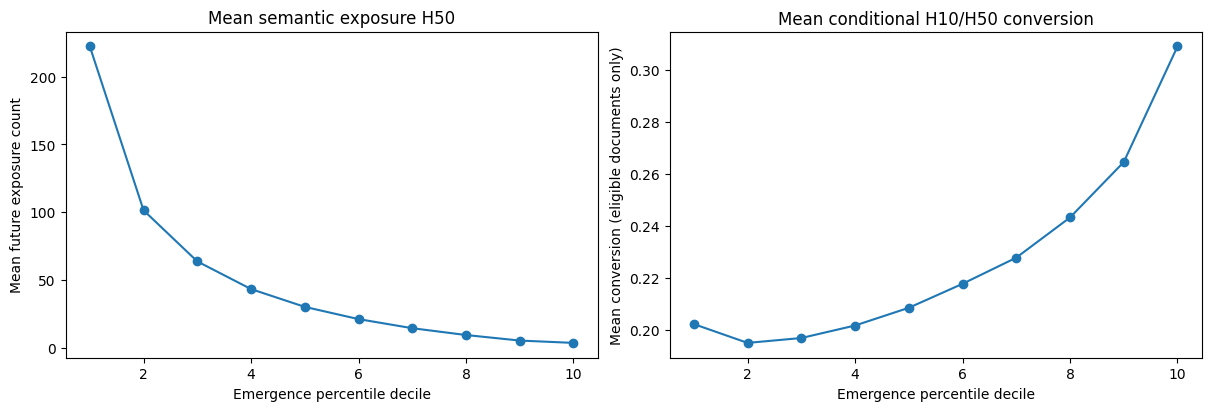

,model,term,beta,cluster_se,ci95_low,ci95_high,p_value,N,N_ppg,model_type
1,H50_LOG1P_EXPOSURE,E_C_QQ,-4.285246,0.028599,-4.341299,-4.229193,0.000000e+00,459177,4251,ols
2,H50_LOG1P_EXPOSURE,R_C_QQ,0.128424,0.014854,0.099310,0.157537,5.344878e-18,459177,4251,ols
3,H50_LOG1P_EXPOSURE,E_X_R_QQ,-0.101814,0.042104,-0.184338,-0.019291,1.560025e-02,459177,4251,ols
17,H10_GIVEN_H50_FRACTIONAL,E_C_QQ,0.576242,0.009331,0.557952,0.594531,0.000000e+00,427649,4250,binomial
18,H10_GIVEN_H50_FRACTIONAL,R_C_QQ,-0.069002,0.007594,-0.083886,-0.054117,1.026661e-19,427649,4250,binomial
19,H10_GIVEN_H50_FRACTIONAL,E_X_R_QQ,0.129273,0.027896,0.074597,0.183948,3.585864e-06,427649,4250,binomial


COMPLETED: two full-data association models, not claims of causality or criterion validation.


In [30]:
# CELL 30 | Substantive experiment C: exposure vs conditional conversion with one risk-set audit
# Uses exact H50/H10 conversion outcomes from frozen hubness dataset, not an assumed proxy.
import pyarrow.parquet as pq
assert 'hubness_dataset' in paths and paths['hubness_dataset'].exists()
colnames=set(pq.ParquetFile(paths['hubness_dataset']).schema.names)
needed=['ID_TRABALHO','H50_SEMANTIC_EXPOSURE_3Y','D10_GIVEN_H50_RATE']
assert all(v in colnames for v in needed),f'Hubness archival schema lacks: {[v for v in needed if v not in colnames]}'
h=pd.read_parquet(paths['hubness_dataset'],columns=needed)
assert len(h)==459177 and not h.ID_TRABALHO.duplicated().any(), 'Hubness source ID uniqueness failure'
assert not frame.ID_TRABALHO.duplicated().any(), 'MAIN44 ID uniqueness failure'
merge=frame[['ID_TRABALHO','E_PCT_AREA_ANO','R_PCT_AREA_ANO','ANO','CD_PROGRAMA',
             'NM_GRANDE_AREA_CONHECIMENTO']].merge(h,on='ID_TRABALHO',how='inner',validate='one_to_one')
assert len(merge)==459177, 'Hubness merge failed: different document universe'
merge['H50_SEMANTIC_EXPOSURE_3Y']=pd.to_numeric(merge.H50_SEMANTIC_EXPOSURE_3Y,errors='coerce')
merge['D10_GIVEN_H50_RATE']=pd.to_numeric(merge.D10_GIVEN_H50_RATE,errors='coerce')
assert int(merge.H50_SEMANTIC_EXPOSURE_3Y.gt(0).sum())==427649
risk=merge.H50_SEMANTIC_EXPOSURE_3Y.gt(0)
assert (merge.loc[~risk,'D10_GIVEN_H50_RATE'].isna()).all(), 'Zero exposure incorrectly has observed conversion'
assert merge.loc[risk,'D10_GIVEN_H50_RATE'].between(0,1).all()

# Stratified descriptive field-year profiles are direct computations on all records.
merge['E_decile']=pd.cut(merge.E_PCT_AREA_ANO,bins=np.linspace(0,1,11),include_lowest=True,
                        labels=list(range(1,11)))
profiles=merge.groupby('E_decile',observed=True).agg(
  n=('ID_TRABALHO','size'),h50_mean=('H50_SEMANTIC_EXPOSURE_3Y','mean'),
  h50_median=('H50_SEMANTIC_EXPOSURE_3Y','median'),
  exposure_positive_share=('H50_SEMANTIC_EXPOSURE_3Y',lambda x:float((x>0).mean())),
  conditional_conversion_mean=('D10_GIVEN_H50_RATE','mean'),
  conditional_conversion_nonmissing=('D10_GIVEN_H50_RATE','count')).reset_index()
profiles.to_csv(QQNEW/'30_exposure_conversion_deciles.csv',index=False)

# Full-data refits with area/year controls but WITHOUT asserting exact original fixed-effects.
# Exposure is a count; its mechanism differs from conditional conversion. Fit distinct models:
#    (a) log1p(H50) via OLS, PPG-cluster robust
#    (b) D10/H50 fraction via fractional-logit QMLE, conditional on H50>0.
import statsmodels.api as sm
import statsmodels.formula.api as smf

def make_design(df):
    x=df[['E_PCT_AREA_ANO','R_PCT_AREA_ANO']].copy().reset_index(drop=True)
    x.columns=['E_C_QQ','R_C_QQ'];x=x.astype(float)-0.5
    x['E_X_R_QQ']=x.E_C_QQ*x.R_C_QQ
    a=pd.get_dummies(df.NM_GRANDE_AREA_CONHECIMENTO.astype(str),drop_first=True,prefix='area',dtype=float).reset_index(drop=True)
    yr=pd.get_dummies(df.ANO.astype(str),drop_first=True,prefix='year',dtype=float).reset_index(drop=True)
    xx=pd.concat([x,a,yr],axis=1)
    xx.insert(0,'Intercept',1.0)
    return xx

runs=[]
for model_name,df,outcome,family in [
 ('H50_LOG1P_EXPOSURE',merge,'H50_SEMANTIC_EXPOSURE_3Y','ols'),
 ('H10_GIVEN_H50_FRACTIONAL',merge.loc[risk].copy(),'D10_GIVEN_H50_RATE','binomial')]:
    assert df[['E_PCT_AREA_ANO','R_PCT_AREA_ANO','CD_PROGRAMA','NM_GRANDE_AREA_CONHECIMENTO','ANO']].notna().all().all()
    xx=make_design(df)
    yy=pd.to_numeric(df[outcome],errors='raise').to_numpy()
    if family=='ols': yy=np.log1p(yy)
    assert np.isfinite(yy).all()
    clusters=pd.factorize(df.CD_PROGRAMA.astype(str))[0]
    if family=='ols':fit=sm.OLS(yy,xx.to_numpy()).fit(cov_type='cluster',cov_kwds={'groups':clusters})
    else:fit=sm.GLM(yy,xx.to_numpy(),family=sm.families.Binomial()).fit(
         cov_type='cluster',cov_kwds={'groups':clusters},maxiter=75,disp=0)
    for j,name in enumerate(xx.columns):
        runs.append({'model':model_name,'term':name,'beta':float(fit.params[j]),
           'cluster_se':float(fit.bse[j]),'ci95_low':float(fit.conf_int()[j,0]),
           'ci95_high':float(fit.conf_int()[j,1]),'p_value':float(fit.pvalues[j]),
           'N':len(df),'N_ppg':len(np.unique(clusters)),'model_type':family})
    print(model_name,'n=',len(df),'n_clusters=',len(np.unique(clusters)),'converged=',getattr(fit,'converged','OLS'))
    del xx,fit
result=pd.DataFrame(runs)
result.to_csv(QQNEW/'30_exposure_vs_conversion_harmonized_models.csv',index=False)

fig,axs=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
axs[0].plot(profiles.E_decile.astype(int),profiles.h50_mean,marker='o')
axs[0].set_title('Mean semantic exposure H50');axs[0].set_xlabel('Emergence percentile decile')
axs[0].set_ylabel('Mean future exposure count')
axs[1].plot(profiles.E_decile.astype(int),profiles.conditional_conversion_mean,marker='o')
axs[1].set_title('Mean conditional H10/H50 conversion')
axs[1].set_xlabel('Emergence percentile decile');axs[1].set_ylabel('Mean conversion (eligible documents only)')
fig.savefig(QQNEW/'30_exposure_conversion_deciles.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)
display(result[result.term.isin(['E_C_QQ','R_C_QQ','E_X_R_QQ'])])
print('COMPLETED: two full-data association models, not claims of causality or criterion validation.')


# Publication export and inference checks

In [31]:
# CELL 31 | Publication-oriented export and machine-verifiable gate for the THREE experiments
import json,hashlib,platform
from importlib.metadata import version
expected=['28_topk_multiverse_summary.csv','28_topk_coefficients_long.csv',
 '28_topk_archived_slopes_long.csv','28_topk_multiverse.png','28_topk_simple_slopes.png',
 '29_translation_harmonized_coefficients.csv','29_translation_marginal_predictions.csv',
 '29_translation_marginal_effects.png','29_translation_model_design_audit.csv',
 '30_exposure_conversion_deciles.csv','30_exposure_vs_conversion_harmonized_models.csv',
 '30_exposure_conversion_deciles.png']
missing=[p for p in expected if not (QQNEW/p).is_file()]
assert not missing,f'NOT COMPLETE: outputs missing: {missing}'
co=pd.read_csv(QQNEW/'29_translation_harmonized_coefficients.csv')
assert {'EVENT_GROUPED_BINOMIAL','DOCUMENT_FRACTIONAL_LOGIT'}==set(co.model)
assert co[co.term.eq('E_X_R_QQ')].shape[0]==2
b=pd.read_csv(QQNEW/'30_exposure_vs_conversion_harmonized_models.csv')
assert {'H50_LOG1P_EXPOSURE','H10_GIVEN_H50_FRACTIONAL'}==set(b.model)
assert (co.ci95_low<=co.beta).all() and (co.ci95_high>=co.beta).all()
assert (b.ci95_low<=b.beta).all() and (b.ci95_high>=b.beta).all()

def hashfile(p):
    hh=hashlib.sha256()
    with open(p,'rb') as f:
        for chunk in iter(lambda:f.read(4*1024*1024),b''):hh.update(chunk)
    return hh.hexdigest()
files=[{'file':p,'bytes':(QQNEW/p).stat().st_size,'sha256':hashfile(QQNEW/p)} for p in expected]
meta={'study':'Beyond disruption scores: Epistemic Transition Signatures',
 'target_journal':'Quality & Quantity','timestamp_utc':datetime.now(timezone.utc).isoformat(),
 'status':'NEW ANALYSES COMPLETED AFTER AUDITS; NOT IDENTICAL REPLICATION OF ORIGINAL FE MODELS',
 'sample_ETS':459177,'model_formula':'E_C_QQ + R_C_QQ + E_C_QQ:R_C_QQ + broad_field_dummies + focal_year_dummies',
 'parameterization':'E_C_QQ=E_PCT_AREA_ANO-0.5; R_C_QQ=R_PCT_AREA_ANO-0.5',
 'standard_errors':'cluster sandwich by CD_PROGRAMA',
 'limitations':['No causal interpretation','No formal inter-estimand effect-difference hypothesis test',
 'No expert criterion validity','Not identical original high-dimensional fixed effects'],
 'versions':{x:version(x) for x in ('numpy','pandas','statsmodels','scipy','pyarrow')},
 'artifacts':files}
(QQNEW/'31_publication_analysis_manifest.json').write_text(json.dumps(meta,ensure_ascii=False,indent=2),encoding='utf-8')
print('PASS: substantive analysis complete; written artifacts:',len(files)+1)
print('Folder:',QQNEW)
print('No original dataset or archived model coefficients were overwritten.')


PASS: substantive analysis complete; written artifacts: 13
Folder: /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026/QQ_SUBSTANTIVE_MODELS_V3
No original dataset or archived model coefficients were overwritten.


In [32]:
# CELL 32 | Joint cluster-sandwich inference: event-vs-document translation difference
# The same documents/clusters and regressors make paired influence-function inference possible.
import numpy as np, pandas as pd, json
from pathlib import Path
from scipy.special import expit
from scipy.stats import norm
from datetime import datetime, timezone
import matplotlib.pyplot as plt

Q4=Path(QQNEW).parent/'QQ_JOINT_INFERENCE_V4'; Q4.mkdir(parents=True,exist_ok=True)
assert len(d)==363690 and len(X_np)==len(d)==len(prog)
assert doc_fit.converged and evt_fit.converged
Xmat=np.asarray(X_np,dtype=np.float64)
assert np.isfinite(Xmat).all()
n,p=Xmat.shape
G=len(np.unique(prog));assert G>100
Eix,Rix,ERix=[X.columns.get_loc(s) for s in ('E_C_QQ','R_C_QQ','E_X_R_QQ')]
assert np.allclose(Xmat[:,ERix],Xmat[:,Eix]*Xmat[:,Rix],atol=1e-10)
e_lo,e_hi=np.quantile(d.E_PCT_AREA_ANO.to_numpy(),[.1,.9])

# Group-level estimating-equation score and inverse bread for each binomial GLM.
# Fractional-logit is QMLE: the sandwich is computed from score equations.
# For grouped-binomial, each focal document contributes its count of events/trials.
def score_influence(fitted, response, trials):
    eta=Xmat@np.asarray(fitted.params,dtype=float)
    mu=expit(eta)
    perrow=(response-trials*mu)
    sums=np.zeros((G,p),dtype=float)
    np.add.at(sums,prog,Xmat*perrow[:,None])
    w=trials*mu*(1-mu)
    bread=Xmat.T@(Xmat*w[:,None]);inv=np.linalg.pinv(bread,hermitian=True,rcond=1e-12)
    return sums@inv.T

assert (d.D_HITS_3Y.to_numpy(dtype=float)>0).all()
Sdoc=score_influence(doc_fit,d.T_CROSS_GRANDE_SHARE.to_numpy(dtype=float),np.ones(n))
Sevt=score_influence(evt_fit,d.T_CROSS_GRANDE_HITS.to_numpy(dtype=float),d.D_HITS_3Y.to_numpy(dtype=float))
correction=(G/(G-1))*((n-1)/(n-p))
Vdoc=correction*(Sdoc.T@Sdoc)
Vevt=correction*(Sevt.T@Sevt)
Vcross=correction*(Sdoc.T@Sevt)
# Guard: estimated within-model covariance must reproduce statsmodels' cluster fit.
relerrors=[]
for empirical,f in [(Vdoc,doc_fit),(Vevt,evt_fit)]:
    ref=np.asarray(f.cov_params()); scale=np.maximum(abs(ref),1e-10)
    diag_rel=np.max(abs(np.diag(empirical)-np.diag(ref))/np.diag(ref))
    relerrors.append(float(diag_rel))
    assert diag_rel < .03, f'Cross-covariance reconstruction incompatible with fitted clustered SE: {diag_rel:.3%}'

def standardized_delta(fit,low,high,r_fixed=None):
    # Average prediction over observed field/year controls; R optionally fixed to a preset quantile.
    def at(e):
        xx=Xmat.copy();ec=e-.5;xx[:,Eix]=ec
        if r_fixed is not None: xx[:,Rix]=r_fixed-.5
        xx[:,ERix]=xx[:,Eix]*xx[:,Rix]
        pr=expit(xx@fit.params)
        grad=(xx*(pr*(1-pr))[:,None]).mean(axis=0)
        return float(pr.mean()),grad
    m0,g0=at(low);m1,g1=at(high)
    return m1-m0,g1-g0,m0,m1

doc_diff,gdoc,doc_p10,doc_p90=standardized_delta(doc_fit,e_lo,e_hi)
evt_diff,gevt,evt_p10,evt_p90=standardized_delta(evt_fit,e_lo,e_hi)
paired_diff=evt_diff-doc_diff
pair_var=float(gevt@Vevt@gevt+gdoc@Vdoc@gdoc-2*gdoc@Vcross@gevt)
assert pair_var>=-1e-12, f'Negative variance signals covariance defect: {pair_var}'
se=np.sqrt(max(0,pair_var));z=paired_diff/se if se else np.nan
pval=2*norm.sf(abs(z)) if se else np.nan
out=pd.DataFrame([{'comparison':'EVENT minus DOCUMENT; E P90-P10 effect',
 'event_delta_pp':100*evt_diff,'document_delta_pp':100*doc_diff,'difference_pp':100*paired_diff,
 'paired_se_pp':100*se,'paired_ci95_low_pp':100*(paired_diff-1.96*se),
 'paired_ci95_high_pp':100*(paired_diff+1.96*se),'p_value':pval,
 'N':n,'N_ppg':G,'max_model_covariance_relative_error':max(relerrors),
 'method':'Joint influence-function PPG-cluster sandwich; same focal documents, separate estimands'}])
out.to_csv(Q4/'32_paired_translation_estimand_difference.csv',index=False)
pd.DataFrame({'model':['DOCUMENT','EVENT'],'p10_mean':[doc_p10,evt_p10],
 'p90_mean':[doc_p90,evt_p90],'delta_pp':[100*doc_diff,100*evt_diff]}).to_csv(Q4/'32_translation_predictions.csv',index=False)
print('PAIRED comparison (event minus document, percentage points):')
display(out)


PAIRED comparison (event minus document, percentage points):


,comparison,event_delta_pp,document_delta_pp,difference_pp,paired_se_pp,paired_ci95_low_pp,paired_ci95_high_pp,p_value,N,N_ppg,max_model_covariance_relative_error,method
0,EVENT minus DOCUMENT; E P90-P10 effect,-7.40349,-7.983279,0.579788,0.303855,-0.015768,1.175344,0.056377,363690,4248,3.181402e-14,Joint influence-function PPG-cluster sandwich;...


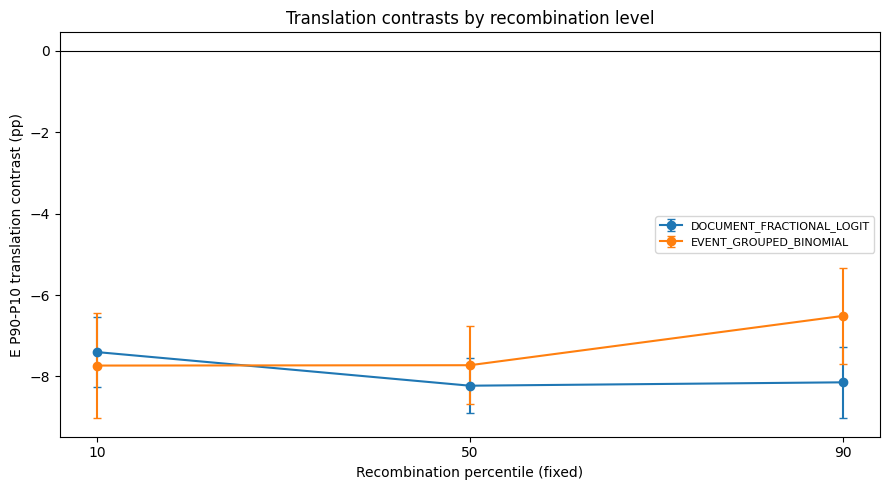

,model,R_percentile,R_value,E_p10,E_p90,mean_predicted_low_E,mean_predicted_high_E,E_contrast_pp,SE_pp,CI95_low_pp,CI95_high_pp,N,N_ppg,standardization
0,DOCUMENT_FRACTIONAL_LOGIT,10,0.103545,0.079825,0.816832,0.322736,0.248719,-7.401703,0.442793,-8.269577,-6.533829,363690,4248,Fixed R percentile; average over observed area...
1,DOCUMENT_FRACTIONAL_LOGIT,50,0.487456,0.079825,0.816832,0.436802,0.354529,-8.227317,0.343368,-8.900319,-7.554315,363690,4248,Fixed R percentile; average over observed area...
2,DOCUMENT_FRACTIONAL_LOGIT,90,0.896108,0.079825,0.816832,0.566818,0.485374,-8.144401,0.446350,-9.019247,-7.269555,363690,4248,Fixed R percentile; average over observed area...
3,EVENT_GROUPED_BINOMIAL,10,0.103545,0.079825,0.816832,0.330193,0.252866,-7.732724,0.661326,-9.028922,-6.436526,363690,4248,Fixed R percentile; average over observed area...
4,EVENT_GROUPED_BINOMIAL,50,0.487456,0.079825,0.816832,0.447420,0.370179,-7.724070,0.490082,-8.684631,-6.763510,363690,4248,Fixed R percentile; average over observed area...
5,EVENT_GROUPED_BINOMIAL,90,0.896108,0.079825,0.816832,0.579606,0.514472,-6.513421,0.596454,-7.682471,-5.344370,363690,4248,Fixed R percentile; average over observed area...


In [33]:
# CELL 33 | Conditional translation surfaces at R P10/P50/P90 with clustered delta CIs
rlevels=np.quantile(d.R_PCT_AREA_ANO.to_numpy(dtype=float),[.1,.5,.9])
rows=[]
for tag,f,V in [('DOCUMENT_FRACTIONAL_LOGIT',doc_fit,Vdoc),('EVENT_GROUPED_BINOMIAL',evt_fit,Vevt)]:
  for q,r in zip([10,50,90],rlevels):
    delta,g,mu_low,mu_high=standardized_delta(f,e_lo,e_hi,r_fixed=float(r))
    se2=float(g@V@g)
    assert se2>=-1e-12
    sd=np.sqrt(max(se2,0))
    rows.append({'model':tag,'R_percentile':q,'R_value':r,'E_p10':e_lo,'E_p90':e_hi,
      'mean_predicted_low_E':mu_low,'mean_predicted_high_E':mu_high,
      'E_contrast_pp':100*delta,'SE_pp':100*sd,
      'CI95_low_pp':100*(delta-1.96*sd),'CI95_high_pp':100*(delta+1.96*sd),
      'N':n,'N_ppg':G,'standardization':'Fixed R percentile; average over observed area-year'} )
surface=pd.DataFrame(rows)
surface.to_csv(Q4/'33_translation_emergence_by_recombination.csv',index=False)
fig,ax=plt.subplots(figsize=(9,5))
for name,s in surface.groupby('model'):
  ax.errorbar(s.R_percentile,s.E_contrast_pp,
    yerr=[s.E_contrast_pp-s.CI95_low_pp,s.CI95_high_pp-s.E_contrast_pp],
    fmt='o-',capsize=3,label=name)
ax.axhline(0,c='black',lw=.8);ax.set_xticks([10,50,90]);ax.set_xlabel('Recombination percentile (fixed)')
ax.set_ylabel('E P90-P10 translation contrast (pp)')
ax.set_title('Translation contrasts by recombination level');ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(Q4/'33_translation_interaction_surface.png',dpi=190);plt.show();plt.close(fig)
display(surface)


,model,N,N_ppg,E_p10,E_p90,predicted_at_E_p10,predicted_at_E_p90,difference,SE,CI95_low,CI95_high,units,limitation
0,H50_LOG1P_EXPOSURE,459177,4251,0.100279,0.900291,96.186854,2.150310,-94.036544,1.996549,-97.949781,-90.123308,expm1 of predicted log1p(H50); model-scale index,OLS retransformation without smearing is NOT e...
1,H10_GIVEN_H50_FRACTIONAL,427649,4250,0.093417,0.860804,0.185890,0.261995,7.610507,0.126233,7.363091,7.857923,percentage points of conditional conversion,Conditional on H50>0


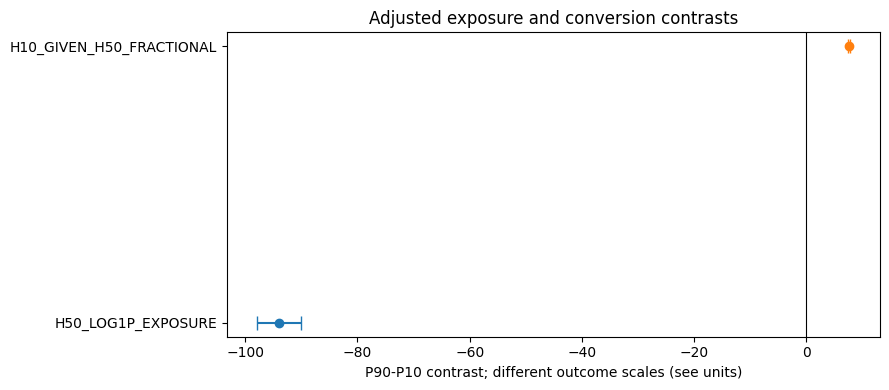

DO NOT compare coefficient magnitudes across outcomes/scales. No causal interpretation.


In [34]:
# CELL 34 | Refit exposure and conditional conversion with adjusted P90-P10 contrasts
# Regenerate the two clearly defined models to make this cell self-contained within the live lab.
import statsmodels.api as sm
from scipy.special import expit
assert 'merge' in globals() and 'make_design' in globals()
assert len(merge)==459177
conditional=merge.loc[merge.H50_SEMANTIC_EXPOSURE_3Y.gt(0)].copy()
assert len(conditional)==427649
analysis=[]
for model_name,ds,outcome,mode in [
 ('H50_LOG1P_EXPOSURE',merge,'H50_SEMANTIC_EXPOSURE_3Y','ols_log1p'),
 ('H10_GIVEN_H50_FRACTIONAL',conditional,'D10_GIVEN_H50_RATE','fractional_logit')]:
  xx=make_design(ds);xxv=np.asarray(xx,dtype=float)
  yy=ds[outcome].to_numpy(dtype=float)
  if mode=='ols_log1p': yy=np.log1p(yy)
  grp=pd.factorize(ds.CD_PROGRAMA.astype(str))[0]
  if mode=='ols_log1p':fit=sm.OLS(yy,xxv).fit(cov_type='cluster',cov_kwds={'groups':grp})
  else:fit=sm.GLM(yy,xxv,family=sm.families.Binomial()).fit(
     cov_type='cluster',cov_kwds={'groups':grp},maxiter=90,disp=0)
  cov=np.asarray(fit.cov_params())
  ix={term:list(xx.columns).index(term) for term in ['E_C_QQ','R_C_QQ','E_X_R_QQ']}
  el,eh=np.quantile(ds.E_PCT_AREA_ANO,[.1,.9]);preds=[]
  for e in (el,eh):
    cf=xxv.copy();ec=e-.5;cf[:,ix['E_C_QQ']]=ec
    cf[:,ix['E_X_R_QQ']]=ec*cf[:,ix['R_C_QQ']]
    z=cf@fit.params
    if mode=='fractional_logit':
      pr=expit(z);grad=(cf*(pr*(1-pr))[:,None]).mean(axis=0)
    else:
      # BACK-TRANSFORMED FITTED LOG-EXPOSURE, not the arithmetic mean E[H50|x].
      pr=np.expm1(z);grad=(cf*np.exp(z)[:,None]).mean(axis=0)
    preds.append((float(pr.mean()),grad))
  diff=preds[1][0]-preds[0][0];gradient=preds[1][1]-preds[0][1]
  se=np.sqrt(max(0,float(gradient@cov@gradient)))
  is_rate=mode=='fractional_logit';mult=100 if is_rate else 1
  analysis.append({'model':model_name,'N':len(ds),'N_ppg':len(np.unique(grp)),
   'E_p10':el,'E_p90':eh,'predicted_at_E_p10':preds[0][0],
   'predicted_at_E_p90':preds[1][0],'difference':mult*diff,
   'SE':mult*se,'CI95_low':mult*(diff-1.96*se),'CI95_high':mult*(diff+1.96*se),
   'units':'percentage points of conditional conversion' if is_rate else 'expm1 of predicted log1p(H50); model-scale index',
   'limitation':'OLS retransformation without smearing is NOT expected raw count' if not is_rate else 'Conditional on H50>0'})
  del xx,xxv,fit
contrasts=pd.DataFrame(analysis)
contrasts.to_csv(Q4/'34_exposure_conversion_adjusted_contrasts.csv',index=False)
display(contrasts)
fig,ax=plt.subplots(figsize=(9,4));labels=[]
for _,r in contrasts.iterrows():
 labels.append(r['model']);ax.errorbar(r['difference'],len(labels)-1,xerr=[[r['difference']-r['CI95_low']],[r['CI95_high']-r['difference']]],fmt='o',capsize=5)
ax.set_yticks(range(len(labels)),labels);ax.axvline(0,c='black',lw=.8)
ax.set_xlabel('P90-P10 contrast; different outcome scales (see units)')
ax.set_title('Adjusted exposure and conversion contrasts');fig.tight_layout()
fig.savefig(Q4/'34_exposure_conversion_adjusted_contrasts.png',dpi=190);plt.show();plt.close(fig)
print('DO NOT compare coefficient magnitudes across outcomes/scales. No causal interpretation.')


In [35]:
# CELL 35 | Complete publication tables, uncertainty gates, and V4 audit manifest
from hashlib import sha256
expected=['32_paired_translation_estimand_difference.csv','32_translation_predictions.csv',
 '33_translation_emergence_by_recombination.csv','33_translation_interaction_surface.png',
 '34_exposure_conversion_adjusted_contrasts.csv','34_exposure_conversion_adjusted_contrasts.png']
assert all((Q4/x).is_file() for x in expected)
paired=pd.read_csv(Q4/expected[0]);surf=pd.read_csv(Q4/expected[2]);xc=pd.read_csv(Q4/expected[4])
assert len(paired)==1 and len(surf)==6 and len(xc)==2
assert ((surf.CI95_low_pp<=surf.E_contrast_pp)&(surf.E_contrast_pp<=surf.CI95_high_pp)).all()
assert ((xc.CI95_low<=xc.difference)&(xc.difference<=xc.CI95_high)).all()
assert pd.notna(paired.p_value.iloc[0])
readme = 'Quality & Quantity ETS V4: Paired PPG-cluster inference; noncausal; exposure model is expm1 of fitted log1p(H50), not expected count. New centered percentile predictors and broad-area/year controls. Not archival replication.'
(Q4/'35_interpretation_notes.md').write_text(readme,encoding='utf-8')
rows=[]
for name in expected+['35_interpretation_notes.md']:
 path=Q4/name
 rows.append({'filename':name,'size_bytes':path.stat().st_size,'sha256':sha256(path.read_bytes()).hexdigest()})
pd.DataFrame(rows).to_csv(Q4/'35_sha256_manifest.csv',index=False)
info={'journal':'Quality & Quantity','stage':'ETS V4 joint and marginal inference',
 'time_utc':datetime.now(timezone.utc).isoformat(),'n_translation':363690,
 'inference':'PPG-cluster sandwich, paired cross-model covariance for event/document difference',
 'scope':'new harmonized refits, NOT replication of original archived models',
 'files':expected+['35_interpretation_notes.md','35_sha256_manifest.csv']}
(Q4/'35_run_manifest.json').write_text(json.dumps(info,indent=2),encoding='utf-8')
print('COMPLETED: V4 substantive analyses; files:',len(info['files'])+1,'OUTPUT:',Q4)
print('Review the paired event-vs-document difference and its CI before making a robustness claim.')


COMPLETED: V4 substantive analyses; files: 9 OUTPUT: /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026/QQ_JOINT_INFERENCE_V4
Review the paired event-vs-document difference and its CI before making a robustness claim.


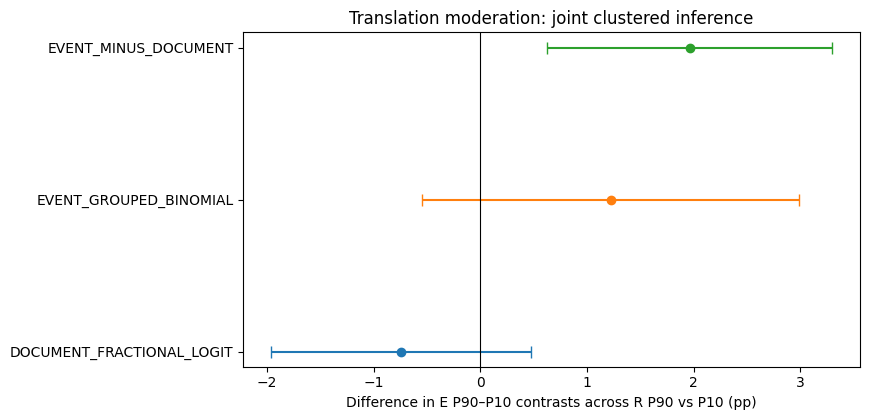

NEW joint moderation tests; inference is based on same-sample PPG-cluster sandwich.


,comparison,model,R_p10,R_p90,E_effect_at_R_p10_pp,E_effect_at_R_p90_pp,moderation_pp,cluster_se_pp,ci95_low_pp,ci95_high_pp,p_value,N,N_ppg,interpretation
0,Within-model moderation: R P90 minus R P10,DOCUMENT_FRACTIONAL_LOGIT,0.103545,0.896108,-7.401703,-8.144401,-0.742698,0.620933,-1.959727,0.474331,0.231658,363690,4248,Associational probability-scale contrast; PPG-...
1,Within-model moderation: R P90 minus R P10,EVENT_GROUPED_BINOMIAL,0.103545,0.896108,-7.732724,-6.513421,1.219303,0.899394,-0.543509,2.982115,0.175196,363690,4248,Associational probability-scale contrast; PPG-...
2,Paired event minus document moderation,EVENT_MINUS_DOCUMENT,0.103545,0.896108,NaN,NaN,1.962001,0.680293,0.628626,3.295376,0.003926,363690,4248,Paired PPG-cluster influence-function covarian...


In [36]:
# CELL 36 | Translation moderation: paired inference for the change in E contrasts across R levels
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from pathlib import Path
from scipy.stats import norm
from datetime import datetime, timezone
assert all(k in globals() for k in ['Q4','d','doc_fit','evt_fit','Vdoc','Vevt','Vcross','standardized_delta','e_lo','e_hi']), 'Run Cells 29 and 32–35 first.'
Q5=Path(Q4).parent/'QQ_SUBSTANTIVE_V5'; Q5.mkdir(parents=True,exist_ok=True)
assert len(d)==363690 and all(f.converged for f in [doc_fit,evt_fit])
r10,r90=np.quantile(d.R_PCT_AREA_ANO.to_numpy(dtype=float),[.1,.9])
rows=[]; store={}
for name,fit,cov in [('DOCUMENT_FRACTIONAL_LOGIT',doc_fit,Vdoc),('EVENT_GROUPED_BINOMIAL',evt_fit,Vevt)]:
  lo,glo,*_=standardized_delta(fit,e_lo,e_hi,r_fixed=float(r10))
  hi,ghi,*_=standardized_delta(fit,e_lo,e_hi,r_fixed=float(r90))
  gap=hi-lo; grad=ghi-glo
  v=float(grad@cov@grad);assert v>=-1e-12
  se=np.sqrt(max(v,0.0));z=gap/se if se>0 else np.nan
  store[name]=(gap,grad)
  rows.append({'comparison':'Within-model moderation: R P90 minus R P10','model':name,
      'R_p10':float(r10),'R_p90':float(r90),
      'E_effect_at_R_p10_pp':100*lo,'E_effect_at_R_p90_pp':100*hi,
      'moderation_pp':100*gap,'cluster_se_pp':100*se,
      'ci95_low_pp':100*(gap-1.96*se),'ci95_high_pp':100*(gap+1.96*se),
      'p_value':float(2*norm.sf(abs(z))) if np.isfinite(z) else np.nan,
      'N':len(d),'N_ppg':len(np.unique(prog)),
      'interpretation':'Associational probability-scale contrast; PPG-cluster sandwich'})
base,gb=store['DOCUMENT_FRACTIONAL_LOGIT'];other,go=store['EVENT_GROUPED_BINOMIAL']
difference=other-base
vv=float(go@Vevt@go+gb@Vdoc@gb-2*gb@Vcross@go)
assert vv>=-1e-12, f'Negative joint variance: {vv}'
sd=np.sqrt(max(vv,0.0));z=difference/sd if sd else np.nan
rows.append({'comparison':'Paired event minus document moderation','model':'EVENT_MINUS_DOCUMENT',
    'R_p10':float(r10),'R_p90':float(r90),'E_effect_at_R_p10_pp':np.nan,'E_effect_at_R_p90_pp':np.nan,
    'moderation_pp':100*difference,'cluster_se_pp':100*sd,
    'ci95_low_pp':100*(difference-1.96*sd),'ci95_high_pp':100*(difference+1.96*sd),
    'p_value':float(2*norm.sf(abs(z))) if np.isfinite(z) else np.nan,'N':len(d),
    'N_ppg':len(np.unique(prog)),
    'interpretation':'Paired PPG-cluster influence-function covariance; tests moderation difference'})
moderation=pd.DataFrame(rows)
moderation.to_csv(Q5/'36_translation_moderation_joint_inference.csv',index=False)
fig,ax=plt.subplots(figsize=(8.8,4.3))
for i,x in moderation.iterrows():
  y=x.moderation_pp;ax.errorbar(y,i,xerr=[[y-x.ci95_low_pp],[x.ci95_high_pp-y]],fmt='o',capsize=4)
ax.set_yticks(np.arange(len(moderation)),moderation.model.tolist());ax.axvline(0,lw=.8,color='black')
ax.set_xlabel('Difference in E P90–P10 contrasts across R P90 vs P10 (pp)')
ax.set_title('Translation moderation: joint clustered inference');fig.tight_layout()
fig.savefig(Q5/'36_translation_moderation_joint_inference.png',dpi=190);plt.show();plt.close(fig)
print('NEW joint moderation tests; inference is based on same-sample PPG-cluster sandwich.')
display(moderation)


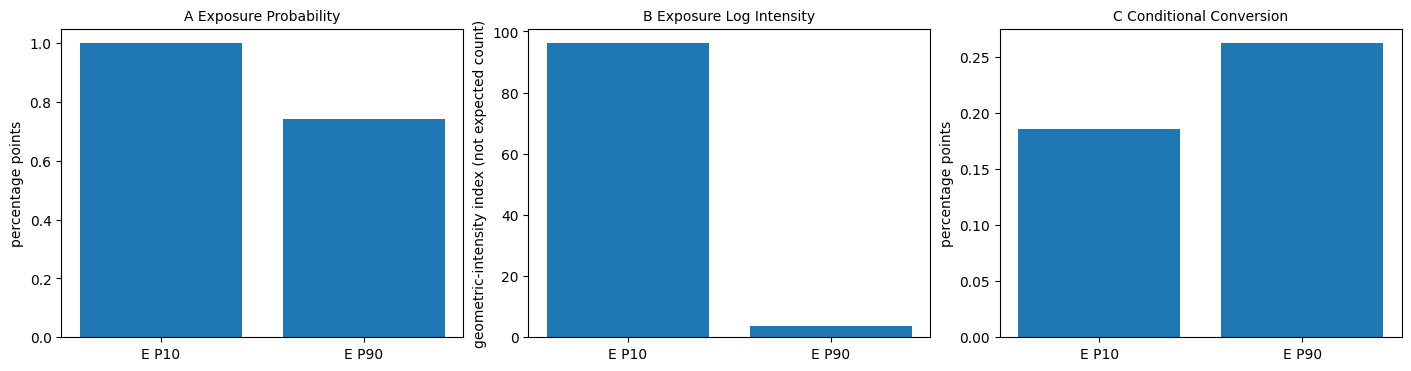

Two-part decomposition: exposure probability, positive exposure intensity, conditional conversion.


,model,N,N_ppg,E_p10,E_p90,prediction_E_p10,prediction_E_p90,contrast,cluster_se,ci95_low,ci95_high,unit,risk_set,caution
0,A_EXPOSURE_PROBABILITY,459177,4251,0.100279,0.900291,0.999760,0.741823,-25.793721,0.285990,-26.354261,-25.233180,percentage points,all focals,Not a causal contrast; omitted FE at PPG level...
1,B_EXPOSURE_LOG_INTENSITY,427649,4250,0.093417,0.860804,96.068279,3.646201,-92.422079,1.874256,-96.095620,-88.748537,geometric-intensity index (not expected count),H50-positive focals,Not a causal contrast; omitted FE at PPG level...
2,C_CONDITIONAL_CONVERSION,427649,4250,0.093417,0.860804,0.185890,0.261995,7.610507,0.126233,7.363091,7.857923,percentage points,H50-positive focals,Not a causal contrast; omitted FE at PPG level...


In [37]:
# CELL 37 | TWO-PART semantic exposure decomposition plus conditional conversion
# Part A: model the binary event H50>0 on ALL 459,177 focals (binomial GLM).
# Part B: model log(H50) among exposed documents only (OLS on log intensity).
# Part C: use the archived exact conversion rate among exposed focals (fractional logit).
import statsmodels.api as sm
from scipy.special import expit
assert all(k in globals() for k in ['merge','make_design','Q5']), 'Run Cells 30 and 36 first.'
assert len(merge)==459177
allf=merge.copy(); allf['EXPOSED_H50']=(allf.H50_SEMANTIC_EXPOSURE_3Y>0).astype(int)
posf=allf.loc[allf.EXPOSED_H50.eq(1)].copy()
assert len(posf)==427649
assert (posf.H50_SEMANTIC_EXPOSURE_3Y>0).all()
assert posf.D10_GIVEN_H50_RATE.between(0,1).all()
config=[('A_EXPOSURE_PROBABILITY',allf,'EXPOSED_H50','binary'),
        ('B_EXPOSURE_LOG_INTENSITY',posf,'H50_SEMANTIC_EXPOSURE_3Y','log_intensity'),
        ('C_CONDITIONAL_CONVERSION',posf,'D10_GIVEN_H50_RATE','fractional')]
results=[];preds=[]
for name,df,target,kind in config:
  design=make_design(df);cols=list(design.columns);matrix=np.asarray(design,dtype=np.float64)
  codes=pd.factorize(df.CD_PROGRAMA.astype(str))[0]
  y=df[target].to_numpy(dtype=np.float64)
  if kind=='log_intensity':
    fit=sm.OLS(np.log(y),matrix).fit(cov_type='cluster',cov_kwds={'groups':codes})
  else:
    fit=sm.GLM(y,matrix,family=sm.families.Binomial()).fit(
      cov_type='cluster',cov_kwds={'groups':codes},maxiter=90,disp=0)
    assert fit.converged, f'{name} convergence failed'
  V=np.asarray(fit.cov_params());params=np.asarray(fit.params)
  ix={v:cols.index(v) for v in ['E_C_QQ','R_C_QQ','E_X_R_QQ']}
  for term in ['E_C_QQ','R_C_QQ','E_X_R_QQ']:
    j=ix[term];results.append({'model':name,'term':term,'beta':params[j],
     'cluster_se':float(fit.bse[j]),'ci95_low':float(fit.conf_int()[j,0]),
     'ci95_high':float(fit.conf_int()[j,1]),'p_value':float(fit.pvalues[j]),
     'N':len(df),'N_ppg':len(np.unique(codes)),'response_scale':kind})
  low,high=np.quantile(df.E_PCT_AREA_ANO,[.1,.9])
  cf_out=[]
  for e in [low,high]:
    xx=matrix.copy();ec=float(e)-.5;xx[:,ix['E_C_QQ']]=ec
    xx[:,ix['E_X_R_QQ']]=ec*xx[:,ix['R_C_QQ']]
    eta=xx@params
    if kind=='log_intensity':
      # This is the geometric-intensity index, NOT E[H50 | H50>0, X].
      mu=np.exp(eta);grad=np.mean(xx*mu[:,None],axis=0)
    else:
      mu=expit(eta);grad=np.mean(xx*(mu*(1-mu))[:,None],axis=0)
    cf_out.append((float(mu.mean()),grad))
  delta=cf_out[1][0]-cf_out[0][0];g=cf_out[1][1]-cf_out[0][1]
  variance=float(g@V@g);assert variance>=-1e-12
  se=np.sqrt(max(variance,0));factor=100 if kind!='log_intensity' else 1
  preds.append({'model':name,'N':len(df),'N_ppg':len(np.unique(codes)),
    'E_p10':low,'E_p90':high,'prediction_E_p10':cf_out[0][0],
    'prediction_E_p90':cf_out[1][0],'contrast':factor*delta,
    'cluster_se':factor*se,'ci95_low':factor*(delta-1.96*se),
    'ci95_high':factor*(delta+1.96*se),
    'unit':'percentage points' if kind!='log_intensity' else 'geometric-intensity index (not expected count)',
    'risk_set':'all focals' if kind=='binary' else 'H50-positive focals',
    'caution':'Not a causal contrast; omitted FE at PPG level; two-part estimands are distinct'})
  del fit,matrix,design
pd.DataFrame(results).to_csv(Q5/'37_two_part_exposure_coefficients.csv',index=False)
predictions=pd.DataFrame(preds)
predictions.to_csv(Q5/'37_two_part_exposure_predicted_contrasts.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(14,3.6),constrained_layout=True)
for ax,(_,r) in zip(axes,predictions.iterrows()):
  vals=[r.prediction_E_p10,r.prediction_E_p90]
  ax.bar(['E P10','E P90'],vals)
  ax.set_title(r['model'].replace('_',' ').title(),fontsize=10)
  ax.set_ylabel(r['unit']);ax.set_ylim(bottom=0)
fig.savefig(Q5/'37_two_part_exposure_predictions.png',dpi=190);plt.show();plt.close(fig)
print('Two-part decomposition: exposure probability, positive exposure intensity, conditional conversion.')
display(predictions)


Observed disciplinary categories by available data frame:


,source,eligibility,area,N
0,d,Translation eligible,CIÊNCIAS HUMANAS,61821
1,d,Translation eligible,CIÊNCIAS DA SAÚDE,59189
2,d,Translation eligible,CIÊNCIAS SOCIAIS APLICADAS,55971
3,d,Translation eligible,MULTIDISCIPLINAR,54919
4,d,Translation eligible,ENGENHARIAS,42434
5,d,Translation eligible,CIÊNCIAS AGRÁRIAS,39518
6,d,Translation eligible,CIÊNCIAS BIOLÓGICAS,25240
7,d,Translation eligible,CIÊNCIAS EXATAS E DA TERRA,24598
8,frame,Other loaded universe,CIÊNCIAS HUMANAS,81245
9,frame,Other loaded universe,CIÊNCIAS SOCIAIS APLICADAS,73313


Translation eligible: 363,690 documents; 8 nonmissing areas; 0 missing area labels.
NOTE: Original corpus may cover nine broad areas, but only 8 are observed with non-null labels in this translation analysis. No categories are fabricated.


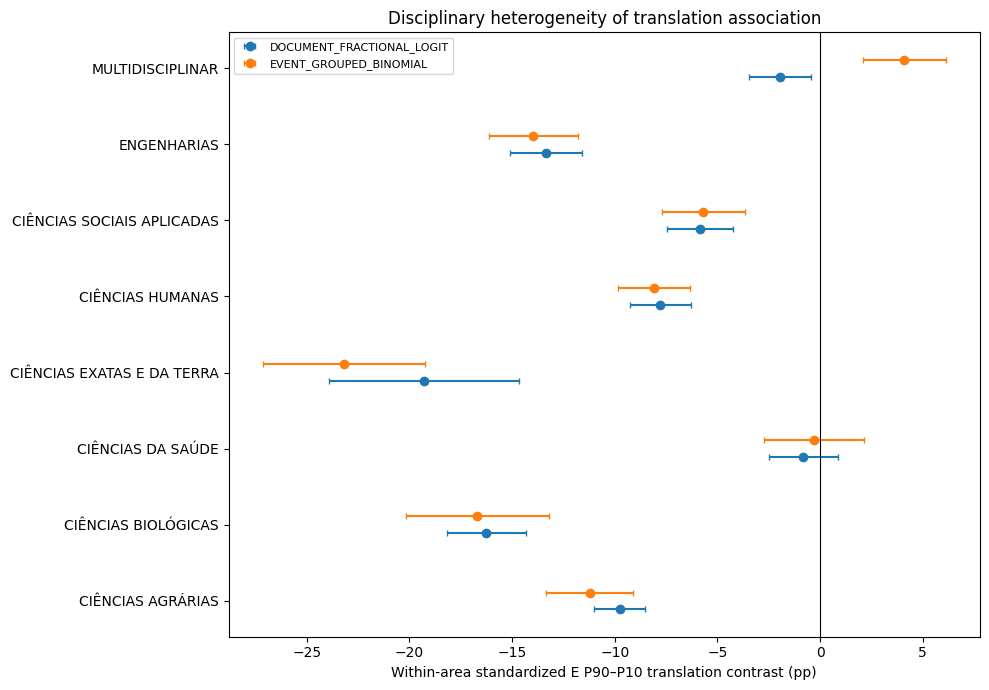

NEW DISCIPLINARY MODELS: 16 subgroup contrasts; heterogeneity is descriptive, not causal.


,area,model,N,N_ppg,contrast_pp,ci95_low_pp,ci95_high_pp,p_value,bh_fdr_q,global_scenarios_within_area_range
0,CIÊNCIAS AGRÁRIAS,DOCUMENT_FRACTIONAL_LOGIT,39518,449,-9.752381,-10.999968,-8.504795,5.509115e-53,2.203646e-52,True
1,CIÊNCIAS AGRÁRIAS,EVENT_GROUPED_BINOMIAL,39518,449,-11.227462,-13.341382,-9.113542,2.233107e-25,5.954951e-25,True
2,CIÊNCIAS BIOLÓGICAS,DOCUMENT_FRACTIONAL_LOGIT,25240,327,-16.250393,-18.168306,-14.332481,6.201710e-62,4.961368e-61,True
3,CIÊNCIAS BIOLÓGICAS,EVENT_GROUPED_BINOMIAL,25240,327,-16.687274,-20.181727,-13.192820,7.995943e-21,1.599189e-20,True
4,CIÊNCIAS DA SAÚDE,DOCUMENT_FRACTIONAL_LOGIT,59189,658,-0.815818,-2.486863,0.855226,3.386233e-01,3.386233e-01,True
5,CIÊNCIAS DA SAÚDE,EVENT_GROUPED_BINOMIAL,59189,658,-0.286776,-2.731395,2.157843,8.181492e-01,8.181492e-01,True
6,CIÊNCIAS EXATAS E DA TERRA,DOCUMENT_FRACTIONAL_LOGIT,24598,267,-19.289884,-23.913208,-14.666560,2.893043e-16,4.628869e-16,True
7,CIÊNCIAS EXATAS E DA TERRA,EVENT_GROUPED_BINOMIAL,24598,267,-23.196693,-27.148827,-19.244558,1.258809e-30,5.035237e-30,True
8,CIÊNCIAS HUMANAS,DOCUMENT_FRACTIONAL_LOGIT,61821,651,-7.783473,-9.268709,-6.298237,9.471760e-25,1.894352e-24,True
9,CIÊNCIAS HUMANAS,EVENT_GROUPED_BINOMIAL,61821,651,-8.088223,-9.844888,-6.331558,1.806180e-19,2.889888e-19,True


Area models reflect observed eligible areas only; check 38_area_universe_diagnostic.csv for missing domains.


In [41]:
# CELL 38 (CORRECTED) | Discipline-specific translation refits with observed-area census
# Replaces the previous Cell 38, which incorrectly required nine observed non-null areas.
# Analyze ONLY observed, nonmissing disciplinary groups; never impute a ninth category.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.special import expit
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests
from pathlib import Path
assert all(k in globals() for k in ['d','e_lo','e_hi','Q5']), 'Run earlier laboratory cells first.'
Q5=Path(Q5);Q5.mkdir(parents=True,exist_ok=True)
area_col='NM_GRANDE_AREA_CONHECIMENTO'
assert area_col in d and 'CD_PROGRAMA' in d and 'ANO' in d

def area_inventory(df,source,eligibility):
    if df is None or area_col not in df:
        return pd.DataFrame(columns=['source','eligibility','area','N'])
    z=df[area_col].astype('string').str.strip().replace({'':pd.NA,'nan':pd.NA,'None':pd.NA})
    x=z.fillna('(MISSING AREA)').value_counts(dropna=False)
    return pd.DataFrame({'source':source,'eligibility':eligibility,
      'area':x.index.astype(str),'N':x.to_numpy(dtype=int)})

coverage=[area_inventory(d,'d','Translation eligible')]
for name in ['frame','merge']:
    val=globals().get(name)
    if isinstance(val,pd.DataFrame):coverage.append(area_inventory(val,name,'Other loaded universe'))
coverage_df=pd.concat(coverage,ignore_index=True)
coverage_df.to_csv(Q5/'38_area_universe_diagnostic.csv',index=False)
print('Observed disciplinary categories by available data frame:')
display(coverage_df)
missing_area=int(d[area_col].isna().sum())
areas=sorted(d[area_col].dropna().astype(str).unique().tolist())
assert areas,'No nonmissing disciplinary categories in translation risk set.'
print(f'Translation eligible: {len(d):,} documents; {len(areas)} nonmissing areas; {missing_area:,} missing area labels.')
if len(areas)!=9:
    print('NOTE: Original corpus may cover nine broad areas, but only',len(areas),
          'are observed with non-null labels in this translation analysis. No categories are fabricated.')
if missing_area:
    print('CAUTION: Missing area labels are excluded from area-specific refits, with N recorded above.')

out=[];quality=[]
for area in areas:
  sub=d.loc[d.NM_GRANDE_AREA_CONHECIMENTO.astype(str).eq(area)].copy()
  cl=pd.factorize(sub.CD_PROGRAMA.astype(str))[0];g=int(len(np.unique(cl)))
  # Avoid false precision in subgroups with insufficient independent clusters.
  if g<30 or len(sub)<300 or sub.ANO.nunique()<2:
    quality.append({'area':area,'status':'SKIPPED_INSUFFICIENT_INFORMATION','N':len(sub),'N_ppg':g});continue
  xf=pd.DataFrame({'Intercept':np.ones(len(sub)),
      'E_C_QQ':sub.E_PCT_AREA_ANO.to_numpy()-0.5,
      'R_C_QQ':sub.R_PCT_AREA_ANO.to_numpy()-0.5})
  xf['E_X_R_QQ']=xf.E_C_QQ*xf.R_C_QQ
  yrdummies=pd.get_dummies(sub.ANO.astype(str),prefix='year',drop_first=True,dtype=float).reset_index(drop=True)
  xf=pd.concat([xf,yrdummies],axis=1)
  mat=np.asarray(xf,dtype=np.float64)
  num=sub.T_CROSS_GRANDE_HITS.to_numpy(dtype=float)
  den=sub.D_HITS_3Y.to_numpy(dtype=float)
  share=sub.T_CROSS_GRANDE_SHARE.to_numpy(dtype=float)
  assert np.all(den>=1) and np.allclose(num/den,share,atol=1e-6)
  support10,support90=np.quantile(sub.E_PCT_AREA_ANO,[.1,.9])
  # Scenario may extrapolate at some subgroups. Flag rather than hide it.
  global_supported=(float(sub.E_PCT_AREA_ANO.min())<=e_lo and float(sub.E_PCT_AREA_ANO.max())>=e_hi)
  for name,response in [('DOCUMENT_FRACTIONAL_LOGIT',share),('EVENT_GROUPED_BINOMIAL',np.column_stack([num,den-num]))]:
    try:
      fitted=sm.GLM(response,mat,family=sm.families.Binomial()).fit(
        cov_type='cluster',cov_kwds={'groups':cl},maxiter=90,disp=0)
      if not fitted.converged:
        quality.append({'area':area,'status':f'NOT_CONVERGED_{name}','N':len(sub),'N_ppg':g});continue
    except (ValueError,np.linalg.LinAlgError) as exc:
      quality.append({'area':area,'status':f'FAILED_{name}_{type(exc).__name__}','N':len(sub),'N_ppg':g});continue
    V=np.asarray(fitted.cov_params());theta=np.asarray(fitted.params)
    values=[]
    for e in [e_lo,e_hi]:
      x=mat.copy();x[:,1]=e-.5;x[:,3]=x[:,1]*x[:,2]
      ph=expit(x@theta)
      values.append((float(ph.mean()),np.mean(x*(ph*(1-ph))[:,None],axis=0)))
    effect=values[1][0]-values[0][0]
    grad=values[1][1]-values[0][1]
    se=np.sqrt(max(0,float(grad@V@grad)))
    pval=float(2*norm.sf(abs(effect/se))) if se>0 else np.nan
    out.append({'area':str(area),'model':name,'N':len(sub),'N_ppg':g,
      'E_p10_global':float(e_lo),'E_p90_global':float(e_hi),
      'E_p10_area':float(support10),'E_p90_area':float(support90),
      'global_scenarios_within_area_range':bool(global_supported),
      'predicted_E_p10':values[0][0],'predicted_E_p90':values[1][0],
      'contrast_pp':100*effect,'se_pp':100*se,'ci95_low_pp':100*(effect-1.96*se),
      'ci95_high_pp':100*(effect+1.96*se),'p_value':pval,
      'model_type':'New area-specific cluster-robust fractional/binomial GLM + year FE'})
  quality.append({'area':area,'status':'FITTED','N':len(sub),'N_ppg':g})
het=pd.DataFrame(out)
assert not het.empty, 'No area model was estimable; inspect 38_area_specific_model_quality.csv'
assert all(het.N>0)
het['bh_fdr_q']=np.nan
for m,ii in het.groupby('model').groups.items():
  pv=het.loc[ii,'p_value'];ok=pv.notna()
  if ok.any():het.loc[pv.index[ok],'bh_fdr_q']=multipletests(pv[ok],method='fdr_bh')[1]
het.to_csv(Q5/'38_area_specific_translation_contrasts.csv',index=False)
pd.DataFrame(quality).to_csv(Q5/'38_area_specific_model_quality.csv',index=False)
fig,ax=plt.subplots(figsize=(10,7))
area_order=sorted(het.area.unique());positions=np.arange(len(area_order))
for j,(label,gp) in enumerate(het.groupby('model')):
  gp=gp.set_index('area').reindex(area_order)
  y=positions+(j-.5)*.22
  ax.errorbar(gp.contrast_pp,y,xerr=[gp.contrast_pp-gp.ci95_low_pp,
    gp.ci95_high_pp-gp.contrast_pp],fmt='o',capsize=2,label=label)
ax.set_yticks(positions,area_order);ax.axvline(0,color='black',lw=.8)
ax.set_xlabel('Within-area standardized E P90–P10 translation contrast (pp)')
ax.set_title('Disciplinary heterogeneity of translation association')
ax.legend(fontsize=8);fig.tight_layout()
fig.savefig(Q5/'38_area_specific_translation_heterogeneity.png',dpi=190);plt.show();plt.close(fig)
print('NEW DISCIPLINARY MODELS:',len(het),'subgroup contrasts; heterogeneity is descriptive, not causal.')
display(het[['area','model','N','N_ppg','contrast_pp','ci95_low_pp','ci95_high_pp','p_value','bh_fdr_q','global_scenarios_within_area_range']])

print('Area models reflect observed eligible areas only; check 38_area_universe_diagnostic.csv for missing domains.')


In [42]:
# CELL 39 | Publishable evidence synopsis, figures, machine-checks and frozen V5 manifest
import hashlib,platform
from datetime import datetime,timezone
need=['36_translation_moderation_joint_inference.csv','37_two_part_exposure_coefficients.csv',
      '37_two_part_exposure_predicted_contrasts.csv','38_area_specific_translation_contrasts.csv',
      '38_area_specific_model_quality.csv','38_area_universe_diagnostic.csv']
assert all((Q5/f).exists() for f in need),f'Missing: {[x for x in need if not (Q5/x).exists()]}'
assert moderation.shape[0]==3 and predictions.shape[0]==3
assert len(het)>=2 and all(het.N>0) and het.ci95_low_pp.le(het.contrast_pp).all() and het.ci95_high_pp.ge(het.contrast_pp).all()
# Protect against confusing pseudo-equivalence with non-significance.
paired=pd.read_csv(Q4/'32_paired_translation_estimand_difference.csv').iloc[0]
report=[
 {'claim':'Primary translation association','evidence':f"Document {paired.document_delta_pp:+.2f} pp; event {paired.event_delta_pp:+.2f} pp",'level':'NEW refitted adjusted associations'},
 {'claim':'Paired mean translation difference','evidence':f"{paired.difference_pp:+.3f} pp (95% CI {paired.paired_ci95_low_pp:+.3f} to {paired.paired_ci95_high_pp:+.3f}; p={paired.p_value:.4f})",'level':'Joint clustered inference; not equivalence'},
 {'claim':'Recombination moderation','evidence':'See 36_translation_moderation_joint_inference.csv','level':'NEW within- and across-estimand paired clustered inference'},
 {'claim':'Exposure mechanism','evidence':'See 37_two_part_exposure_predicted_contrasts.csv','level':'NEW two-part observational models'},
 {'claim':'Disciplinary generality','evidence':'See 38_area_specific_translation_contrasts.csv','level':'NEW subgroup refits, FDR-corrected descriptive tests'},
 {'claim':'Criterion validity','evidence':'No external expert-judgment evidence in this stage','level':'NOT TESTED'},
]
pd.DataFrame(report).to_csv(Q5/'39_manuscript_evidence_synopsis.csv',index=False)
def hashfile(f):
  h=hashlib.sha256()
  with open(f,'rb') as r:
    for b in iter(lambda:r.read(1024*1024),b''):h.update(b)
  return h.hexdigest()
files=[{'filename':p.name,'bytes':p.stat().st_size,'sha256':hashfile(p)} for p in sorted(Q5.iterdir()) if p.is_file()]
manifest={'laboratory':'Quality & Quantity ETS substantive V5',
 'timestamp_utc':datetime.now(timezone.utc).isoformat(),
 'python':platform.python_version(),
 'analysis_status':'New full-data refits and paired diagnostics; no original datasets overwritten',
 'models':'Area-year main fits; observed-area-specific models with focal-year controls; PPG-cluster robust',
 'observed_area_n':len(areas), 'missing_area_labels_in_translation':missing_area,
 'limits':['Observational associations; no causal identification','No external criterion validation',
 'Original E_C/R_C coding differs from QQ re-fits','Event- and document-weighted estimands differ',
 'Two-part intensity index is NOT the expected H50 count','Cross-area estimates require subgroup support checks'],
 'files':files}
(Q5/'39_V5_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
print('COMPLETE: Quality & Quantity substantive V5.')
print('Created:',len(files)+1,'files in',Q5)
display(pd.DataFrame(report))


COMPLETE: Quality & Quantity substantive V5.
Created: 11 files in /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026/QQ_SUBSTANTIVE_V5


,claim,evidence,level
0,Primary translation association,Document -7.98 pp; event -7.40 pp,NEW refitted adjusted associations
1,Paired mean translation difference,+0.580 pp (95% CI -0.016 to +1.175; p=0.0564),Joint clustered inference; not equivalence
2,Recombination moderation,See 36_translation_moderation_joint_inference.csv,NEW within- and across-estimand paired cluster...
3,Exposure mechanism,See 37_two_part_exposure_predicted_contrasts.csv,NEW two-part observational models
4,Disciplinary generality,See 38_area_specific_translation_contrasts.csv,"NEW subgroup refits, FDR-corrected descriptive..."
5,Criterion validity,No external expert-judgment evidence in this s...,NOT TESTED


# Formal disciplinary heterogeneity and paired estimand sensitivity

In [43]:
# CELL 40 | Global heterogeneity test: pooled area-specific E and E×R slopes
# Explicitly new models. Overall evidence for heterogeneous E effects is tested jointly,
# not inferred from comparing separate area-specific p-values.
import numpy as np, pandas as pd, matplotlib.pyplot as plt, statsmodels.api as sm
from scipy.special import expit
from scipy.stats import chi2, norm
from pathlib import Path
Q6=Path(Q5).parent/'QQ_SUBSTANTIVE_V6'; Q6.mkdir(parents=True,exist_ok=True)
assert all(k in globals() for k in ['d','het','doc_fit','evt_fit','e_lo','e_hi'])
assert len(d)==363690
col='NM_GRANDE_AREA_CONHECIMENTO'
a=d[col].astype('string').str.strip()
assert a.notna().all() and a.ne('').all()
area_levels=sorted(a.unique().tolist());assert len(area_levels)>=2
n=len(d);clusters=pd.factorize(d.CD_PROGRAMA.astype(str))[0]
E=d.E_PCT_AREA_ANO.to_numpy(dtype=float)-.5;R=d.R_PCT_AREA_ANO.to_numpy(dtype=float)-.5
area_dummies=pd.get_dummies(a,drop_first=True,dtype=float).reset_index(drop=True)
yr=pd.get_dummies(d.ANO.astype(str),drop_first=True,dtype=float).reset_index(drop=True)
x40=pd.DataFrame({'Intercept':np.ones(n),'E_C_QQ':E,'R_C_QQ':R,'E_X_R_QQ':E*R})
for j,key in enumerate(area_dummies.columns):
  v=area_dummies[key].to_numpy(dtype=float)
  x40[f'area_{j}']=v
  x40[f'E_area_{j}']=E*v
  x40[f'R_area_{j}']=R*v
  x40[f'ER_area_{j}']=E*R*v
x40=pd.concat([x40,yr.add_prefix('year_')],axis=1)
X40=np.ascontiguousarray(x40.to_numpy(dtype=float)); assert np.isfinite(X40).all()
num=d.T_CROSS_GRANDE_HITS.to_numpy(dtype=float)
den=d.D_HITS_3Y.to_numpy(dtype=float)
share=d.T_CROSS_GRANDE_SHARE.to_numpy(dtype=float)
assert np.allclose(num/den,share,atol=1e-6)
cols40=list(x40.columns)
rows40=[];contr40=[];ref_area=area_levels[0]
for kind,y in [('DOCUMENT_FRACTIONAL_LOGIT',share),('EVENT_GROUPED_BINOMIAL',np.column_stack((num,den-num)))]:
  fit=sm.GLM(y,X40,family=sm.families.Binomial()).fit(cov_type='cluster',cov_kwds={'groups':clusters},maxiter=100,disp=0)
  assert fit.converged
  ix=[i for i,k in enumerate(cols40) if k.startswith('E_area_') or k.startswith('ER_area_')]
  assert len(ix)==2*(len(area_levels)-1)
  b=np.asarray(fit.params)[ix]; V=np.asarray(fit.cov_params())[np.ix_(ix,ix)]
  wald=float(b@np.linalg.pinv(V,hermitian=True)@b);pval=float(chi2.sf(wald,len(ix)))
  rows40.append({'model':kind,'test':'All area-specific E and E×R interactions jointly zero',
    'chi2':wald,'df':len(ix),'p_value':pval,'N':n,'N_PPG':len(np.unique(clusters)),
    'observed_area_count':len(area_levels),'reference_area':ref_area})
  # Area-specific standardized E contrasts; hold area fixed and distribute observed R+years within area.
  theta=np.asarray(fit.params);cov=np.asarray(fit.cov_params())
  for area in area_levels:
    loc=np.where(a.to_numpy()==area)[0]
    base=X40[loc,:].copy()
    def counterfactual_at(e):
      z=base.copy(); ec=float(e)-.5
      z[:,cols40.index('E_C_QQ')]=ec
      z[:,cols40.index('E_X_R_QQ')]=ec*z[:,cols40.index('R_C_QQ')]
      for j in range(len(area_levels)-1):
        area_bin=z[:,cols40.index(f'area_{j}')]
        z[:,cols40.index(f'E_area_{j}')]=ec*area_bin
        z[:,cols40.index(f'ER_area_{j}')]=ec*z[:,cols40.index('R_C_QQ')]*area_bin
      p=expit(z@theta)
      return float(p.mean()),(z*(p*(1-p))[:,None]).mean(axis=0)
    plo,glo=counterfactual_at(e_lo);phi,ghi=counterfactual_at(e_hi)
    delta=phi-plo; gg=ghi-glo;se=float(np.sqrt(max(0,gg@cov@gg)))
    contr40.append({'area':area,'model':kind,'N':len(loc),'E_p10_global':float(e_lo),'E_p90_global':float(e_hi),
      'contrast_pp':100*delta,'se_pp':100*se,'ci95_low_pp':100*(delta-1.96*se),
      'ci95_high_pp':100*(delta+1.96*se),'source':'New pooled model with area-varying E, R and E×R slopes; year FE'})
  del fit
wald40=pd.DataFrame(rows40); pooled40=pd.DataFrame(contr40)
wald40.to_csv(Q6/'40_global_area_heterogeneity_tests.csv',index=False)
pooled40.to_csv(Q6/'40_pooled_area_standardized_contrasts.csv',index=False)
print('GLOBAL PPG-CLUSTER WALD TESTS (omnibus, not pairwise group differences):')
display(wald40)
print('POOLED AREA-SPECIFIC STANDARDIZED CONTRASTS:');display(pooled40)


GLOBAL PPG-CLUSTER WALD TESTS (omnibus, not pairwise group differences):


,model,test,chi2,df,p_value,N,N_PPG,observed_area_count,reference_area
0,DOCUMENT_FRACTIONAL_LOGIT,All area-specific E and E×R interactions joint...,391.348409,14,8.415800e-75,363690,4248,8,CIÊNCIAS AGRÁRIAS
1,EVENT_GROUPED_BINOMIAL,All area-specific E and E×R interactions joint...,343.976298,14,7.541933e-65,363690,4248,8,CIÊNCIAS AGRÁRIAS


POOLED AREA-SPECIFIC STANDARDIZED CONTRASTS:


,area,model,N,E_p10_global,E_p90_global,contrast_pp,se_pp,ci95_low_pp,ci95_high_pp,source
0,CIÊNCIAS AGRÁRIAS,DOCUMENT_FRACTIONAL_LOGIT,39518,0.079825,0.816832,-9.753965,0.637160,-11.002798,-8.505132,"New pooled model with area-varying E, R and E×..."
1,CIÊNCIAS BIOLÓGICAS,DOCUMENT_FRACTIONAL_LOGIT,25240,0.079825,0.816832,-16.263579,0.985728,-18.195606,-14.331551,"New pooled model with area-varying E, R and E×..."
2,CIÊNCIAS DA SAÚDE,DOCUMENT_FRACTIONAL_LOGIT,59189,0.079825,0.816832,-0.808418,0.851110,-2.476593,0.859758,"New pooled model with area-varying E, R and E×..."
3,CIÊNCIAS EXATAS E DA TERRA,DOCUMENT_FRACTIONAL_LOGIT,24598,0.079825,0.816832,-19.319339,2.322697,-23.871826,-14.766852,"New pooled model with area-varying E, R and E×..."
4,CIÊNCIAS HUMANAS,DOCUMENT_FRACTIONAL_LOGIT,61821,0.079825,0.816832,-7.792934,0.754613,-9.271975,-6.313893,"New pooled model with area-varying E, R and E×..."
5,CIÊNCIAS SOCIAIS APLICADAS,DOCUMENT_FRACTIONAL_LOGIT,55971,0.079825,0.816832,-5.839262,0.820583,-7.447605,-4.230919,"New pooled model with area-varying E, R and E×..."
6,ENGENHARIAS,DOCUMENT_FRACTIONAL_LOGIT,42434,0.079825,0.816832,-13.311449,0.892001,-15.059770,-11.563128,"New pooled model with area-varying E, R and E×..."
7,MULTIDISCIPLINAR,DOCUMENT_FRACTIONAL_LOGIT,54919,0.079825,0.816832,-1.974864,0.767682,-3.479520,-0.470207,"New pooled model with area-varying E, R and E×..."
8,CIÊNCIAS AGRÁRIAS,EVENT_GROUPED_BINOMIAL,39518,0.079825,0.816832,-11.233968,1.092157,-13.374596,-9.093341,"New pooled model with area-varying E, R and E×..."
9,CIÊNCIAS BIOLÓGICAS,EVENT_GROUPED_BINOMIAL,25240,0.079825,0.816832,-16.643729,1.796126,-20.164137,-13.123321,"New pooled model with area-varying E, R and E×..."


# Formal disciplinary heterogeneity and paired estimand sensitivity

Completed CIÊNCIAS AGRÁRIAS: N=39,518, clusters=449, event–document=-1.475 pp
Completed CIÊNCIAS BIOLÓGICAS: N=25,240, clusters=327, event–document=-0.437 pp
Completed CIÊNCIAS DA SAÚDE: N=59,189, clusters=658, event–document=+0.529 pp
Completed CIÊNCIAS EXATAS E DA TERRA: N=24,598, clusters=267, event–document=-3.907 pp
Completed CIÊNCIAS HUMANAS: N=61,821, clusters=651, event–document=-0.305 pp
Completed CIÊNCIAS SOCIAIS APLICADAS: N=55,971, clusters=643, event–document=+0.140 pp
Completed ENGENHARIAS: N=42,434, clusters=461, event–document=-0.627 pp
Completed MULTIDISCIPLINAR: N=54,919, clusters=808, event–document=+6.071 pp


,area,N,N_PPG,E_p10_global,E_p90_global,document_effect_pp,event_effect_pp,event_minus_document_pp,paired_cluster_se_pp,ci95_low_pp,ci95_high_pp,p_value,status,fdr_bh_q
0,CIÊNCIAS AGRÁRIAS,39518,449,0.079825,0.816832,-9.752381,-11.227462,-1.475081,0.820782,-3.083814,0.133652,7.230940e-02,Paired influence-function sandwich; separate w...,1.928251e-01
1,CIÊNCIAS BIOLÓGICAS,25240,327,0.079825,0.816832,-16.250393,-16.687274,-0.436880,1.440970,-3.261181,2.387420,7.617489e-01,Paired influence-function sandwich; separate w...,8.211538e-01
2,CIÊNCIAS DA SAÚDE,59189,658,0.079825,0.816832,-0.815818,-0.286776,0.529042,0.789272,-1.017931,2.076015,5.026721e-01,Paired influence-function sandwich; separate w...,7.962780e-01
3,CIÊNCIAS EXATAS E DA TERRA,24598,267,0.079825,0.816832,-19.289884,-23.196693,-3.906808,1.553209,-6.951097,-0.862520,1.189262e-02,Paired influence-function sandwich; separate w...,4.757046e-02
4,CIÊNCIAS HUMANAS,61821,651,0.079825,0.816832,-7.783473,-8.088223,-0.304750,0.576720,-1.435120,0.825621,5.972085e-01,Paired influence-function sandwich; separate w...,7.962780e-01
5,CIÊNCIAS SOCIAIS APLICADAS,55971,643,0.079825,0.816832,-5.832975,-5.693362,0.139613,0.617591,-1.070865,1.350092,8.211538e-01,Paired influence-function sandwich; separate w...,8.211538e-01
6,ENGENHARIAS,42434,461,0.079825,0.816832,-13.340454,-13.967725,-0.627271,0.693626,-1.986778,0.732235,3.658169e-01,Paired influence-function sandwich; separate w...,7.316338e-01
7,MULTIDISCIPLINAR,54919,808,0.079825,0.816832,-1.954319,4.116183,6.070503,0.646050,4.804245,7.336761,5.649657e-21,Paired influence-function sandwich; separate w...,4.519726e-20


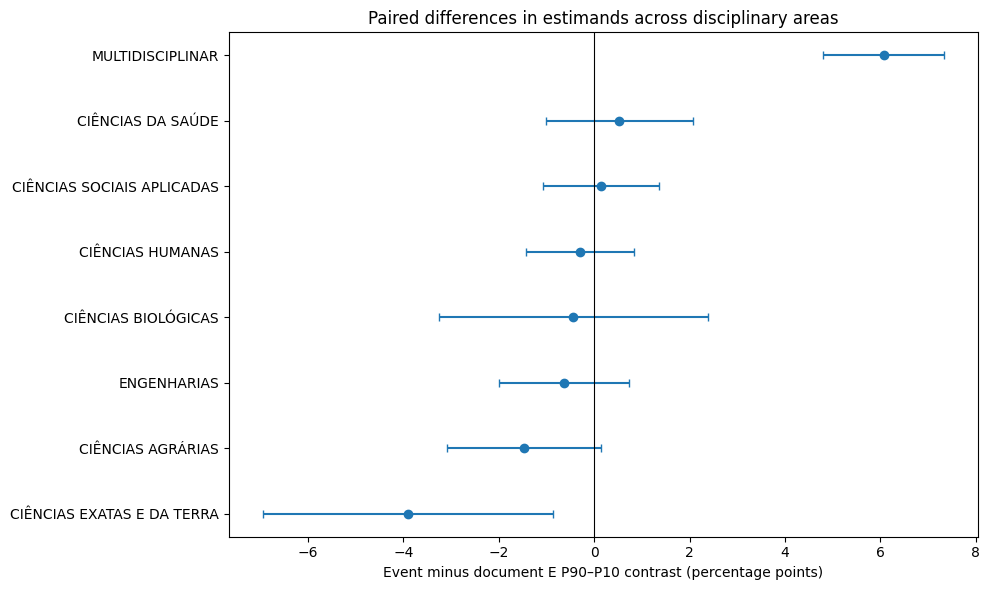

In [44]:
# CELL 41 | Within-area, PPG-paired inference: event-minus-document contrasts
# The target here is the cross-estimand difference WITHIN EACH disciplinary area,
# including Multidisciplinary. Refit both models on identical documents and covariates.
import scipy.linalg as la
from scipy.stats import norm
rows41=[]
for area in area_levels:
  sub=d.loc[a.eq(area)].copy(); na=len(sub)
  cl,un=pd.factorize(sub.CD_PROGRAMA.astype(str));G=len(un)
  assert G>30 and na>1000
  yy=pd.get_dummies(sub.ANO.astype(str),drop_first=True,dtype=float).reset_index(drop=True)
  z=pd.DataFrame({'Intercept':np.ones(na),'E_C_QQ':sub.E_PCT_AREA_ANO.to_numpy(float)-.5,
                  'R_C_QQ':sub.R_PCT_AREA_ANO.to_numpy(float)-.5})
  z['E_X_R_QQ']=z.E_C_QQ*z.R_C_QQ
  z=pd.concat([z,yy],axis=1)
  zz=np.ascontiguousarray(z.to_numpy(dtype=float));p=zz.shape[1]
  eidx,ridx,xidx=[z.columns.get_loc(t) for t in ['E_C_QQ','R_C_QQ','E_X_R_QQ']]
  num_a=sub.T_CROSS_GRANDE_HITS.to_numpy(float); den_a=sub.D_HITS_3Y.to_numpy(float)
  share_a=sub.T_CROSS_GRANDE_SHARE.to_numpy(float)
  assert np.allclose(num_a/den_a,share_a,atol=1e-6)
  fits41={}
  for tag,y in [('document',share_a),('event',np.column_stack((num_a,den_a-num_a)))]:
    model=sm.GLM(y,zz,family=sm.families.Binomial()).fit(cov_type='cluster',cov_kwds={'groups':cl},maxiter=100,disp=0)
    assert model.converged
    fits41[tag]=model
  def group_score(fit,trial,response):
    pp=expit(zz@np.asarray(fit.params)); residual=response-trial*pp
    accum=np.zeros((G,p),dtype=float)
    np.add.at(accum,cl,zz*residual[:,None])
    bread=zz.T@(zz*(trial*pp*(1-pp))[:,None])
    return accum@np.linalg.pinv(bread,hermitian=True).T
  scores_d=group_score(fits41['document'],np.ones(na),share_a)
  scores_e=group_score(fits41['event'],den_a,num_a)
  correction=G/(G-1)*(na-1)/(na-p)
  Vd=correction*scores_d.T@scores_d;Ve=correction*scores_e.T@scores_e
  Vde=correction*scores_d.T@scores_e
  for typ,fit,V in [('document',fits41['document'],Vd),('event',fits41['event'],Ve)]:
    ref=np.asarray(fit.cov_params())
    discrepancy=float(np.max(abs(np.diag(V)-np.diag(ref))/np.maximum(abs(np.diag(ref)),1e-12)))
    assert discrepancy<.04, f'Covariance validation failed for {area} {typ}: {discrepancy}'
  def cf_gradient(fit,e):
    x=zz.copy();ec=float(e)-.5
    x[:,eidx]=ec;x[:,xidx]=ec*x[:,ridx]
    pp=expit(x@np.asarray(fit.params))
    return float(pp.mean()),np.mean(x*(pp*(1-pp))[:,None],axis=0)
  effects={}
  for tag,fit in fits41.items():
    lo,g0=cf_gradient(fit,e_lo);hi,g1=cf_gradient(fit,e_hi)
    effects[tag]=(hi-lo,g1-g0)
  ed,gd=effects['document'];ee,ge=effects['event']
  diff=ee-ed
  variance=float(ge@Ve@ge+gd@Vd@gd-2*gd@Vde@ge)
  assert variance>-1e-10
  se=float(np.sqrt(max(variance,0)))
  pval=float(2*norm.sf(abs(diff/se))) if se>0 else np.nan
  rows41.append({'area':area,'N':na,'N_PPG':G,'E_p10_global':float(e_lo),'E_p90_global':float(e_hi),
    'document_effect_pp':100*ed,'event_effect_pp':100*ee,
    'event_minus_document_pp':100*diff,'paired_cluster_se_pp':100*se,
    'ci95_low_pp':100*(diff-1.96*se),'ci95_high_pp':100*(diff+1.96*se),'p_value':pval,
    'status':'Paired influence-function sandwich; separate within-area refits with year FE'})
  print(f'Completed {area}: N={na:,}, clusters={G:,}, event–document={100*diff:+.3f} pp')
paired41=pd.DataFrame(rows41).sort_values('area')
from statsmodels.stats.multitest import multipletests
paired41['fdr_bh_q']=multipletests(paired41.p_value,method='fdr_bh')[1]
paired41.to_csv(Q6/'41_within_area_paired_estimand_differences.csv',index=False)
display(paired41)
fig,ax=plt.subplots(figsize=(10,6));p41=paired41.sort_values('event_minus_document_pp')
ax.errorbar(p41.event_minus_document_pp,np.arange(len(p41)),
  xerr=[p41.event_minus_document_pp-p41.ci95_low_pp,p41.ci95_high_pp-p41.event_minus_document_pp],
  fmt='o',capsize=3)
ax.set_yticks(np.arange(len(p41)),p41.area.tolist());ax.axvline(0,color='black',lw=.8)
ax.set_xlabel('Event minus document E P90–P10 contrast (percentage points)')
ax.set_title('Paired differences in estimands across disciplinary areas')
fig.tight_layout();fig.savefig(Q6/'41_within_area_paired_estimand_differences.png',dpi=190)
plt.show();plt.close(fig)


# Formal disciplinary heterogeneity and paired estimand sensitivity

In [45]:
# CELL 42 | Publication-oriented evidence tables; ensure no accidental inference claims
# This is a full reporting analysis, not a re-estimation. Tests refer to the relevant
# conditional populations and link functions.
import json, hashlib, platform
from datetime import datetime, timezone
out42=paired41.merge(pooled40[['area','model','contrast_pp','ci95_low_pp','ci95_high_pp']],
   on='area',how='left',validate='one_to_many')
assert len(out42)==2*len(area_levels)
out42.to_csv(Q6/'42_joint_area_heterogeneity_evidence.csv',index=False)
summary42=pd.DataFrame([
 {'question':'Does emergence association differ across areas in a pooled model?',
  'evidence':'Omnibus PPG-cluster Wald tests in 40_global_area_heterogeneity_tests.csv',
  'interpretation':'Model-dependent pooled heterogeneity; associations only'},
 {'question':'Within a specific area, is event weighting different from document weighting?',
  'evidence':'Paired PPG cluster sandwich in 41_within_area_paired_estimand_differences.csv',
  'interpretation':'Cross-estimand difference; no evidence of causal impact'},
 {'question':'Why are eight rather than nine disciplines observed?',
  'evidence':'38_area_universe_diagnostic.csv: observed eight nonmissing categories in MAIN44 and translation risk set',
  'interpretation':'Do not impute a ninth area or extrapolate to absent domain'},
 {'question':'Is ETS externally valid?',
  'evidence':'No independent subject-expert epistemic criterion in current experiment',
  'interpretation':'No criterion-validity claim'}])
summary42.to_csv(Q6/'42_methodological_reporting_guide.csv',index=False)
def _sha256(p):
  h=hashlib.sha256()
  with open(p,'rb') as f:
    for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
  return h.hexdigest()
files=[{'name':p.name,'sha256':_sha256(p),'bytes':p.stat().st_size} for p in sorted(Q6.iterdir()) if p.is_file()]
report={'study':'ETS Quality & Quantity V6: disciplinary heterogeneity and paired weighting sensitivity',
 'generated_utc':datetime.now(timezone.utc).isoformat(),'n_translation':int(len(d)),
 'n_disciplines_observed':len(area_levels),'discipline_labels':area_levels,
 'inference':'PPG-cluster sandwich; observational, conditional on eligible translation sample',
 'limits':['No causal effect identification','No ninth CAPES broad area observed in this frozen analytical sample',
           'Pooled and stratified model coefficients target different conditional models',
           'FDR controls multiple comparisons only within the eight paired group tests',
           'No external criterion validation'], 'files':files}
(Q6/'42_V6_manifest.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf8')
print('PASS: substantive models and publication evidence exported to',Q6)
print('Number of exported files:',len(files)+1)
display(wald40);display(paired41[['area','N','N_PPG','event_minus_document_pp','ci95_low_pp','ci95_high_pp','p_value','fdr_bh_q']])


PASS: substantive models and publication evidence exported to /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026/QQ_SUBSTANTIVE_V6
Number of exported files: 7


,model,test,chi2,df,p_value,N,N_PPG,observed_area_count,reference_area
0,DOCUMENT_FRACTIONAL_LOGIT,All area-specific E and E×R interactions joint...,391.348409,14,8.415800e-75,363690,4248,8,CIÊNCIAS AGRÁRIAS
1,EVENT_GROUPED_BINOMIAL,All area-specific E and E×R interactions joint...,343.976298,14,7.541933e-65,363690,4248,8,CIÊNCIAS AGRÁRIAS


,area,N,N_PPG,event_minus_document_pp,ci95_low_pp,ci95_high_pp,p_value,fdr_bh_q
0,CIÊNCIAS AGRÁRIAS,39518,449,-1.475081,-3.083814,0.133652,7.230940e-02,1.928251e-01
1,CIÊNCIAS BIOLÓGICAS,25240,327,-0.436880,-3.261181,2.387420,7.617489e-01,8.211538e-01
2,CIÊNCIAS DA SAÚDE,59189,658,0.529042,-1.017931,2.076015,5.026721e-01,7.962780e-01
3,CIÊNCIAS EXATAS E DA TERRA,24598,267,-3.906808,-6.951097,-0.862520,1.189262e-02,4.757046e-02
4,CIÊNCIAS HUMANAS,61821,651,-0.304750,-1.435120,0.825621,5.972085e-01,7.962780e-01
5,CIÊNCIAS SOCIAIS APLICADAS,55971,643,0.139613,-1.070865,1.350092,8.211538e-01,8.211538e-01
6,ENGENHARIAS,42434,461,-0.627271,-1.986778,0.732235,3.658169e-01,7.316338e-01
7,MULTIDISCIPLINAR,54919,808,6.070503,4.804245,7.336761,5.649657e-21,4.519726e-20


# Event concentration and the document-versus-event estimand

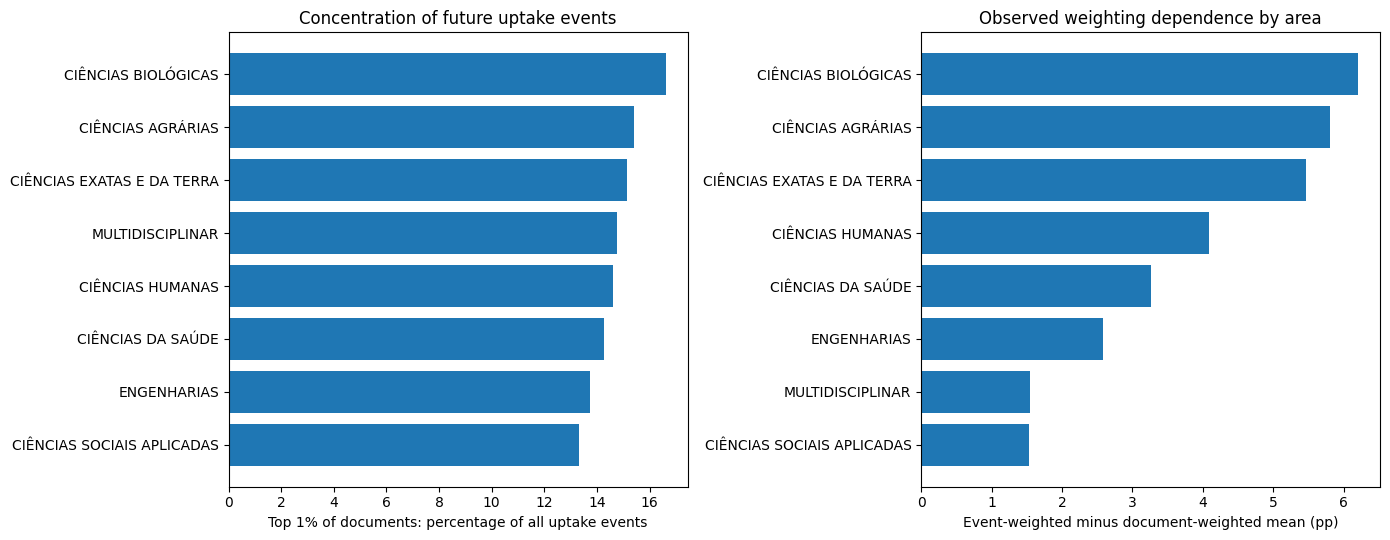

COMPLETED: empirical weight concentration. This is NOT a decomposition of regression coefficients.


,area,N,n_ppg,mean_document_share,event_weighted_share,event_minus_document_share_pp,mean_uptake_events,median_events,p90_events,p95_events,p99_events,max_events,top_one_percent_document_share_of_events,event_effective_sample_size,corr_event_count_and_translation_share
0,CIÊNCIAS AGRÁRIAS,39518,449,0.295442,0.353505,5.806262,11.836682,5.0,26.0,42.00,102.0,2021.0,0.153965,7058.502728,0.081333
1,CIÊNCIAS BIOLÓGICAS,25240,327,0.458651,0.520698,6.204741,12.331815,5.0,27.0,45.00,113.0,1032.0,0.166118,4222.409775,0.079491
2,CIÊNCIAS DA SAÚDE,59189,658,0.310012,0.342597,3.258472,13.347700,6.0,31.0,48.00,110.0,2431.0,0.142693,11026.177420,0.048547
3,CIÊNCIAS EXATAS E DA TERRA,24598,267,0.332515,0.387151,5.463587,11.433938,5.0,27.0,43.15,105.0,651.0,0.151423,4815.019887,0.075354
4,CIÊNCIAS HUMANAS,61821,651,0.404123,0.444994,4.087086,14.335646,5.0,34.0,55.00,134.0,921.0,0.146075,12464.727044,0.060080
5,CIÊNCIAS SOCIAIS APLICADAS,55971,643,0.347911,0.363229,1.531794,13.480660,6.0,32.0,52.00,118.0,585.0,0.133221,12889.897850,0.024804
6,ENGENHARIAS,42434,461,0.351926,0.377738,2.581199,11.214168,5.0,26.0,41.00,94.0,915.0,0.137199,8989.944008,0.038026
7,MULTIDISCIPLINAR,54919,808,0.677594,0.693102,1.550829,13.636210,5.0,32.0,52.00,120.0,767.0,0.147552,11209.786269,0.025209


In [46]:
# CELL 43 | Substantive decomposition: why event weighting changes translation
# Uses the same 363,690 eligible documents as V6; descriptive, non-causal.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
assert 'd' in globals() and len(d)==363690, 'Run the full translation refit (cell 29) first.'
assert 'Q6' in globals(), 'Run cell 40 first.'
Q7=Path(Q6).parent/'QQ_SUBSTANTIVE_V7'; Q7.mkdir(parents=True,exist_ok=True)
area_key='NM_GRANDE_AREA_CONHECIMENTO'
needed=[area_key,'CD_PROGRAMA','E_PCT_AREA_ANO','R_PCT_AREA_ANO',
        'T_CROSS_GRANDE_HITS','D_HITS_3Y','T_CROSS_GRANDE_SHARE']
assert set(needed).issubset(d.columns)
z=d[needed].copy()
for v in ['E_PCT_AREA_ANO','R_PCT_AREA_ANO','T_CROSS_GRANDE_HITS','D_HITS_3Y','T_CROSS_GRANDE_SHARE']:
    z[v]=pd.to_numeric(z[v],errors='coerce')
assert z[needed].notna().all().all()
assert z.D_HITS_3Y.ge(1).all() and z.T_CROSS_GRANDE_HITS.between(0,z.D_HITS_3Y).all()
assert np.allclose(z.T_CROSS_GRANDE_SHARE,z.T_CROSS_GRANDE_HITS/z.D_HITS_3Y,atol=1e-6)
rows=[]
for area,sub in z.groupby(area_key,observed=True):
    den=sub.D_HITS_3Y.to_numpy(float); ratio=sub.T_CROSS_GRANDE_SHARE.to_numpy(float)
    upper=np.quantile(den,[.5,.9,.95,.99])
    x=np.sort(den)[::-1]; k=max(1,int(np.ceil(.01*len(x))))
    wmean=float(np.average(ratio,weights=den)); dmean=float(np.mean(ratio))
    corr=float(np.corrcoef(den,ratio)[0,1]) if np.std(den)>0 and np.std(ratio)>0 else np.nan
    rows.append({'area':area,'N':len(sub),'n_ppg':sub.CD_PROGRAMA.nunique(),
        'mean_document_share':dmean,'event_weighted_share':wmean,
        'event_minus_document_share_pp':100*(wmean-dmean),
        'mean_uptake_events':float(np.mean(den)),'median_events':upper[0],
        'p90_events':upper[1],'p95_events':upper[2],'p99_events':upper[3],
        'max_events':float(np.max(den)),
        'top_one_percent_document_share_of_events':float(x[:k].sum()/x.sum()),
        'event_effective_sample_size':float(den.sum()**2/np.dot(den,den)),
        'corr_event_count_and_translation_share':corr})
conc43=pd.DataFrame(rows).sort_values('area')
conc43.to_csv(Q7/'43_area_event_concentration.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(14,5.5))
t=conc43.sort_values('top_one_percent_document_share_of_events')
axes[0].barh(t.area,t.top_one_percent_document_share_of_events*100)
axes[0].set_xlabel('Top 1% of documents: percentage of all uptake events')
axes[0].set_title('Concentration of future uptake events')
t=conc43.sort_values('event_minus_document_share_pp')
axes[1].barh(t.area,t.event_minus_document_share_pp)
axes[1].axvline(0,color='black',linewidth=.7)
axes[1].set_xlabel('Event-weighted minus document-weighted mean (pp)')
axes[1].set_title('Observed weighting dependence by area')
fig.tight_layout();fig.savefig(Q7/'43_event_concentration.png',dpi=170);plt.show();plt.close(fig)
print('COMPLETED: empirical weight concentration. This is NOT a decomposition of regression coefficients.')
display(conc43)


# Within-area emergence gradients under both units of analysis

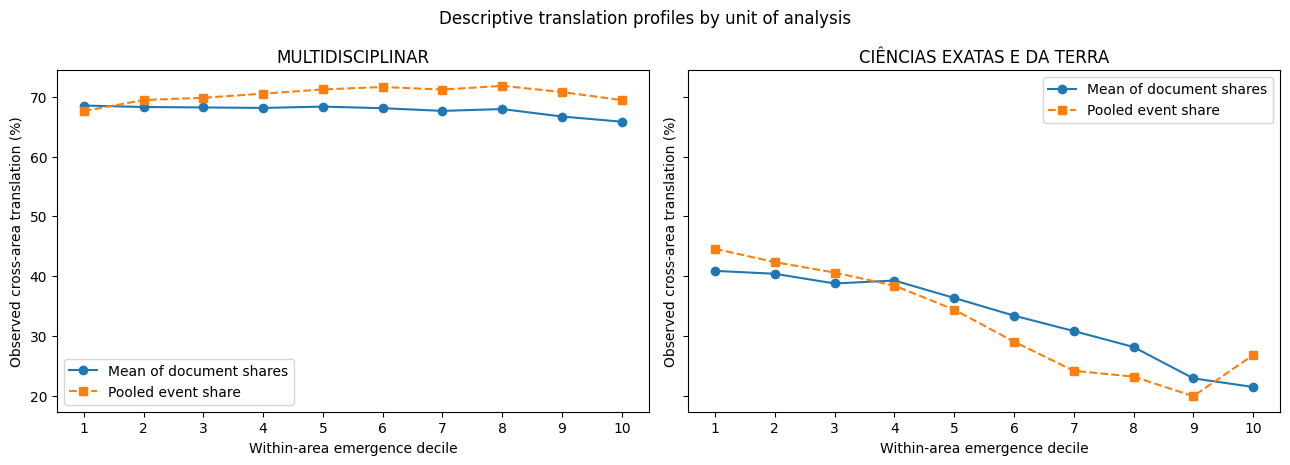

PASS: Cell 44 fixed; numeric arrays validated and exports written to /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026/QQ_SUBSTANTIVE_V7
Unadjusted profiles, NOT regression-adjusted effects.


,area,within_area_E_decile,N,document_mean_translation_share,total_events,total_cross_area_events,mean_exposure_events,mean_E,event_pooled_translation_share
30,CIÊNCIAS EXATAS E DA TERRA,1,2460,0.408888,95754.0,42679.0,38.924390,0.039322,0.445715
31,CIÊNCIAS EXATAS E DA TERRA,2,2460,0.404007,52139.0,22079.0,21.194715,0.118127,0.423464
32,CIÊNCIAS EXATAS E DA TERRA,3,2460,0.387798,34710.0,14092.0,14.109756,0.200081,0.405993
33,CIÊNCIAS EXATAS E DA TERRA,4,2459,0.392764,25359.0,9741.0,10.312729,0.285461,0.384124
34,CIÊNCIAS EXATAS E DA TERRA,5,2460,0.363609,19997.0,6880.0,8.128862,0.373824,0.344052
35,CIÊNCIAS EXATAS E DA TERRA,6,2460,0.334076,16093.0,4675.0,6.541870,0.465275,0.290499
36,CIÊNCIAS EXATAS E DA TERRA,7,2459,0.308311,13284.0,3213.0,5.402196,0.560361,0.241870
37,CIÊNCIAS EXATAS E DA TERRA,8,2460,0.281651,9969.0,2314.0,4.052439,0.662130,0.232120
38,CIÊNCIAS EXATAS E DA TERRA,9,2460,0.229222,7653.0,1526.0,3.110976,0.771150,0.199399
39,CIÊNCIAS EXATAS E DA TERRA,10,2460,0.214838,6294.0,1688.0,2.558537,0.909663,0.268192


In [48]:
# CELL 44 | Robust descriptive document/event translation profiles by within-area E deciles
# Replace the previous Cell 44 IN FULL; numeric validation precedes visualization.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

assert 'z' in globals() and 'Q7' in globals(), 'Run Cell 43 before Cell 44.'
assert {'NM_GRANDE_AREA_CONHECIMENTO','E_PCT_AREA_ANO','T_CROSS_GRANDE_SHARE',
        'D_HITS_3Y','T_CROSS_GRANDE_HITS'}.issubset(z.columns)

b=z.copy()
area_key='NM_GRANDE_AREA_CONHECIMENTO'
for c in ['E_PCT_AREA_ANO','T_CROSS_GRANDE_SHARE','D_HITS_3Y','T_CROSS_GRANDE_HITS']:
    b[c]=pd.to_numeric(b[c],errors='raise').astype('float64')
assert np.isfinite(b[['E_PCT_AREA_ANO','T_CROSS_GRANDE_SHARE',
                     'D_HITS_3Y','T_CROSS_GRANDE_HITS']].to_numpy()).all()
assert b.D_HITS_3Y.gt(0).all()
assert b.T_CROSS_GRANDE_HITS.between(0,b.D_HITS_3Y).all()

# Deterministic decade assignment, disallow missing categories and unexpected ties.
b['E_BIN_AREA']=b.groupby(area_key,observed=True)['E_PCT_AREA_ANO'].transform(
    lambda s: pd.qcut(s.rank(method='first'),q=10,labels=False,duplicates='raise')+1
).astype('int64')

# Aggregation produces SINGLE float-valued scalar per area-decile.
grad44=(b.groupby([area_key,'E_BIN_AREA'],observed=True)
  .agg(N=('T_CROSS_GRANDE_SHARE','size'),
       document_mean_translation_share=('T_CROSS_GRANDE_SHARE','mean'),
       total_events=('D_HITS_3Y','sum'),
       total_cross_area_events=('T_CROSS_GRANDE_HITS','sum'),
       mean_exposure_events=('D_HITS_3Y','mean'),
       mean_E=('E_PCT_AREA_ANO','mean'))
  .reset_index().rename(columns={area_key:'area','E_BIN_AREA':'within_area_E_decile'}))
grad44['event_pooled_translation_share']=(
    grad44['total_cross_area_events'].to_numpy(dtype='float64') /
    grad44['total_events'].to_numpy(dtype='float64'))

cols=['document_mean_translation_share','event_pooled_translation_share',
      'mean_exposure_events','total_events','total_cross_area_events','mean_E']
for c in cols:
    grad44[c]=pd.to_numeric(grad44[c],errors='raise').astype('float64')
assert grad44.groupby('area').size().eq(10).all(), 'Each area must have exactly 10 deciles.'
assert grad44[cols].notna().all().all(), 'Null aggregate detected.'
assert np.isfinite(grad44[cols].to_numpy(dtype='float64')).all()
assert grad44['event_pooled_translation_share'].between(0,1).all()
assert grad44['document_mean_translation_share'].between(0,1).all()
assert grad44.columns.is_unique, 'Ambiguous duplicate columns.'

grad44.sort_values(['area','within_area_E_decile']).to_csv(
    Q7/'44_within_area_decile_gradients.csv',index=False)
selected=['MULTIDISCIPLINAR','CIÊNCIAS EXATAS E DA TERRA']
fig,axs=plt.subplots(1,2,figsize=(13,4.7),sharey=True)
for ax,area in zip(axs,selected):
    s=grad44.loc[grad44['area'].eq(area)].sort_values('within_area_E_decile')
    assert len(s)==10, 'Requested diagnostic area absent: '+area
    xx=s['within_area_E_decile'].to_numpy(dtype='float64').reshape(-1)
    doc=100.0*s['document_mean_translation_share'].to_numpy(dtype='float64').reshape(-1)
    event=100.0*s['event_pooled_translation_share'].to_numpy(dtype='float64').reshape(-1)
    assert xx.shape==doc.shape==event.shape==(10,)
    ax.plot(xx,doc,'o-',label='Mean of document shares')
    ax.plot(xx,event,'s--',label='Pooled event share')
    ax.set_title(area)
    ax.set_xlabel('Within-area emergence decile')
    ax.set_ylabel('Observed cross-area translation (%)')
    ax.set_xticks(np.arange(1,11))
    ax.legend()
fig.suptitle('Descriptive translation profiles by unit of analysis')
fig.tight_layout()
fig.savefig(Q7/'44_translation_weighting_by_emergence.png',dpi=190)
plt.show()
plt.close(fig)
print('PASS: Cell 44 fixed; numeric arrays validated and exports written to',Q7)
print('Unadjusted profiles, NOT regression-adjusted effects.')
display(grad44.loc[grad44['area'].isin(selected)].sort_values(['area','within_area_E_decile']))


# Sensitivity refits excluding high-event documents

MULTIDISCIPLINAR event cutoff quantile 1.0 N= 54919 clusters= 808
MULTIDISCIPLINAR event cutoff quantile 0.99 N= 54372 clusters= 807
MULTIDISCIPLINAR event cutoff quantile 0.95 N= 52244 clusters= 807
CIÊNCIAS EXATAS E DA TERRA event cutoff quantile 1.0 N= 24598 clusters= 267
CIÊNCIAS EXATAS E DA TERRA event cutoff quantile 0.99 N= 24353 clusters= 267
CIÊNCIAS EXATAS E DA TERRA event cutoff quantile 0.95 N= 23368 clusters= 267


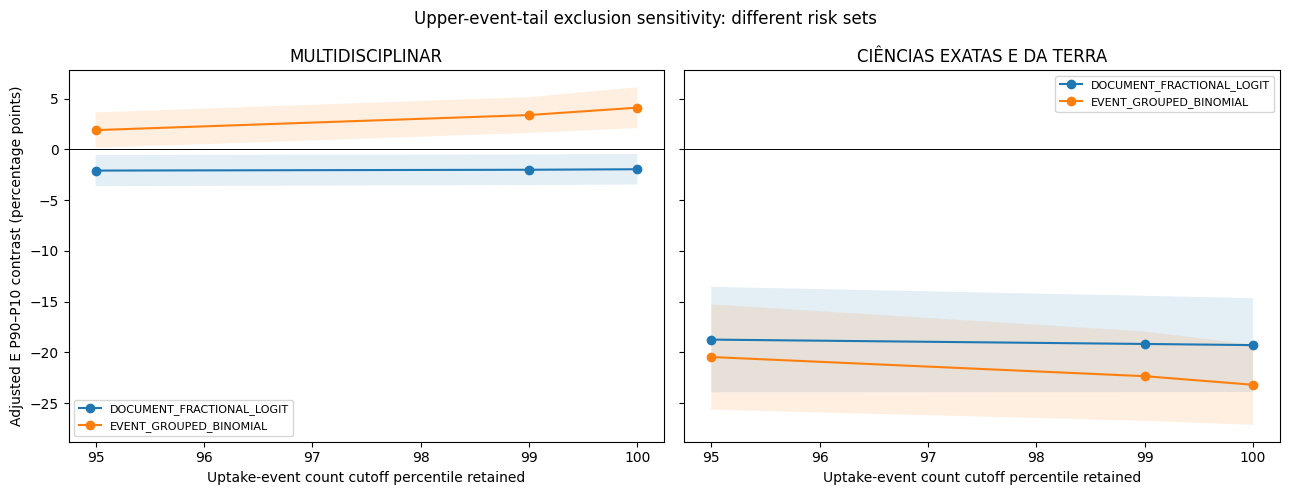

COMPLETE: 12 new clustered regressions. Runtime (seconds): 9.1


,area,tail_retained_quantile,max_allowed_events,model,N,N_PPG,percentage_of_area_documents_retained,percentage_of_area_events_retained,contrast_pp,cluster_se_pp,ci95_low_pp,ci95_high_pp,p_value,interpretation
0,MULTIDISCIPLINAR,1.00,767.00,DOCUMENT_FRACTIONAL_LOGIT,54919,808,100.000000,100.000000,-1.954319,0.765644,-3.454982,-0.453657,1.069477e-02,New within-area adjusted association; excludin...
1,MULTIDISCIPLINAR,1.00,767.00,EVENT_GROUPED_BINOMIAL,54919,808,100.000000,100.000000,4.116183,1.027904,2.101491,6.130876,6.216397e-05,New within-area adjusted association; excludin...
2,MULTIDISCIPLINAR,0.99,120.00,DOCUMENT_FRACTIONAL_LOGIT,54372,807,99.003988,85.292841,-2.004744,0.767263,-3.508579,-0.500908,8.979055e-03,New within-area adjusted association; excludin...
3,MULTIDISCIPLINAR,0.99,120.00,EVENT_GROUPED_BINOMIAL,54372,807,99.003988,85.292841,3.387895,0.901260,1.621426,5.154364,1.705486e-04,New within-area adjusted association; excludin...
4,MULTIDISCIPLINAR,0.95,52.00,DOCUMENT_FRACTIONAL_LOGIT,52244,807,95.129190,64.139850,-2.085827,0.784133,-3.622728,-0.548926,7.813086e-03,New within-area adjusted association; excludin...
5,MULTIDISCIPLINAR,0.95,52.00,EVENT_GROUPED_BINOMIAL,52244,807,95.129190,64.139850,1.901573,0.890668,0.155863,3.647283,3.276141e-02,New within-area adjusted association; excludin...
6,CIÊNCIAS EXATAS E DA TERRA,1.00,651.00,DOCUMENT_FRACTIONAL_LOGIT,24598,267,100.000000,100.000000,-19.289884,2.358839,-23.913208,-14.666560,2.893043e-16,New within-area adjusted association; excludin...
7,CIÊNCIAS EXATAS E DA TERRA,1.00,651.00,EVENT_GROUPED_BINOMIAL,24598,267,100.000000,100.000000,-23.196693,2.016395,-27.148827,-19.244558,1.258809e-30,New within-area adjusted association; excludin...
8,CIÊNCIAS EXATAS E DA TERRA,0.99,105.00,DOCUMENT_FRACTIONAL_LOGIT,24353,267,99.003984,84.895041,-19.175921,2.421331,-23.921729,-14.430113,2.383145e-15,New within-area adjusted association; excludin...
9,CIÊNCIAS EXATAS E DA TERRA,0.99,105.00,EVENT_GROUPED_BINOMIAL,24353,267,99.003984,84.895041,-22.352405,2.245869,-26.754308,-17.950501,2.454935e-23,New within-area adjusted association; excludin...


In [49]:
# CELL 45 | Full-data refits for tail-sensitivity, restricted to the two diagnostic areas
# Clearly distinguishes population restrictions from changing weights on the same observations.
import statsmodels.api as sm
from scipy.special import expit
from scipy.stats import norm
assert all(k in globals() for k in ['e_lo','e_hi'])
from time import perf_counter
started=perf_counter(); results45=[]
for area in ['MULTIDISCIPLINAR','CIÊNCIAS EXATAS E DA TERRA']:
  base=z.loc[z[area_key].eq(area)].copy()
  # Compare the original within-area population against samples restricting the upper tail.
  for quant in [1.0,.99,.95]:
    cutoff=float(base.D_HITS_3Y.quantile(quant))
    sub=base.loc[base.D_HITS_3Y.le(cutoff)].copy()
    n=len(sub); groups=pd.factorize(sub.CD_PROGRAMA.astype(str))[0];G=len(np.unique(groups))
    assert n>1000 and G>30
    xx=pd.DataFrame({'Intercept':np.ones(n),'E_C_QQ':sub.E_PCT_AREA_ANO.to_numpy(float)-.5,
          'R_C_QQ':sub.R_PCT_AREA_ANO.to_numpy(float)-.5})
    xx['E_X_R_QQ']=xx.E_C_QQ*xx.R_C_QQ
    # Recover ANO from the original translation risk set via preserved dataframe index.
    year=pd.get_dummies(d.loc[sub.index,'ANO'].astype(str),drop_first=True,dtype=float).reset_index(drop=True)
    xx=pd.concat([xx,year],axis=1)
    X45=np.ascontiguousarray(xx.to_numpy(float));Y=sub.T_CROSS_GRANDE_SHARE.to_numpy(float)
    numerator=sub.T_CROSS_GRANDE_HITS.to_numpy(float);denominator=sub.D_HITS_3Y.to_numpy(float)
    assert np.allclose(numerator/denominator,Y,atol=1e-6)
    assert np.linalg.matrix_rank(X45)==X45.shape[1],f'Singular model design {area}, quantile {quant}'
    for model_type,y in [('DOCUMENT_FRACTIONAL_LOGIT',Y),
                          ('EVENT_GROUPED_BINOMIAL',np.column_stack([numerator,denominator-numerator]))]:
      fit=sm.GLM(y,X45,family=sm.families.Binomial()).fit(
        cov_type='cluster',cov_kwds={'groups':groups},maxiter=100,disp=0)
      assert fit.converged
      def cf(Eraw):
        mat=X45.copy();v=float(Eraw)-.5;mat[:,1]=v;mat[:,3]=v*mat[:,2]
        p=expit(mat@np.asarray(fit.params))
        return float(p.mean()),(mat*(p*(1-p))[:,None]).mean(axis=0)
      lo,glo=cf(e_lo);hi,ghi=cf(e_hi)
      grad=ghi-glo;cov=np.asarray(fit.cov_params());se=np.sqrt(max(float(grad@cov@grad),0))
      diff=hi-lo
      results45.append({'area':area,'tail_retained_quantile':quant,'max_allowed_events':cutoff,
        'model':model_type,'N':n,'N_PPG':G,'percentage_of_area_documents_retained':100*n/len(base),
        'percentage_of_area_events_retained':100*denominator.sum()/base.D_HITS_3Y.sum(),
        'contrast_pp':100*diff,'cluster_se_pp':100*se,
        'ci95_low_pp':100*(diff-1.96*se),'ci95_high_pp':100*(diff+1.96*se),
        'p_value':float(2*norm.sf(abs(diff/se))) if se>0 else np.nan,
        'interpretation':'New within-area adjusted association; excluding upper event tail CHANGES study population'})
    print(area,'event cutoff quantile',quant,'N=',n,'clusters=',G)
tail45=pd.DataFrame(results45)
tail45.to_csv(Q7/'45_upper_event_tail_sensitivity.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(13,5),sharey=True)
for ax,area in zip(axes,['MULTIDISCIPLINAR','CIÊNCIAS EXATAS E DA TERRA']):
  s=tail45[tail45.area.eq(area)].copy()
  for tag,g in s.groupby('model'):
    g=g.sort_values('tail_retained_quantile')
    ax.plot(g.tail_retained_quantile*100,g.contrast_pp,'o-',label=tag)
    ax.fill_between(g.tail_retained_quantile*100,g.ci95_low_pp,g.ci95_high_pp,alpha=.12)
  ax.axhline(0,color='black',linewidth=.7)
  ax.set_xlabel('Uptake-event count cutoff percentile retained')
  ax.set_title(area);ax.legend(fontsize=8)
axes[0].set_ylabel('Adjusted E P90–P10 contrast (percentage points)')
fig.suptitle('Upper-event-tail exclusion sensitivity: different risk sets')
fig.tight_layout();fig.savefig(Q7/'45_event_tail_sensitivity.png',dpi=190);plt.show();plt.close(fig)
print('COMPLETE: 12 new clustered regressions. Runtime (seconds):',round(perf_counter()-started,1))
display(tail45)


# Scientific evidence table and provenance manifest

In [50]:
# CELL 46 | Assemble publishable supplementary statistics and provenance
import json, hashlib
from datetime import datetime, timezone
required=['43_area_event_concentration.csv','44_within_area_decile_gradients.csv',
          '45_upper_event_tail_sensitivity.csv']
assert all((Q7/p).is_file() for p in required)
summary46=tail45.pivot_table(index=['area','tail_retained_quantile','N'],columns='model',
                             values='contrast_pp',aggfunc='first').reset_index()
summary46['event_minus_document_pp']=summary46['EVENT_GROUPED_BINOMIAL']-summary46['DOCUMENT_FRACTIONAL_LOGIT']
summary46['inference_note']='Descriptive cross-model difference; paired CI not estimated for tail-restricted models'
summary46.to_csv(Q7/'46_manuscript_sensitivity_summary.csv',index=False)
assert len(summary46)==6
assets=[]
for p in sorted(Q7.iterdir()):
 if p.is_file():
  h=hashlib.sha256(p.read_bytes()).hexdigest()
  assets.append({'file':p.name,'bytes':p.stat().st_size,'sha256':h})
manifest={'journal':'Quality & Quantity','paper':'Beyond disruption scores: Epistemic Transition Signatures',
          'created_utc':datetime.now(timezone.utc).isoformat(),
          'source_population':'363690 translation-eligible documents; top-tail analyses use smaller risk sets',
          'scope':'Descriptive concentration, emergence-decile gradients, and new subgroup GLM refits',
          'not_claimed':['causality','external criterion validation',
                         'inference for differences between trimmed document/event models',
                         'equal representativeness of CAPES broad areas'],
          'assets':assets}
(Q7/'46_v7_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
print('V7 COMPLETE:',len(assets)+1,'outputs at',Q7)
display(summary46)


V7 COMPLETE: 8 outputs at /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026/QQ_SUBSTANTIVE_V7


model,area,tail_retained_quantile,N,DOCUMENT_FRACTIONAL_LOGIT,EVENT_GROUPED_BINOMIAL,event_minus_document_pp,inference_note
0,CIÊNCIAS EXATAS E DA TERRA,0.95,23368,-18.746643,-20.463207,-1.716563,Descriptive cross-model difference; paired CI ...
1,CIÊNCIAS EXATAS E DA TERRA,0.99,24353,-19.175921,-22.352405,-3.176484,Descriptive cross-model difference; paired CI ...
2,CIÊNCIAS EXATAS E DA TERRA,1.00,24598,-19.289884,-23.196693,-3.906808,Descriptive cross-model difference; paired CI ...
3,MULTIDISCIPLINAR,0.95,52244,-2.085827,1.901573,3.987400,Descriptive cross-model difference; paired CI ...
4,MULTIDISCIPLINAR,0.99,54372,-2.004744,3.387895,5.392639,Descriptive cross-model difference; paired CI ...
5,MULTIDISCIPLINAR,1.00,54919,-1.954319,4.116183,6.070503,Descriptive cross-model difference; paired CI ...


# Paired estimand differences under upper-tail restrictions

In [51]:
# CELL 47 | Paired sandwich inference after event-tail exclusion
import numpy as np, pandas as pd, statsmodels.api as sm
from pathlib import Path
from scipy.special import expit
from scipy.stats import norm
assert all(v in globals() for v in ['d','z','Q7','e_lo','e_hi','area_key'])
Q8=Path(Q7).parent/'QQ_SUBSTANTIVE_V8'; Q8.mkdir(parents=True,exist_ok=True)
AREAS=['MULTIDISCIPLINAR','CIÊNCIAS EXATAS E DA TERRA']
output47=[]
for area in AREAS:
    base=z.loc[z[area_key].eq(area)].copy()
    for cutoff_q in [1.0,0.99,0.95]:
        cutoff=float(base.D_HITS_3Y.quantile(cutoff_q))
        s=base.loc[base.D_HITS_3Y.le(cutoff)].copy()
        n=len(s); cl, uniques=pd.factorize(s.CD_PROGRAMA.astype(str)); G=len(uniques)
        assert n>1000 and G>100
        years=pd.get_dummies(d.loc[s.index,'ANO'].astype(str),drop_first=True,dtype=float).reset_index(drop=True)
        covars=pd.DataFrame({'Intercept':np.ones(n),
              'E_C_QQ':s.E_PCT_AREA_ANO.to_numpy(float)-0.5,
              'R_C_QQ':s.R_PCT_AREA_ANO.to_numpy(float)-0.5})
        covars['E_X_R_QQ']=covars.E_C_QQ*covars.R_C_QQ
        covars=pd.concat([covars,years.add_prefix('YEAR_')],axis=1)
        X=np.ascontiguousarray(covars.to_numpy(dtype=float)); p=X.shape[1]
        assert np.linalg.matrix_rank(X)==p
        den=s.D_HITS_3Y.to_numpy(dtype=float); hits=s.T_CROSS_GRANDE_HITS.to_numpy(dtype=float)
        share=s.T_CROSS_GRANDE_SHARE.to_numpy(dtype=float)
        assert np.all(den>=1) and np.allclose(hits/den,share,atol=1e-6)
        fits={}
        for kind,y in [('document',share),('event',np.column_stack([hits,den-hits]))]:
            fit=sm.GLM(y,X,family=sm.families.Binomial()).fit(
                    cov_type='cluster',cov_kwds={'groups':cl},maxiter=100,disp=0)
            assert fit.converged
            fits[kind]=fit
        def score_influences(fit,trials,successes):
            prob=expit(X@np.asarray(fit.params))
            resid=successes-trials*prob
            grouped=np.zeros((G,p),dtype=float)
            np.add.at(grouped,cl,X*resid[:,None])
            bread=X.T@(X*(trials*prob*(1-prob))[:,None])
            return grouped@np.linalg.pinv(bread,hermitian=True).T
        sd=score_influences(fits['document'],np.ones(n),share)
        se=score_influences(fits['event'],den,hits)
        factor=(G/(G-1))*((n-1)/(n-p))
        VD=factor*sd.T@sd; VE=factor*se.T@se; VED=factor*se.T@sd
        for kind,V in [('document',VD),('event',VE)]:
            V_ref=np.asarray(fits[kind].cov_params())
            err=np.max(np.abs(np.diag(V)-np.diag(V_ref))/np.maximum(np.abs(np.diag(V_ref)),1e-12))
            assert err<0.04, f'Cluster covariance mismatch: {area} q={cutoff_q} {kind}: {err:.3g}'
        def c_f(fit,E):
            x=X.copy(); v=float(E)-.5
            x[:,1]=v; x[:,3]=v*x[:,2]
            prob=expit(x@np.asarray(fit.params))
            return float(prob.mean()),(x*(prob*(1-prob))[:,None]).mean(axis=0)
        effects={}
        for kind,fit in fits.items():
            mlo,glo=c_f(fit,e_lo); mhi,ghi=c_f(fit,e_hi)
            effects[kind]=(mhi-mlo,ghi-glo)
        e,ge=effects['event']; dd,gd=effects['document']
        var=(ge@VE@ge)+(gd@VD@gd)-2*(ge@VED@gd)
        assert var>=-1e-11, f'Negative joint variance: {var}'
        serr=np.sqrt(max(float(var),0)); delta=e-dd
        pval=float(2*norm.sf(abs(delta/serr))) if serr>0 else np.nan
        output47.append(dict(area=area,tail_retained_quantile=cutoff_q,
            maximum_allowed_events=cutoff,N=n,N_PPG=G,
            fraction_documents_retained=n/len(base),
            fraction_events_retained=float(den.sum()/base.D_HITS_3Y.sum()),
            document_contrast_pp=100*dd,event_contrast_pp=100*e,
            event_minus_document_pp=100*delta,paired_se_pp=100*serr,
            ci95_low_pp=100*(delta-1.96*serr),ci95_high_pp=100*(delta+1.96*serr),
            paired_p_value=pval,covariance_checked=True,
            note='Within-risk-set paired clustered inference; between-cutoff changes are descriptive'))
        print(f'{area} q={cutoff_q:.2f}: N={n:,}, clusters={G}, '
              f'event-document={100*delta:+.3f} pp, 95% CI [{100*(delta-1.96*serr):+.3f}, {100*(delta+1.96*serr):+.3f}]')
paired47=pd.DataFrame(output47)
paired47.to_csv(Q8/'47_tail_paired_inference.csv',index=False)
display(paired47)
assert len(paired47)==6 and paired47.covariance_checked.all()


MULTIDISCIPLINAR q=1.00: N=54,919, clusters=808, event-document=+6.071 pp, 95% CI [+4.804, +7.337]
MULTIDISCIPLINAR q=0.99: N=54,372, clusters=807, event-document=+5.393 pp, 95% CI [+4.471, +6.314]
MULTIDISCIPLINAR q=0.95: N=52,244, clusters=807, event-document=+3.987 pp, 95% CI [+3.153, +4.822]
CIÊNCIAS EXATAS E DA TERRA q=1.00: N=24,598, clusters=267, event-document=-3.907 pp, 95% CI [-6.951, -0.863]
CIÊNCIAS EXATAS E DA TERRA q=0.99: N=24,353, clusters=267, event-document=-3.176 pp, 95% CI [-5.820, -0.533]
CIÊNCIAS EXATAS E DA TERRA q=0.95: N=23,368, clusters=267, event-document=-1.717 pp, 95% CI [-3.886, +0.453]


,area,tail_retained_quantile,maximum_allowed_events,N,N_PPG,fraction_documents_retained,fraction_events_retained,document_contrast_pp,event_contrast_pp,event_minus_document_pp,paired_se_pp,ci95_low_pp,ci95_high_pp,paired_p_value,covariance_checked,note
0,MULTIDISCIPLINAR,1.00,767.00,54919,808,1.000000,1.000000,-1.954319,4.116183,6.070503,0.646050,4.804245,7.336761,5.649657e-21,True,Within-risk-set paired clustered inference; be...
1,MULTIDISCIPLINAR,0.99,120.00,54372,807,0.990040,0.852928,-2.004744,3.387895,5.392639,0.469993,4.471453,6.313824,1.784777e-30,True,Within-risk-set paired clustered inference; be...
2,MULTIDISCIPLINAR,0.95,52.00,52244,807,0.951292,0.641399,-2.085827,1.901573,3.987400,0.425746,3.152936,4.821863,7.557195e-21,True,Within-risk-set paired clustered inference; be...
3,CIÊNCIAS EXATAS E DA TERRA,1.00,651.00,24598,267,1.000000,1.000000,-19.289884,-23.196693,-3.906808,1.553209,-6.951097,-0.862520,1.189262e-02,True,Within-risk-set paired clustered inference; be...
4,CIÊNCIAS EXATAS E DA TERRA,0.99,105.00,24353,267,0.990040,0.848950,-19.175921,-22.352405,-3.176484,1.348812,-5.820155,-0.532812,1.852154e-02,True,Within-risk-set paired clustered inference; be...
5,CIÊNCIAS EXATAS E DA TERRA,0.95,43.15,23368,267,0.949996,0.625482,-18.746643,-20.463207,-1.716563,1.106759,-3.885811,0.452684,1.209060e-01,True,Within-risk-set paired clustered inference; be...


# Exact descriptive weight–outcome covariance decomposition

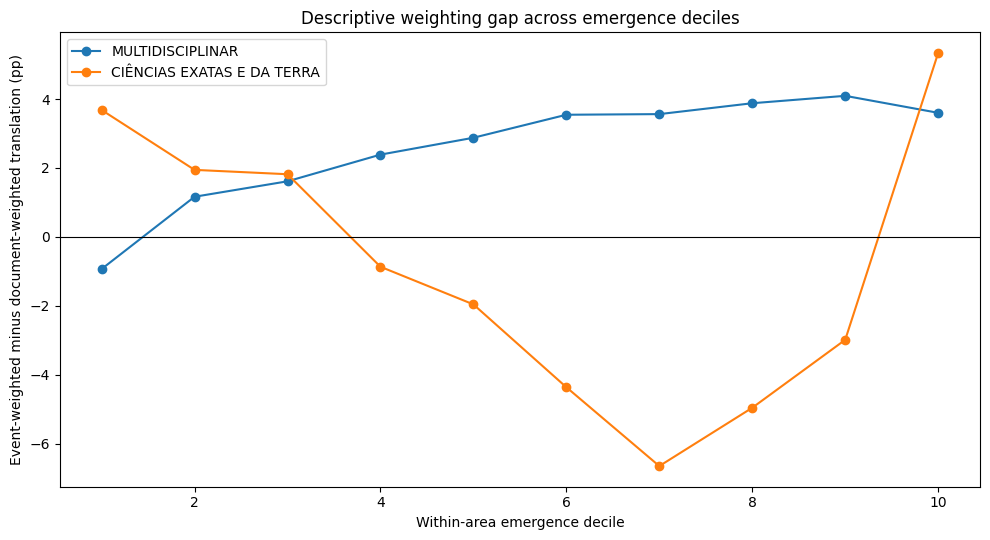

Exact mean-difference identity verified for 66 groups.


,area,tail_retained_quantile,within_area_E_decile,N,total_events,mean_event_weight,document_mean,event_mean,event_minus_document_pp,covariance_weight_share,covariance_identity_pp,corr_weight_share
0,MULTIDISCIPLINAR,1.00,ALL,54919,748887.0,13.636210,0.677594,0.693102,1.550829,0.211474,1.550829,0.025209
11,MULTIDISCIPLINAR,0.99,ALL,54372,638747.0,11.747719,0.677551,0.694713,1.716185,0.201613,1.716185,0.038810
22,MULTIDISCIPLINAR,0.95,ALL,52244,480335.0,9.194070,0.676830,0.694975,1.814588,0.166834,1.814588,0.050673
33,CIÊNCIAS EXATAS E DA TERRA,1.00,ALL,24598,281252.0,11.433938,0.332515,0.387151,5.463587,0.624703,5.463587,0.075354
44,CIÊNCIAS EXATAS E DA TERRA,0.99,ALL,24353,238769.0,9.804500,0.331561,0.381746,5.018495,0.492038,5.018495,0.096476
55,CIÊNCIAS EXATAS E DA TERRA,0.95,ALL,23368,175918.0,7.528158,0.327989,0.368899,4.091022,0.307979,4.091022,0.101056


In [52]:
# CELL 48 | Descriptive decomposition of the unit-of-analysis distinction
import matplotlib.pyplot as plt
assert all(v in globals() for v in ['z','Q8','paired47','area_key'])
rows48=[]
for area in AREAS:
    base=z.loc[z[area_key].eq(area)].copy()
    base['decile']=(pd.qcut(base.E_PCT_AREA_ANO.rank(method='first'),10,labels=False)+1).astype(int)
    for cutoff_q in [1.0,.99,.95]:
        cap=float(base.D_HITS_3Y.quantile(cutoff_q))
        sub=base.loc[base.D_HITS_3Y.le(cap)]
        for decile,grp in [('ALL',sub)]+[(str(i),g) for i,g in sub.groupby('decile',observed=True)]:
            w=grp.D_HITS_3Y.to_numpy(dtype=float)
            y=grp.T_CROSS_GRANDE_SHARE.to_numpy(dtype=float)
            doc=float(y.mean());evt=float(np.average(y,weights=w))
            covariance=float(np.mean((w-w.mean())*(y-y.mean())))
            identity=float(covariance/w.mean())
            assert np.isclose(evt-doc,identity,rtol=1e-9,atol=1e-12)
            rows48.append({'area':area,'tail_retained_quantile':cutoff_q,
                'within_area_E_decile':decile,'N':len(grp),'total_events':w.sum(),
                'mean_event_weight':w.mean(),'document_mean':doc,'event_mean':evt,
                'event_minus_document_pp':100*(evt-doc),
                'covariance_weight_share':covariance,
                'covariance_identity_pp':100*identity,
                'corr_weight_share':np.corrcoef(w,y)[0,1] if w.std()>0 and y.std()>0 else np.nan})
decomp48=pd.DataFrame(rows48)
decomp48.to_csv(Q8/'48_weight_covariance_decomposition.csv',index=False)
fig,ax=plt.subplots(figsize=(10,5.5))
for area in AREAS:
    sub=decomp48.loc[(decomp48.area==area)&(decomp48.tail_retained_quantile==1.0)&(decomp48.within_area_E_decile!='ALL')].copy()
    sub['x']=sub.within_area_E_decile.astype(int)
    ax.plot(sub.x,sub.event_minus_document_pp,marker='o',label=area)
ax.axhline(0,color='black',linewidth=0.8)
ax.set(xlabel='Within-area emergence decile',ylabel='Event-weighted minus document-weighted translation (pp)',
       title='Descriptive weighting gap across emergence deciles')
ax.legend();fig.tight_layout();fig.savefig(Q8/'48_weight_gap_deciles.png',dpi=180);plt.show()
print('Exact mean-difference identity verified for',len(decomp48),'groups.')
display(decomp48.loc[decomp48.within_area_E_decile=='ALL'])


# Publication evidence export and reproducibility ledger

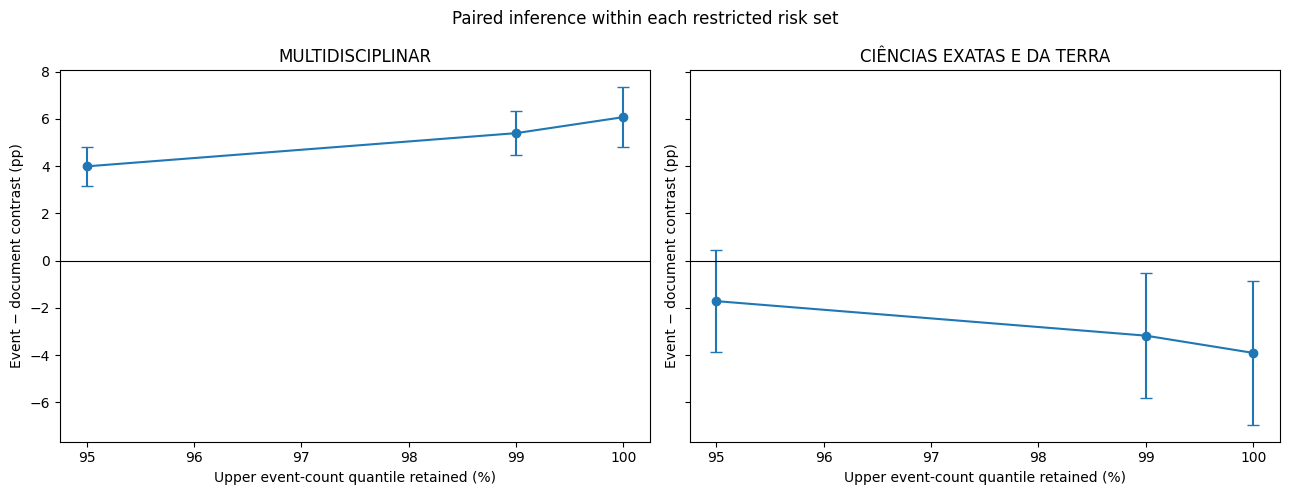

V8 COMPLETE: /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026/QQ_SUBSTANTIVE_V8 | outputs: 7


,area,tail_retained_quantile,N,N_PPG,document_contrast_pp,event_contrast_pp,event_minus_document_pp,paired_se_pp,ci95_low_pp,ci95_high_pp,paired_p_value,fdr_bh_q
0,MULTIDISCIPLINAR,1.00,54919,808,-1.954319,4.116183,6.070503,0.646050,4.804245,7.336761,5.649657e-21,1.511439e-20
1,MULTIDISCIPLINAR,0.99,54372,807,-2.004744,3.387895,5.392639,0.469993,4.471453,6.313824,1.784777e-30,1.070866e-29
2,MULTIDISCIPLINAR,0.95,52244,807,-2.085827,1.901573,3.987400,0.425746,3.152936,4.821863,7.557195e-21,1.511439e-20
3,CIÊNCIAS EXATAS E DA TERRA,1.00,24598,267,-19.289884,-23.196693,-3.906808,1.553209,-6.951097,-0.862520,1.189262e-02,1.783892e-02
4,CIÊNCIAS EXATAS E DA TERRA,0.99,24353,267,-19.175921,-22.352405,-3.176484,1.348812,-5.820155,-0.532812,1.852154e-02,2.222585e-02
5,CIÊNCIAS EXATAS E DA TERRA,0.95,23368,267,-18.746643,-20.463207,-1.716563,1.106759,-3.885811,0.452684,1.209060e-01,1.209060e-01


In [53]:
# CELL 49 | Publication-ready diagnostics and manifest
import json,hashlib
from datetime import datetime,timezone
from scipy.stats import norm
import matplotlib.pyplot as plt
assert all(v in globals() for v in ['paired47','decomp48','Q8'])
fig,axes=plt.subplots(1,2,figsize=(13,5),sharey=True)
for ax,area in zip(axes,AREAS):
    s=paired47.loc[paired47.area==area].sort_values('tail_retained_quantile')
    x=100*s.tail_retained_quantile.to_numpy(float)
    y=s.event_minus_document_pp.to_numpy(float)
    lo=s.ci95_low_pp.to_numpy(float);hi=s.ci95_high_pp.to_numpy(float)
    ax.errorbar(x,y,yerr=[y-lo,hi-y],marker='o',capsize=4)
    ax.axhline(0,color='black',linewidth=.8)
    ax.set(title=area,xlabel='Upper event-count quantile retained (%)',ylabel='Event − document contrast (pp)')
fig.suptitle('Paired inference within each restricted risk set')
fig.tight_layout();fig.savefig(Q8/'49_paired_tail_inference.png',dpi=180);plt.show()
report=paired47[['area','tail_retained_quantile','N','N_PPG','document_contrast_pp','event_contrast_pp',
                  'event_minus_document_pp','paired_se_pp','ci95_low_pp','ci95_high_pp','paired_p_value']].copy()
report['fdr_bh_q']=np.nan
# BH correction applies to the six within-cutoff paired tests as one reported family.
pv=report.paired_p_value.to_numpy(float);order=np.argsort(pv)
qvals=np.minimum.accumulate((pv[order]*len(pv)/np.arange(1,len(pv)+1))[::-1])[::-1]
qout=np.empty(len(pv));qout[order]=np.clip(qvals,0,1)
report['fdr_bh_q']=qout
report.to_csv(Q8/'49_publication_tail_sensitivity_table.csv',index=False)
notes={'scope':'Within-risk-set paired GLM inference; descriptive event-weight covariance decomposition',
       'caveats':['Cutoffs alter document composition; between-cutoff changes have no paired test here',
                  'The covariance identity concerns raw observed means, not regression coefficients',
                  'Models use constructed centred percentiles E_PCT_AREA_ANO and R_PCT_AREA_ANO',
                  'Unobserved human criterion validity is not claimed'],
       'areas':AREAS,'tail_quantiles':[1.0,.99,.95]}
(Q8/'49_interpretation_notes.json').write_text(json.dumps(notes,indent=2,ensure_ascii=False),encoding='utf-8')
files=[]
for f in sorted(Q8.iterdir()):
    if f.is_file():
        files.append({'file':f.name,'bytes':f.stat().st_size,'sha256':hashlib.sha256(f.read_bytes()).hexdigest()})
(Q8/'49_manifest.json').write_text(json.dumps({'journal':'Quality & Quantity',
     'created_utc':datetime.now(timezone.utc).isoformat(),'files':files},indent=2),encoding='utf-8')
assert len(report)==6
print('V8 COMPLETE:',Q8,'| outputs:',len(files)+1)
display(report)


# Same-sample continuous event-weighting experiment

MULTIDISCIPLINAR cap=1.00 lambda=0.00: E P90-P10=-1.954 pp; N=54,919
MULTIDISCIPLINAR cap=1.00 lambda=0.25: E P90-P10=-1.083 pp; N=54,919
MULTIDISCIPLINAR cap=1.00 lambda=0.50: E P90-P10=+0.205 pp; N=54,919
MULTIDISCIPLINAR cap=1.00 lambda=0.75: E P90-P10=+1.942 pp; N=54,919
MULTIDISCIPLINAR cap=1.00 lambda=1.00: E P90-P10=+4.116 pp; N=54,919
MULTIDISCIPLINAR cap=0.99 lambda=0.00: E P90-P10=-1.954 pp; N=54,919
MULTIDISCIPLINAR cap=0.99 lambda=0.25: E P90-P10=-1.093 pp; N=54,919
MULTIDISCIPLINAR cap=0.99 lambda=0.50: E P90-P10=+0.166 pp; N=54,919
MULTIDISCIPLINAR cap=0.99 lambda=0.75: E P90-P10=+1.844 pp; N=54,919
MULTIDISCIPLINAR cap=0.99 lambda=1.00: E P90-P10=+3.916 pp; N=54,919
MULTIDISCIPLINAR cap=0.95 lambda=0.00: E P90-P10=-1.954 pp; N=54,919
MULTIDISCIPLINAR cap=0.95 lambda=0.25: E P90-P10=-1.137 pp; N=54,919
MULTIDISCIPLINAR cap=0.95 lambda=0.50: E P90-P10=+0.012 pp; N=54,919
MULTIDISCIPLINAR cap=0.95 lambda=0.75: E P90-P10=+1.473 pp; N=54,919
MULTIDISCIPLINAR cap=0.95 lambda=1

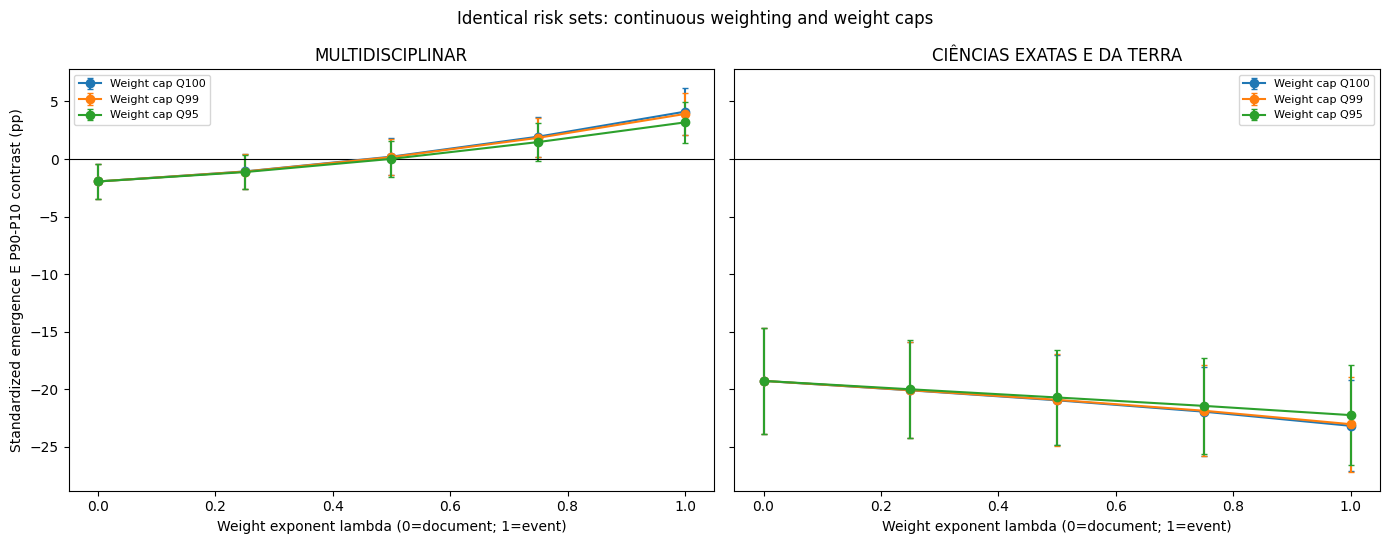

Cell 50 complete: 30 full-data models in 20.9 seconds


,area,cap_quantile,lambda,N,N_PPG,cap_events,total_weight,effective_weighted_n,mean_pred_E_p10,mean_pred_E_p90,E_contrast_pp,cluster_se_pp,ci95_low_pp,ci95_high_pp,p_value,mean_share_weighted,model,risk_set
0,MULTIDISCIPLINAR,1.00,0.0,54919,808,767.00,54919.000000,54919.000000,0.686752,0.667209,-1.954319,0.765644,-3.454982,-0.453657,1.069477e-02,0.677594,weighted_binomial_quasilikelihood,identical rows at every lambda and cap within ...
2,MULTIDISCIPLINAR,1.00,0.5,54919,808,767.00,163623.106199,35749.747134,0.687545,0.689594,0.204880,0.806023,-1.374926,1.784686,7.993519e-01,0.687945,weighted_binomial_quasilikelihood,identical rows at every lambda and cap within ...
4,MULTIDISCIPLINAR,1.00,1.0,54919,808,767.00,748887.000000,11209.786269,0.686575,0.727737,4.116184,1.027904,2.101491,6.130876,6.216389e-05,0.693102,weighted_binomial_quasilikelihood,identical rows at every lambda and cap within ...
5,MULTIDISCIPLINAR,0.99,0.0,54919,808,120.00,54919.000000,54919.000000,0.686752,0.667209,-1.954319,0.765644,-3.454982,-0.453657,1.069477e-02,0.677594,weighted_binomial_quasilikelihood,identical rows at every lambda and cap within ...
7,MULTIDISCIPLINAR,0.99,0.5,54919,808,120.00,162021.754137,37267.934834,0.687632,0.689295,0.166350,0.797669,-1.397082,1.729782,8.348036e-01,0.687976,weighted_binomial_quasilikelihood,identical rows at every lambda and cap within ...
9,MULTIDISCIPLINAR,0.99,1.0,54919,808,120.00,704387.000000,16319.343976,0.686481,0.725637,3.915593,0.941512,2.070229,5.760957,3.198775e-05,0.693509,weighted_binomial_quasilikelihood,identical rows at every lambda and cap within ...
10,MULTIDISCIPLINAR,0.95,0.0,54919,808,52.00,54919.000000,54919.000000,0.686752,0.667209,-1.954319,0.765644,-3.454982,-0.453657,1.069477e-02,0.677594,weighted_binomial_quasilikelihood,identical rows at every lambda and cap within ...
12,MULTIDISCIPLINAR,0.95,0.5,54919,808,52.00,157081.774038,39834.177492,0.688078,0.688195,0.011746,0.792513,-1.541580,1.565071,9.881753e-01,0.688002,weighted_binomial_quasilikelihood,identical rows at every lambda and cap within ...
14,MULTIDISCIPLINAR,0.95,1.0,54919,808,52.00,619435.000000,22178.368152,0.687697,0.719533,3.183604,0.901766,1.416143,4.951066,4.149162e-04,0.694423,weighted_binomial_quasilikelihood,identical rows at every lambda and cap within ...
15,CIÊNCIAS EXATAS E DA TERRA,1.00,0.0,24598,267,651.00,24598.000000,24598.000000,0.429379,0.236481,-19.289884,2.358839,-23.913208,-14.666560,2.893043e-16,0.332515,weighted_binomial_quasilikelihood,identical rows at every lambda and cap within ...


In [54]:
# CELL 50 | Same-sample weight continuum and upper-weight winsorization (new regressions)
import numpy as np, pandas as pd, statsmodels.api as sm, matplotlib.pyplot as plt
from pathlib import Path
from scipy.special import expit
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests
from time import perf_counter
assert all(v in globals() for v in ['d','z','area_key','e_lo','e_hi','Q8']), 'Run through cell 49 in this Colab session.'
Q9=Path(Q8).parent/'QQ_SUBSTANTIVE_V9'; Q9.mkdir(parents=True,exist_ok=True)
Q9_AREAS=['MULTIDISCIPLINAR','CIÊNCIAS EXATAS E DA TERRA']
Q9_LAMBDAS=[0.0,0.25,0.5,0.75,1.0]
Q9_CAPS=[1.0,0.99,0.95]
Q9_PACK={};Q9_ROWS=[]
started=perf_counter()
for area in Q9_AREAS:
    s=z.loc[z[area_key].eq(area)].copy()
    n=len(s)
    yy=pd.get_dummies(d.loc[s.index,'ANO'].astype(str),drop_first=True,dtype=float).reset_index(drop=True)
    cov=pd.DataFrame({'Intercept':np.ones(n),
       'E_C_QQ':s.E_PCT_AREA_ANO.to_numpy(float)-.5,
       'R_C_QQ':s.R_PCT_AREA_ANO.to_numpy(float)-.5})
    cov['E_X_R_QQ']=cov.E_C_QQ*cov.R_C_QQ
    cov=pd.concat([cov,yy.add_prefix('YEAR_')],axis=1)
    X=np.ascontiguousarray(cov.to_numpy(float))
    p=X.shape[1]
    assert np.linalg.matrix_rank(X)==p,(area,'rank deficiency')
    cl,ppg=pd.factorize(s.CD_PROGRAMA.astype(str));G=len(ppg)
    assert G>=200 and n>20000
    H=s.D_HITS_3Y.to_numpy(float)
    share=s.T_CROSS_GRANDE_SHARE.to_numpy(float)
    hits=s.T_CROSS_GRANDE_HITS.to_numpy(float)
    assert np.isfinite(H).all() and np.all(H>=1)
    assert np.isfinite(share).all() and np.all((share>=0)&(share<=1))
    assert np.allclose(hits/H,share,atol=1e-6)
    Q9_PACK[area]={'X':X,'cl':cl,'G':G,'H':H,'y':share,'N':n,'p':p}
    for cap_q in Q9_CAPS:
        threshold=float(np.quantile(H,cap_q))
        capped=np.minimum(H,threshold)
        for lam in Q9_LAMBDAS:
            w=capped**lam
            # Grouped pseudo-counts are the weighted binomial quasi-likelihood;
            # fractional counts for intermediate lambda are not literal events.
            yy=np.column_stack([w*share,w*(1-share)])
            fit=sm.GLM(yy,X,family=sm.families.Binomial()).fit(
                  cov_type='cluster',cov_kwds={'groups':cl},maxiter=100,disp=0)
            assert fit.converged,(area,cap_q,lam)
            def counterfactual(e):
                mat=X.copy();v=float(e)-.5
                mat[:,1]=v;mat[:,3]=v*mat[:,2]
                prob=expit(mat@np.asarray(fit.params))
                return float(prob.mean()),np.mean(mat*(prob*(1-prob))[:,None],axis=0)
            lo,glo=counterfactual(e_lo);hi,ghi=counterfactual(e_hi)
            grad=ghi-glo;beta_effect=hi-lo
            V=np.asarray(fit.cov_params());var=float(grad@V@grad)
            assert var>=-1e-12
            se=np.sqrt(max(var,0.))
            Q9_ROWS.append({'area':area,'cap_quantile':cap_q,'lambda':lam,
                'N':n,'N_PPG':G,'cap_events':threshold,'total_weight':float(w.sum()),
                'effective_weighted_n':float(w.sum()**2/np.dot(w,w)),
                'mean_pred_E_p10':lo,'mean_pred_E_p90':hi,'E_contrast_pp':100*beta_effect,
                'cluster_se_pp':100*se,'ci95_low_pp':100*(beta_effect-1.96*se),
                'ci95_high_pp':100*(beta_effect+1.96*se),
                'p_value':float(2*norm.sf(abs(beta_effect/se))) if se>0 else np.nan,
                'mean_share_weighted':float(np.average(share,weights=w)),
                'model':'weighted_binomial_quasilikelihood',
                'risk_set':'identical rows at every lambda and cap within area'})
            Q9_PACK[area][(cap_q,lam)]={'fit':fit,'w':w,'effect':beta_effect,'grad':grad}
            print(f'{area} cap={cap_q:.2f} lambda={lam:.2f}: '
                  f'E P90-P10={100*beta_effect:+.3f} pp; N={n:,}')
Q9_WEIGHT_GRID=pd.DataFrame(Q9_ROWS)
assert len(Q9_WEIGHT_GRID)==30
assert Q9_WEIGHT_GRID.groupby('area').N.nunique().eq(1).all()
Q9_WEIGHT_GRID.to_csv(Q9/'50_weight_continuum_contrasts.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(14,5.5),sharey=True)
for aa,area in zip(ax,Q9_AREAS):
    for cap_q in Q9_CAPS:
        a=Q9_WEIGHT_GRID.loc[(Q9_WEIGHT_GRID.area==area)&(Q9_WEIGHT_GRID.cap_quantile==cap_q)].sort_values('lambda')
        aa.errorbar(a['lambda'],a.E_contrast_pp,
            yerr=[a.E_contrast_pp-a.ci95_low_pp,a.ci95_high_pp-a.E_contrast_pp],
            marker='o',capsize=2,label=f'Weight cap Q{int(cap_q*100)}')
    aa.axhline(0,color='black',lw=.8);aa.set(title=area,xlabel='Weight exponent lambda (0=document; 1=event)')
    aa.legend(fontsize=8)
ax[0].set_ylabel('Standardized emergence E P90-P10 contrast (pp)')
fig.suptitle('Identical risk sets: continuous weighting and weight caps')
fig.tight_layout();fig.savefig(Q9/'50_continuous_weighting.png',dpi=190);plt.show();plt.close(fig)
print('Cell 50 complete:',len(Q9_WEIGHT_GRID),'full-data models in',round(perf_counter()-started,1),'seconds')
display(Q9_WEIGHT_GRID.loc[Q9_WEIGHT_GRID['lambda'].isin([0.,.5,1.])])

# Paired clustered inference for weight-cap interventions

In [55]:
# CELL 51 | Joint four-model sandwich for same-sample weight-cap sensitivity
from scipy.stats import norm
assert all(k in globals() for k in ['Q9','Q9_PACK','Q9_WEIGHT_GRID','Q9_AREAS','Q9_CAPS'])
Q9_TESTS=[]
for area in Q9_AREAS:
    obj=Q9_PACK[area]
    X,cl,G,H,y,n,p=[obj[v] for v in ('X','cl','G','H','y','N','p')]
    correction=(G/(G-1))*((n-1)/(n-p))
    influence={}
    for cap in Q9_CAPS:
        for lam in (0.,1.):
            record=obj[(cap,lam)];fit,w=record['fit'],record['w']
            prob=expit(X@np.asarray(fit.params))
            score=w*(y-prob)
            cluster_score=np.zeros((G,p),dtype=float)
            np.add.at(cluster_score,cl,X*score[:,None])
            bread=X.T@(X*(w*prob*(1-prob))[:,None])
            infl=cluster_score@np.linalg.pinv(bread,hermitian=True).T
            influence[(cap,lam)]=infl
            V=correction*infl.T@infl
            vref=np.asarray(fit.cov_params())
            rel=np.max(np.abs(np.diag(V)-np.diag(vref))/np.maximum(np.abs(np.diag(vref)),1e-12))
            assert rel<.04,f'Sandwich mismatch: {area}, {cap}, {lam}, {rel}'
    def paired_linear(terms):
        # For each (cap,lambda) the gradient maps a coefficient change into the
        # standardized E P90-P10 contrast. Combine influence at program level.
        point=0.0;cluster_effect=np.zeros(G,dtype=float)
        for coeff,cap,lam in terms:
            rec=obj[(cap,lam)]
            point+=coeff*rec['effect']
            cluster_effect+=coeff*(influence[(cap,lam)]@rec['grad'])
        se=np.sqrt(max(float(correction*np.dot(cluster_effect,cluster_effect)),0))
        pp=float(2*norm.sf(abs(point/se))) if se>0 else np.nan
        return dict(estimate_pp=100*point,se_pp=100*se,
            ci95_low_pp=100*(point-1.96*se),ci95_high_pp=100*(point+1.96*se),p_value=pp)
    for cap in Q9_CAPS:
        res=paired_linear([(1.,cap,1.),(-1.,cap,0.)])
        Q9_TESTS.append({'area':area,'cap_quantile':cap,
            'comparison':'event minus document within cap',**res,'N':n,'N_PPG':G})
    for cap in (.99,.95):
        # Difference in weighting gaps, capped minus uncapped: four estimators.
        res=paired_linear([(1.,cap,1.),(-1.,cap,0.),(-1.,1.,1.),(1.,1.,0.)])
        Q9_TESTS.append({'area':area,'cap_quantile':cap,
            'comparison':'capped gap minus uncapped gap on identical rows',**res,'N':n,'N_PPG':G})
Q9_INFERENCE=pd.DataFrame(Q9_TESTS)
assert len(Q9_INFERENCE)==10
Q9_INFERENCE['fdr_bh_q']=multipletests(Q9_INFERENCE.p_value,method='fdr_bh')[1]
Q9_INFERENCE.to_csv(Q9/'51_joint_cap_inference.csv',index=False)
print('PASS: 10 joint, same-document PPG-cluster contrasts; 30 regressions without dropping tail documents.')
display(Q9_INFERENCE)

PASS: 10 joint, same-document PPG-cluster contrasts; 30 regressions without dropping tail documents.


,area,cap_quantile,comparison,estimate_pp,se_pp,ci95_low_pp,ci95_high_pp,p_value,N,N_PPG,fdr_bh_q
0,MULTIDISCIPLINAR,1.00,event minus document within cap,6.070503,0.646050,4.804245,7.336761,5.649631e-21,54919,808,1.883210e-20
1,MULTIDISCIPLINAR,0.99,event minus document within cap,5.869912,0.519764,4.851176,6.888649,1.414178e-29,54919,808,7.070890e-29
2,MULTIDISCIPLINAR,0.95,event minus document within cap,5.137924,0.446394,4.262992,6.012856,1.176940e-30,54919,808,1.176940e-29
3,MULTIDISCIPLINAR,0.99,capped gap minus uncapped gap on identical rows,-0.200591,0.225297,-0.642172,0.240991,3.732840e-01,54919,808,4.147600e-01
4,MULTIDISCIPLINAR,0.95,capped gap minus uncapped gap on identical rows,-0.932579,0.334403,-1.588009,-0.277150,5.290525e-03,54919,808,1.322631e-02
5,CIÊNCIAS EXATAS E DA TERRA,1.00,event minus document within cap,-3.906808,1.553209,-6.951097,-0.862520,1.189262e-02,24598,267,1.698945e-02
6,CIÊNCIAS EXATAS E DA TERRA,0.99,event minus document within cap,-3.764013,1.393138,-6.494563,-1.033463,6.896027e-03,24598,267,1.379205e-02
7,CIÊNCIAS EXATAS E DA TERRA,0.95,event minus document within cap,-2.975681,1.175195,-5.279064,-0.672298,1.133904e-02,24598,267,1.698945e-02
8,CIÊNCIAS EXATAS E DA TERRA,0.99,capped gap minus uncapped gap on identical rows,0.142795,0.347561,-0.538424,0.824015,6.811830e-01,24598,267,6.811830e-01
9,CIÊNCIAS EXATAS E DA TERRA,0.95,capped gap minus uncapped gap on identical rows,0.931128,0.628039,-0.299830,2.162085,1.381822e-01,24598,267,1.727278e-01


# Interpretation, comparability and frozen evidence export

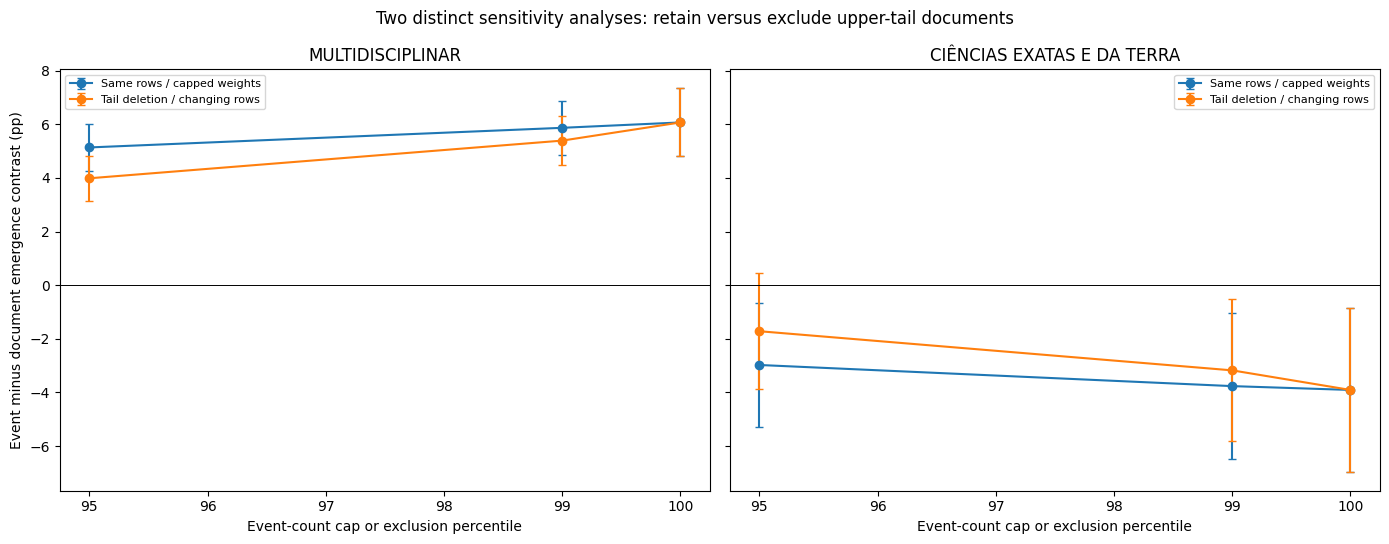

V9 COMPLETE — 30 same-row model fits and 10 joint clustered contrasts.
Outputs: /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026/QQ_SUBSTANTIVE_V9 count: 7


,area,quantile,same_rows_weight_capped_gap_pp,same_rows_weight_capped_ci_low_pp,same_rows_weight_capped_ci_high_pp,different_rows_tail_deleted_gap_pp,different_rows_tail_deleted_ci_low_pp,different_rows_tail_deleted_ci_high_pp,full_area_N,tail_deleted_N,warning
0,MULTIDISCIPLINAR,1.00,6.070503,4.804245,7.336761,6.070503,4.804245,7.336761,54919,54919,Separate sensitivity definitions; cross-design...
1,MULTIDISCIPLINAR,0.99,5.869912,4.851176,6.888649,5.392639,4.471453,6.313824,54919,54372,Separate sensitivity definitions; cross-design...
2,MULTIDISCIPLINAR,0.95,5.137924,4.262992,6.012856,3.987400,3.152936,4.821863,54919,52244,Separate sensitivity definitions; cross-design...
3,CIÊNCIAS EXATAS E DA TERRA,1.00,-3.906808,-6.951097,-0.862520,-3.906808,-6.951097,-0.862520,24598,24598,Separate sensitivity definitions; cross-design...
4,CIÊNCIAS EXATAS E DA TERRA,0.99,-3.764013,-6.494563,-1.033463,-3.176484,-5.820155,-0.532812,24598,24353,Separate sensitivity definitions; cross-design...
5,CIÊNCIAS EXATAS E DA TERRA,0.95,-2.975681,-5.279064,-0.672298,-1.716563,-3.885811,0.452684,24598,23368,Separate sensitivity definitions; cross-design...


In [56]:
# CELL 52 | Comparative evidence and final manifest for V9
import hashlib,json
from datetime import datetime,timezone
assert all(k in globals() for k in ['Q9','Q9_WEIGHT_GRID','Q9_INFERENCE','paired47'])
compare=[]
for area in Q9_AREAS:
  for cap in [1.,.99,.95]:
    same=Q9_INFERENCE.loc[(Q9_INFERENCE.area==area)&
      (Q9_INFERENCE.cap_quantile==cap)&
      (Q9_INFERENCE.comparison=='event minus document within cap')].iloc[0]
    drop=paired47.loc[(paired47.area==area)&(paired47.tail_retained_quantile==cap)].iloc[0]
    compare.append({'area':area,'quantile':cap,
      'same_rows_weight_capped_gap_pp':same.estimate_pp,
      'same_rows_weight_capped_ci_low_pp':same.ci95_low_pp,
      'same_rows_weight_capped_ci_high_pp':same.ci95_high_pp,
      'different_rows_tail_deleted_gap_pp':drop.event_minus_document_pp,
      'different_rows_tail_deleted_ci_low_pp':drop.ci95_low_pp,
      'different_rows_tail_deleted_ci_high_pp':drop.ci95_high_pp,
      'full_area_N':int(Q9_PACK[area]['N']),'tail_deleted_N':int(drop.N),
      'warning':'Separate sensitivity definitions; cross-design differences not formally tested'})
Q9_COMPARISON=pd.DataFrame(compare)
Q9_COMPARISON.to_csv(Q9/'52_weight_capping_vs_tail_deletion.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(14,5.5),sharey=True)
for ax,area in zip(axs,Q9_AREAS):
   part=Q9_COMPARISON.loc[Q9_COMPARISON.area.eq(area)].sort_values('quantile')
   xx=100*part['quantile'].to_numpy(float)
   for k,lo,hi,title in [
     ('same_rows_weight_capped_gap_pp','same_rows_weight_capped_ci_low_pp','same_rows_weight_capped_ci_high_pp','Same rows / capped weights'),
     ('different_rows_tail_deleted_gap_pp','different_rows_tail_deleted_ci_low_pp','different_rows_tail_deleted_ci_high_pp','Tail deletion / changing rows')]:
     yy=part[k].to_numpy(float);ll=part[lo].to_numpy(float);hh=part[hi].to_numpy(float)
     ax.errorbar(xx,yy,yerr=[yy-ll,hh-yy],marker='o',capsize=3,label=title)
   ax.axhline(0,color='black',lw=.7);ax.set(title=area,xlabel='Event-count cap or exclusion percentile')
   ax.legend(fontsize=8)
axs[0].set_ylabel('Event minus document emergence contrast (pp)')
fig.suptitle('Two distinct sensitivity analyses: retain versus exclude upper-tail documents')
fig.tight_layout();fig.savefig(Q9/'52_weight_capping_vs_deletion.png',dpi=190);plt.show();plt.close(fig)
notes={
 'journal':'Quality & Quantity — International Journal of Methodology',
 'experiment':'V9: continuous reweighting without excluding documents',
 'design':{'lambda':'weight_i = min(event_count_i, cap_quantile)^lambda',
           'lambda_zero':'equal document weighting',
           'lambda_one':'event-frequency weighting; capped variants are pseudo-events',
           'model':'weighted binomial quasi-likelihood with clustered sandwich covariance',
           'covariates':'centred area-year E/R percentiles, E×R, year fixed effects within area',
           'contrast':'global E p90 minus p10 averaged over within-area observed R and year',
           'same_rows_within_area':True},
 'limitations':['Intermediate and capped weights define sensitivity estimands, not observed integer event trials',
      'Capping and deletion answer different questions; differences between their point estimates are not formal paired tests',
      'Conditional translation is observed only for eligible documents with future uptake',
      'E and R were redefined in this laboratory from archived area-year percentiles, not confirmed literal originals',
      'All estimates are associational, not causal; independent criterion validation was not performed'],
 'paired_inference_records':len(Q9_INFERENCE),
 'complete_model_fits':len(Q9_WEIGHT_GRID)
}
(Q9/'52_scientific_interpretation.json').write_text(json.dumps(notes,indent=2,ensure_ascii=False),encoding='utf-8')
records=[]
for f in sorted(Q9.iterdir()):
 if f.is_file():records.append({'name':f.name,'bytes':f.stat().st_size,
    'sha256':hashlib.sha256(f.read_bytes()).hexdigest()})
(Q9/'52_manifest.json').write_text(json.dumps({'created_utc':datetime.now(timezone.utc).isoformat(),
  'notebook_stage':'V9','files':records},indent=2),encoding='utf-8')
print('V9 COMPLETE — 30 same-row model fits and 10 joint clustered contrasts.')
print('Outputs:',Q9,'count:',len(records)+1)
display(Q9_COMPARISON)

# Eight-area same-sample reweighting: 48 new regression fits

In [57]:
# CELL 53 | Generalize same-sample weighting from two to all eight eligible CAPES areas
import numpy as np, pandas as pd, statsmodels.api as sm, matplotlib.pyplot as plt
from pathlib import Path
from scipy.special import expit
from scipy.stats import norm
from time import perf_counter
assert all(v in globals() for v in ['d','z','area_key','e_lo','e_hi','Q9']), 'Run the original lab through cell 52 first.'
Q10=Path(Q9).parent/'QQ_EIGHT_AREA_WEIGHTING_V10'
Q10.mkdir(parents=True,exist_ok=True)
Q10_AREAS=sorted(z[area_key].dropna().unique().tolist())
assert len(Q10_AREAS)==8, f'Unexpected area count: {len(Q10_AREAS)}. Review the translation risk set.'
Q10_CAPS=(1.,.95)
Q10_LAMBDAS=(0.,.5,1.)
Q10_FITS={};Q10_ROWS=[]
start=perf_counter()
for area in Q10_AREAS:
    s=z.loc[z[area_key].eq(area)].copy()
    n=len(s)
    years=pd.get_dummies(d.loc[s.index,'ANO'].astype(str),drop_first=True,dtype=float).reset_index(drop=True)
    E=s.E_PCT_AREA_ANO.to_numpy(float)-.5
    R=s.R_PCT_AREA_ANO.to_numpy(float)-.5
    cov=pd.DataFrame({'Intercept':np.ones(n),'E_C_QQ':E,'R_C_QQ':R,'E_X_R_QQ':E*R})
    cov=pd.concat([cov,years.add_prefix('YEAR_')],axis=1)
    X=np.ascontiguousarray(cov.to_numpy(float));p=X.shape[1]
    assert np.linalg.matrix_rank(X)==p, f'Rank deficient {area}'
    cl,ppg=pd.factorize(s.CD_PROGRAMA.astype(str));G=len(ppg)
    H=s.D_HITS_3Y.to_numpy(float)
    y=s.T_CROSS_GRANDE_SHARE.to_numpy(float)
    hits=s.T_CROSS_GRANDE_HITS.to_numpy(float)
    assert n>1000 and G>30 and np.all(H>=1) and np.isfinite(H).all()
    assert np.isfinite(y).all() and np.all((y>=0)&(y<=1))
    assert np.allclose(hits/H,y,atol=1e-6),f'Cross-area share identity failed: {area}'
    Q10_FITS[area]={'X':X,'cl':cl,'G':G,'N':n,'p':p,'H':H,'y':y,'entries':{}}
    for cap in Q10_CAPS:
        cut=float(np.quantile(H,cap))
        capped=np.minimum(H,cut)
        for lam in Q10_LAMBDAS:
            w=capped**lam
            response=np.column_stack((w*y,w*(1-y)))
            fit=sm.GLM(response,X,family=sm.families.Binomial()).fit(
                cov_type='cluster',cov_kwds={'groups':cl},maxiter=100,disp=0)
            assert fit.converged,(area,cap,lam)
            beta=np.asarray(fit.params)
            def prediction(Elevel):
                XX=X.copy();v=float(Elevel)-.5
                XX[:,1]=v;XX[:,3]=v*XX[:,2]
                prob=expit(XX@beta)
                return float(prob.mean()),np.mean(XX*(prob*(1-prob))[:,None],axis=0)
            lo,glo=prediction(e_lo);hi,ghi=prediction(e_hi)
            contrast=hi-lo;grad=ghi-glo
            se=np.sqrt(max(float(grad@np.asarray(fit.cov_params())@grad),0))
            Q10_FITS[area]['entries'][(cap,lam)]={'fit':fit,'w':w,'effect':contrast,'grad':grad}
            Q10_ROWS.append({'area':area,'cap_quantile':cap,'lambda':lam,'N':n,'N_PPG':G,
                'event_cap':cut,'effective_weighted_n':float(w.sum()**2/np.dot(w,w)),
                'E_p10':e_lo,'E_p90':e_hi,'contrast_pp':100*contrast,'se_pp':100*se,
                'ci95_low_pp':100*(contrast-1.96*se),'ci95_high_pp':100*(contrast+1.96*se),
                'pred_low':lo,'pred_high':hi,'outcome':'Cross-broad-area future uptake share',
                'estimation':'Clustered weighted binomial quasi-likelihood; same documents within area'})
    print(f'{area}: {n:,} documents, {G:,} PPG clusters; completed 6 models')
Q10_GRID=pd.DataFrame(Q10_ROWS)
assert len(Q10_GRID)==8*2*3
assert Q10_GRID.groupby('area').N.nunique().eq(1).all()
Q10_GRID.to_csv(Q10/'53_eight_area_weight_grid.csv',index=False)
print('COMPLETED:',len(Q10_GRID),'models in',round(perf_counter()-start,1),'seconds.')
display(Q10_GRID.loc[(Q10_GRID.cap_quantile==1.)&(Q10_GRID['lambda'].isin([0.,1.]))][['area','lambda','N','contrast_pp','ci95_low_pp','ci95_high_pp']])

CIÊNCIAS AGRÁRIAS: 39,518 documents, 449 PPG clusters; completed 6 models
CIÊNCIAS BIOLÓGICAS: 25,240 documents, 327 PPG clusters; completed 6 models
CIÊNCIAS DA SAÚDE: 59,189 documents, 658 PPG clusters; completed 6 models
CIÊNCIAS EXATAS E DA TERRA: 24,598 documents, 267 PPG clusters; completed 6 models
CIÊNCIAS HUMANAS: 61,821 documents, 651 PPG clusters; completed 6 models
CIÊNCIAS SOCIAIS APLICADAS: 55,971 documents, 643 PPG clusters; completed 6 models
ENGENHARIAS: 42,434 documents, 461 PPG clusters; completed 6 models
MULTIDISCIPLINAR: 54,919 documents, 808 PPG clusters; completed 6 models
COMPLETED: 48 models in 35.6 seconds.


,area,lambda,N,contrast_pp,ci95_low_pp,ci95_high_pp
0,CIÊNCIAS AGRÁRIAS,0.0,39518,-9.752381,-10.999968,-8.504795
2,CIÊNCIAS AGRÁRIAS,1.0,39518,-11.227462,-13.341382,-9.113542
6,CIÊNCIAS BIOLÓGICAS,0.0,25240,-16.250393,-18.168306,-14.332481
8,CIÊNCIAS BIOLÓGICAS,1.0,25240,-16.687273,-20.181727,-13.192820
12,CIÊNCIAS DA SAÚDE,0.0,59189,-0.815818,-2.486863,0.855226
14,CIÊNCIAS DA SAÚDE,1.0,59189,-0.286776,-2.731395,2.157843
18,CIÊNCIAS EXATAS E DA TERRA,0.0,24598,-19.289884,-23.913208,-14.666560
20,CIÊNCIAS EXATAS E DA TERRA,1.0,24598,-23.196693,-27.148827,-19.244558
24,CIÊNCIAS HUMANAS,0.0,61821,-7.783473,-9.268709,-6.298237
26,CIÊNCIAS HUMANAS,1.0,61821,-8.088223,-9.844888,-6.331558


# Joint PPG-cluster inference and eight-area heterogeneity evidence

In [58]:
# CELL 54 | Joint cluster influence functions for all eight areas, same documents in each test
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests
assert all(k in globals() for k in ('Q10','Q10_FITS','Q10_GRID','Q10_AREAS'))
Q10_TESTS=[]
for area in Q10_AREAS:
    obj=Q10_FITS[area];X=obj['X'];cl=obj['cl'];G=obj['G'];n=obj['N'];p=obj['p'];y=obj['y']
    correction=G/(G-1)*(n-1)/(n-p)
    IF={}
    for cap in Q10_CAPS:
        for lam in (0.,1.):
            rec=obj['entries'][(cap,lam)];fit,w=rec['fit'],rec['w']
            prob=expit(X@np.asarray(fit.params));score=w*(y-prob)
            clusters=np.zeros((G,p));np.add.at(clusters,cl,X*score[:,None])
            bread=X.T@(X*(w*prob*(1-prob))[:,None])
            influence=clusters@np.linalg.pinv(bread,hermitian=True).T
            check=correction*influence.T@influence
            archived=np.asarray(fit.cov_params())
            relative=float(np.max(np.abs(np.diag(check)-np.diag(archived))/np.maximum(np.abs(np.diag(archived)),1e-12)))
            assert relative<.04,('covariance disagreement',area,cap,lam,relative)
            IF[(cap,lam)]=influence
    def contrast(terms):
        point=0.;influence=np.zeros(G)
        for coefficient,cap,lam in terms:
            rec=obj['entries'][(cap,lam)]
            point+=coefficient*rec['effect']
            influence+=coefficient*(IF[(cap,lam)]@rec['grad'])
        se=np.sqrt(max(correction*float(influence@influence),0.))
        return {'estimate_pp':100*point,'se_pp':100*se,
            'ci95_low_pp':100*(point-1.96*se),'ci95_high_pp':100*(point+1.96*se),
            'p_value':float(2*norm.sf(abs(point/se))) if se>0 else np.nan}
    for cap in Q10_CAPS:
        Q10_TESTS.append({'area':area,'comparison':'Event minus document',
            'cap_quantile':cap,'N':n,'N_PPG':G,**contrast([(1,cap,1),(-1,cap,0)])})
    Q10_TESTS.append({'area':area,'comparison':'Capped Q95 gap minus uncapped gap',
        'cap_quantile':.95,'N':n,'N_PPG':G,
        **contrast([(1,.95,1),(-1,.95,0),(-1,1.,1),(1,1.,0)])})
Q10_JOINT=pd.DataFrame(Q10_TESTS)
assert len(Q10_JOINT)==24
Q10_JOINT['fdr_bh_q']=np.nan
# Adjust within predefined families of 8 tests, not across unrelated comparisons.
for (comparison,cap),ix in Q10_JOINT.groupby(['comparison','cap_quantile']).groups.items():
    Q10_JOINT.loc[ix,'fdr_bh_q']=multipletests(Q10_JOINT.loc[ix,'p_value'],method='fdr_bh')[1]
Q10_JOINT.to_csv(Q10/'54_eight_area_paired_cluster_tests.csv',index=False)
print('PASS: 24 joint clustered comparisons; BH correction within three predefined eight-area families.')
display(Q10_JOINT[['area','comparison','cap_quantile','estimate_pp','ci95_low_pp','ci95_high_pp','p_value','fdr_bh_q']])

PASS: 24 joint clustered comparisons; BH correction within three predefined eight-area families.


,area,comparison,cap_quantile,estimate_pp,ci95_low_pp,ci95_high_pp,p_value,fdr_bh_q
0,CIÊNCIAS AGRÁRIAS,Event minus document,1.00,-1.475081,-3.083813,0.133652,7.230943e-02,1.928252e-01
1,CIÊNCIAS AGRÁRIAS,Event minus document,0.95,0.517305,-0.418448,1.453059,2.785727e-01,3.183688e-01
2,CIÊNCIAS AGRÁRIAS,Capped Q95 gap minus uncapped gap,0.95,1.992386,0.931417,3.053355,2.326233e-04,1.860986e-03
3,CIÊNCIAS BIOLÓGICAS,Event minus document,1.00,-0.436880,-3.261181,2.387421,7.617490e-01,8.211536e-01
4,CIÊNCIAS BIOLÓGICAS,Event minus document,0.95,0.941730,-0.399647,2.283107,1.688088e-01,2.927009e-01
5,CIÊNCIAS BIOLÓGICAS,Capped Q95 gap minus uncapped gap,0.95,1.378610,-0.601236,3.358456,1.723188e-01,1.969358e-01
6,CIÊNCIAS DA SAÚDE,Event minus document,1.00,0.529042,-1.017931,2.076015,5.026720e-01,7.962784e-01
7,CIÊNCIAS DA SAÚDE,Event minus document,0.95,2.211071,1.235344,3.186799,8.933182e-06,3.573273e-05
8,CIÊNCIAS DA SAÚDE,Capped Q95 gap minus uncapped gap,0.95,1.682029,0.679743,2.684315,1.004521e-03,4.018085e-03
9,CIÊNCIAS EXATAS E DA TERRA,Event minus document,1.00,-3.906808,-6.951097,-0.862520,1.189262e-02,4.757047e-02


# Disciplinary multiverse figures and an eight-area manuscript table

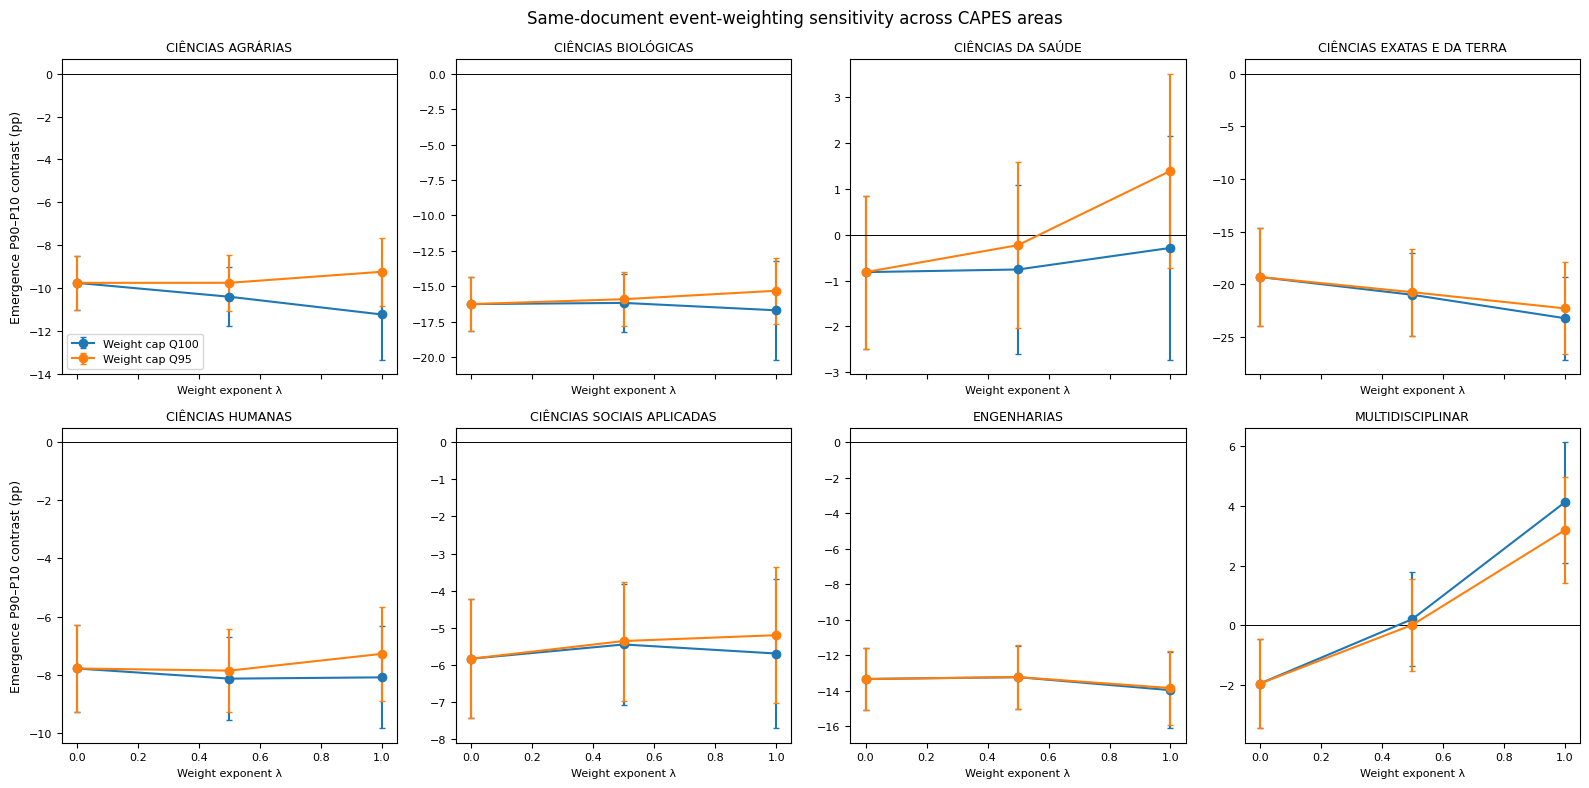

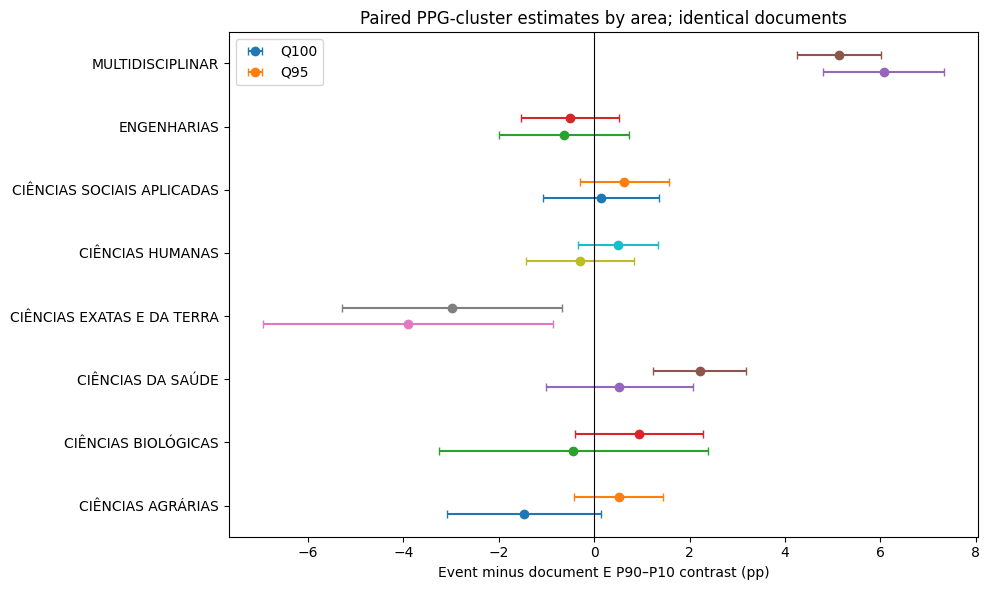

Saved two figures and eight-area comparison table. Figures use the same outcome, counterfactual E values, and risk sets within each area.


,area,cap_quantile,N,N_PPG,estimate_pp,ci95_low_pp,ci95_high_pp,p_value,fdr_bh_q,analysis_type
0,CIÊNCIAS AGRÁRIAS,1.00,39518,449,-1.475081,-3.083813,0.133652,7.230943e-02,1.928252e-01,Paired same-document event vs document weighti...
1,CIÊNCIAS AGRÁRIAS,0.95,39518,449,0.517305,-0.418448,1.453059,2.785727e-01,3.183688e-01,Paired same-document event vs document weighti...
3,CIÊNCIAS BIOLÓGICAS,1.00,25240,327,-0.436880,-3.261181,2.387421,7.617490e-01,8.211536e-01,Paired same-document event vs document weighti...
4,CIÊNCIAS BIOLÓGICAS,0.95,25240,327,0.941730,-0.399647,2.283107,1.688088e-01,2.927009e-01,Paired same-document event vs document weighti...
6,CIÊNCIAS DA SAÚDE,1.00,59189,658,0.529042,-1.017931,2.076015,5.026720e-01,7.962784e-01,Paired same-document event vs document weighti...
7,CIÊNCIAS DA SAÚDE,0.95,59189,658,2.211071,1.235344,3.186799,8.933182e-06,3.573273e-05,Paired same-document event vs document weighti...
9,CIÊNCIAS EXATAS E DA TERRA,1.00,24598,267,-3.906808,-6.951097,-0.862520,1.189262e-02,4.757047e-02,Paired same-document event vs document weighti...
10,CIÊNCIAS EXATAS E DA TERRA,0.95,24598,267,-2.975681,-5.279064,-0.672298,1.133904e-02,3.023744e-02,Paired same-document event vs document weighti...
12,CIÊNCIAS HUMANAS,1.00,61821,651,-0.304749,-1.435120,0.825621,5.972088e-01,7.962784e-01,Paired same-document event vs document weighti...
13,CIÊNCIAS HUMANAS,0.95,61821,651,0.504482,-0.328754,1.337719,2.353537e-01,3.138049e-01,Paired same-document event vs document weighti...


In [59]:
# CELL 55 | Build three publication-focused plots and an evidence table, retaining model labels
import matplotlib.pyplot as plt
assert all(k in globals() for k in ('Q10','Q10_GRID','Q10_JOINT','Q10_AREAS'))
fig,axes=plt.subplots(2,4,figsize=(16,8),sharex=True)
for ax,area in zip(axes.ravel(),Q10_AREAS):
    for cap in (1.,.95):
        s=Q10_GRID.loc[(Q10_GRID.area.eq(area))&(Q10_GRID.cap_quantile.eq(cap))].sort_values('lambda')
        ax.errorbar(s['lambda'].to_numpy(float),s.contrast_pp.to_numpy(float),
                    yerr=[(s.contrast_pp-s.ci95_low_pp).to_numpy(float),
                          (s.ci95_high_pp-s.contrast_pp).to_numpy(float)],
                    marker='o',capsize=2,label=f'Weight cap Q{int(cap*100)}')
    ax.axhline(0,c='black',lw=.7)
    ax.set_title(area,fontsize=9)
    ax.set_xlabel('Weight exponent λ',fontsize=8)
    ax.tick_params(labelsize=8)
axes[0,0].legend(fontsize=8)
for a in axes[:,0]:a.set_ylabel('Emergence P90–P10 contrast (pp)',fontsize=9)
fig.suptitle('Same-document event-weighting sensitivity across CAPES areas')
fig.tight_layout();fig.savefig(Q10/'55_eight_area_weighting_multiverse.png',dpi=200,bbox_inches='tight');plt.show();plt.close(fig)
selected=Q10_JOINT.loc[Q10_JOINT.comparison.eq('Event minus document')].copy()
fig,ax=plt.subplots(figsize=(10,6))
for i,area in enumerate(Q10_AREAS):
    for delta,cap in [(-.13,1.),(.13,.95)]:
        v=selected.loc[(selected.area.eq(area))&(selected.cap_quantile.eq(cap))].iloc[0]
        ax.errorbar(v.estimate_pp,i+delta,
            xerr=[[v.estimate_pp-v.ci95_low_pp],[v.ci95_high_pp-v.estimate_pp]],
            fmt='o',capsize=3,label=f'Q{int(cap*100)}' if i==0 else None)
ax.axvline(0,color='black',lw=.8)
ax.set_yticks(range(len(Q10_AREAS)),Q10_AREAS)
ax.set_xlabel('Event minus document E P90–P10 contrast (pp)')
ax.set_title('Paired PPG-cluster estimates by area; identical documents')
ax.legend();fig.tight_layout();fig.savefig(Q10/'55_paired_estimand_gaps_by_area.png',dpi=200,bbox_inches='tight');plt.show();plt.close(fig)
Q10_MANUSCRIPT=selected[['area','cap_quantile','N','N_PPG','estimate_pp','ci95_low_pp','ci95_high_pp','p_value','fdr_bh_q']].copy()
Q10_MANUSCRIPT['analysis_type']='Paired same-document event vs document weighting; association, not causal effect'
Q10_MANUSCRIPT.to_csv(Q10/'55_manuscript_eight_area_table.csv',index=False)
print('Saved two figures and eight-area comparison table. Figures use the same outcome, counterfactual E values, and risk sets within each area.')
display(Q10_MANUSCRIPT)

# Frozen V10 audit and journal-level interpretation boundary

In [60]:
# CELL 56 | Freeze all new files and verify expected computation products
import json,hashlib
from datetime import datetime,timezone
assert all(k in globals() for k in ('Q10','Q10_GRID','Q10_JOINT','Q10_MANUSCRIPT'))
required=['53_eight_area_weight_grid.csv','54_eight_area_paired_cluster_tests.csv',
          '55_eight_area_weighting_multiverse.png','55_paired_estimand_gaps_by_area.png',
          '55_manuscript_eight_area_table.csv']
assert all((Q10/f).is_file() for f in required)
assert Q10_GRID.shape[0]==48 and Q10_JOINT.shape[0]==24
files=[]
for p in sorted(Q10.iterdir()):
    if p.is_file():
        files.append({'file':p.name,'sha256':hashlib.sha256(p.read_bytes()).hexdigest(),'bytes':p.stat().st_size})
notes={
 'journal':'Quality & Quantity — International Journal of Methodology',
 'experiment':'V10 — full eight-area same-risk-set event-weighting sensitivity',
 'timestamp_utc':datetime.now(timezone.utc).isoformat(),
 'source':'Frozen CAPES ETS MAIN44 archive, 2016–2021, translation-eligible sample',
 'models':48,'paired_cluster_tests':24,'broad_areas_observed':8,
 'estimand':'Mean adjusted E percentile P90–P10 predicted contrast, standardized over each area’s observed R and year',
 'methods':'PPG-clustered weighted binomial quasi-likelihood; lambda in {0,0.5,1}; caps at Q95 and Q100',
 'fdr':'Within each of 3 predefined families of 8 area tests',
 'interpretation_limits':[
  'A continuum of weights constitutes specification sensitivity; intermediate weights are not literal event trials.',
  'Estimated relationships are associational; no causal claim or independent criterion validity is established.',
  'Historical archived E_C/R_C model preprocessing is not assumed identical to this explicit E/R centering.',
  'Predictions are standardized using within-area document covariate distributions.',
  'Cross-area estimates need not be directly comparable if the area-year percentile support differs.',
  'No ninth CAPES area is fabricated when only eight categories are present in this eligible sample.'
 ],'files':files}
(Q10/'56_integrity_manifest.json').write_text(json.dumps(notes,indent=2,ensure_ascii=False),encoding='utf-8')
print('V10 COMPLETED:',len(files)+1,'files in',Q10)
print('NEW analyses:',len(Q10_GRID),'full fits and',len(Q10_JOINT),'paired PPG-cluster comparisons')
print('Ready for journal-focused synthesis, not proof of causal or epistemic criterion validity.')

V10 COMPLETED: 6 files in /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026/QQ_EIGHT_AREA_WEIGHTING_V10
NEW analyses: 48 full fits and 24 paired PPG-cluster comparisons
Ready for journal-focused synthesis, not proof of causal or epistemic criterion validity.


# Six-dimension construct and estimand ledger

In [63]:
# CELL 57 (REVISED) | Six ETS constructs: archive coverage versus model risk sets
from pathlib import Path
import pandas as pd, numpy as np
assert all(name in globals() for name in ('OUT','frame','merge','counts','robust')), \
    'Run the previous laboratory cells before Cell 57.'
Q11 = Path(OUT) / 'QQ_MANUSCRIPT_EVIDENCE_V11'
Q11.mkdir(parents=True, exist_ok=True)

# IMPORTANT: persistence has TWO distinct definitions and nonmissing populations.
# Pairwise temporal diversity: N=302,956. Conditional t+3 given t+1: N=290,520.
# D similarly has N=459,177 for the descriptive archived index and N=427,649
# for the exposure-conditional grouped-binomial model.
registry = [
 dict(symbol='E', construct='Emergence', archived_variable='E_PCT_AREA_ANO',
      primary_model_variable='E_PCT_AREA_ANO', archived_valid_n=459177,
      primary_model_eligible_n=459177, definition='Area-year percentile of semantic distance from the preceding three-year frontier',
      model_eligibility='All frozen MAIN44 focal documents'),
 dict(symbol='R', construct='Recombination', archived_variable='R_PCT_AREA_ANO',
      primary_model_variable='R_PCT_AREA_ANO', archived_valid_n=459177,
      primary_model_eligible_n=459177, definition='Area-year percentile of disciplinary entropy among top-10 semantic antecedents',
      model_eligibility='All frozen MAIN44 focal documents'),
 dict(symbol='D', construct='Diffusion', archived_variable='D_PCT_AREA_ANO',
      primary_model_variable='D10_GIVEN_H50_RATE', archived_valid_n=459177,
      primary_model_eligible_n=427649, definition='Conditional future top-10 uptake relative to positive future top-50 exposure',
      model_eligibility='H50 > 0 in the future three-year exposure window'),
 dict(symbol='P', construct='Persistence', archived_variable='P_TEMPORAL_DIVERSITY_PAIRWISE',
      primary_model_variable='P_T3_GIVEN_T1', archived_valid_n=302956,
      primary_model_eligible_n=290520, definition='Future t+3 uptake conditional on observed uptake at t+1',
      model_eligibility='Positive t+1 uptake and observed t+3 outcome; pairwise temporal diversity uses a broader risk set'),
 dict(symbol='T', construct='Translation', archived_variable='T_CROSS_GRANDE_SHARE',
      primary_model_variable='T_CROSS_GRANDE_SHARE', archived_valid_n=363690,
      primary_model_eligible_n=363690, definition='Document-level fraction of future top-10 uptake crossing broad CAPES areas',
      model_eligibility='At least one eligible future top-10 uptake event'),
 dict(symbol='I', construct='Institutionalization', archived_variable='I_PROGRAM_DIVERSITY_PAIRWISE',
      primary_model_variable='I_PROGRAM_DIVERSITY_PAIRWISE', archived_valid_n=302956,
      primary_model_eligible_n=302956, definition='Pairwise diversity of postgraduate programs across future uptake events',
      model_eligibility='At least two eligible future uptake events'),
]

ledger=[]
for r in registry:
    r=r.copy()
    av,pv=r['archived_variable'],r['primary_model_variable']
    assert av in frame.columns, f'Archived variable not found: {av}'
    primary_source=merge if r['symbol']=='D' else frame
    assert pv in primary_source.columns, f'Primary variable {pv} not found in expected source (merge for D; frame otherwise)'
    archived_observed=int(frame[av].notna().sum())
    primary_observed=int(primary_source[pv].notna().sum())
    r['observed_frozen_archived_nonmissing_n']=archived_observed
    r['observed_frozen_primary_nonmissing_n']=primary_observed
    r['archived_coverage_matches']=archived_observed==r['archived_valid_n']
    r['model_variable_coverage_matches']=primary_observed==r['primary_model_eligible_n']
    r['coverage_difference_archived_minus_model']=r['archived_valid_n']-r['primary_model_eligible_n']
    r['validity_scope']='Operational proxy; external criterion validity not established'
    ledger.append(r)
ledger=pd.DataFrame(ledger)
assert len(ledger)==6
bad_archive=ledger.loc[~ledger.archived_coverage_matches]
if len(bad_archive):
    print('ARCHIVED coverage discrepancies (investigate before interpreting):')
    display(bad_archive[['symbol','archived_variable','archived_valid_n','observed_frozen_archived_nonmissing_n']])
    raise AssertionError('An archived construct-coverage count did not match the actual archived variable.')
bad_model=ledger.loc[~ledger.model_variable_coverage_matches]
if len(bad_model):
    print('MODEL variable coverage discrepancies (eligibility may require an additional mask):')
    display(bad_model[['symbol','primary_model_variable','primary_model_eligible_n','observed_frozen_primary_nonmissing_n']])
    raise AssertionError('Primary model variable coverage differs from its documented risk set.')
ledger.to_csv(Q11/'57_six_dimension_estimand_ledger.csv',index=False)
print('PASS: all six constructs audited using definition-specific variables and risk sets.')
display(ledger[['symbol','construct','archived_variable','archived_valid_n',
                'primary_model_variable','primary_model_eligible_n',
                'coverage_difference_archived_minus_model']])
print('Persistence: 302,956 pairwise-diversity records versus 290,520 t+3|t+1 records.')
print('Diffusion: 459,177 archived descriptive records versus 427,649 conditional-model records.')
print('This ledger does not claim external validity or identical estimation samples.')


PASS: all six constructs audited using definition-specific variables and risk sets.


,symbol,construct,archived_variable,archived_valid_n,primary_model_variable,primary_model_eligible_n,coverage_difference_archived_minus_model
0,E,Emergence,E_PCT_AREA_ANO,459177,E_PCT_AREA_ANO,459177,0
1,R,Recombination,R_PCT_AREA_ANO,459177,R_PCT_AREA_ANO,459177,0
2,D,Diffusion,D_PCT_AREA_ANO,459177,D10_GIVEN_H50_RATE,427649,31528
3,P,Persistence,P_TEMPORAL_DIVERSITY_PAIRWISE,302956,P_T3_GIVEN_T1,290520,12436
4,T,Translation,T_CROSS_GRANDE_SHARE,363690,T_CROSS_GRANDE_SHARE,363690,0
5,I,Institutionalization,I_PROGRAM_DIVERSITY_PAIRWISE,302956,I_PROGRAM_DIVERSITY_PAIRWISE,302956,0


Persistence: 302,956 pairwise-diversity records versus 290,520 t+3|t+1 records.
Diffusion: 459,177 archived descriptive records versus 427,649 conditional-model records.
This ledger does not claim external validity or identical estimation samples.


# Distribution-aware model evidence across D, P, T, and I

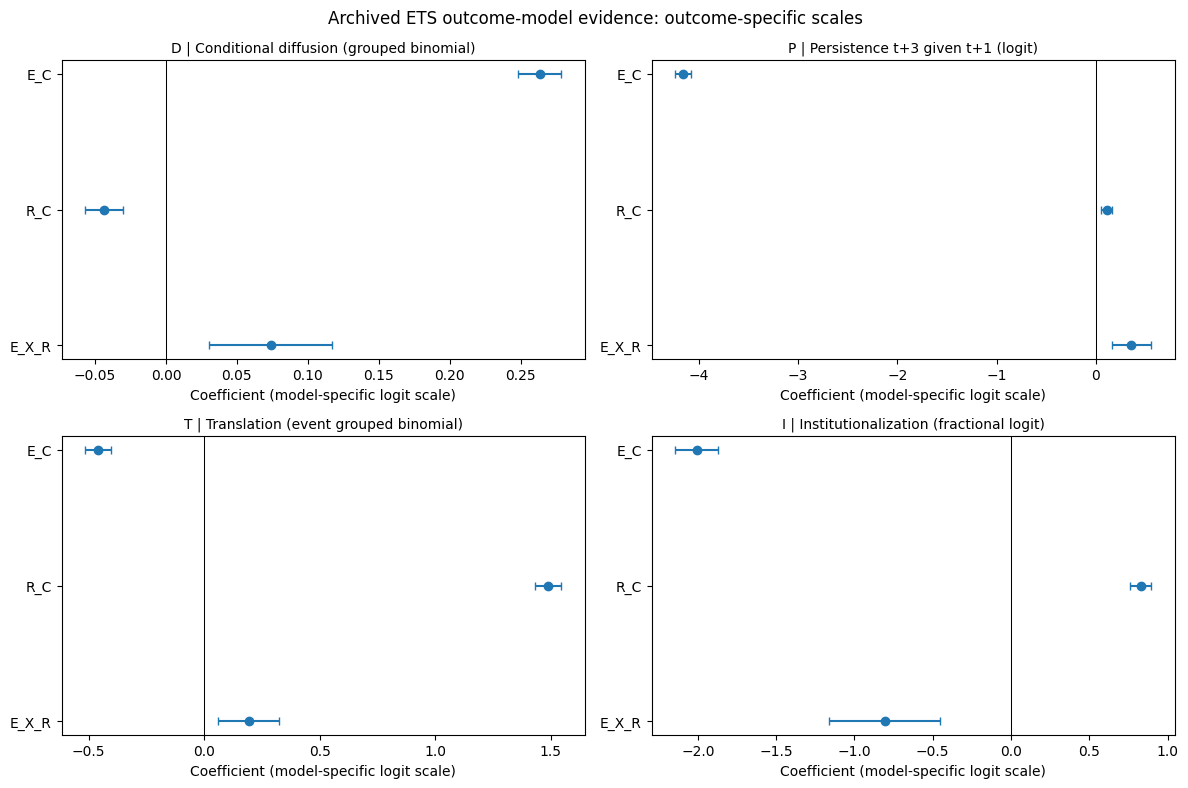

ARCHIVED model rows: 12 | NEW same-row paired weighting results: 16


,construct_family,VARIABLE,BETA,SE_CLUSTER,CI95_LOW,CI95_HIGH,P_VALUE,N
0,D | Conditional diffusion (grouped binomial),E_C,0.26353,0.00769,0.24846,0.27859,0.00000,427649
1,D | Conditional diffusion (grouped binomial),R_C,-0.04370,0.00669,-0.05681,-0.03060,0.00000,427649
2,D | Conditional diffusion (grouped binomial),E_X_R,0.07370,0.02214,0.03031,0.11709,0.00087,427649
3,P | Persistence t+3 given t+1 (logit),E_C,-4.16057,0.03983,-4.23865,-4.08250,0.00000,290520
4,P | Persistence t+3 given t+1 (logit),R_C,0.10900,0.02638,0.05729,0.16071,0.00004,290520
5,P | Persistence t+3 given t+1 (logit),E_X_R,0.35970,0.10089,0.16197,0.55743,0.00036,290520
6,T | Translation (event grouped binomial),E_C,-0.45887,0.02811,-0.51397,-0.40377,0.00000,363690
7,T | Translation (event grouped binomial),R_C,1.49007,0.02853,1.43414,1.54599,0.00000,363690
8,T | Translation (event grouped binomial),E_X_R,0.19315,0.06724,0.06135,0.32494,0.00407,363690
9,I | Institutionalization (fractional logit),E_C,-2.00685,0.07006,-2.14416,-1.86954,0.00000,302956


In [64]:
# CELL 58 | Model evidence ledger, confidence-interval checks, and figure panels
import matplotlib.pyplot as plt
assert all(v in globals() for v in ['Q11','robust','process','Q10_JOINT'])
family_label={'D_GROUPED_BINOMIAL':'D | Conditional diffusion (grouped binomial)',
 'P_LOGIT_T3_GIVEN_T1':'P | Persistence t+3 given t+1 (logit)',
 'T_GROUPED_BINOMIAL':'T | Translation (event grouped binomial)',
 'I_FRACTIONAL_LOGIT':'I | Institutionalization (fractional logit)'}
fam=robust.loc[robust.MODEL.isin(family_label)].copy()
required={'MODEL','VARIABLE','BETA','SE_CLUSTER','CI95_LOW','CI95_HIGH','P_VALUE','N'}
assert required.issubset(fam.columns) and len(fam)==12
assert set(fam.MODEL)==set(family_label)
for col in ['BETA','SE_CLUSTER','CI95_LOW','CI95_HIGH','P_VALUE']:
    fam[col]=pd.to_numeric(fam[col],errors='raise')
assert (fam.CI95_LOW<=fam.BETA).all() and (fam.BETA<=fam.CI95_HIGH).all()
assert fam.groupby('MODEL').VARIABLE.nunique().eq(3).all()
fam['construct_family']=fam.MODEL.map(family_label)
fam['link_scale']='logit; exp(beta) is conditional odds multiplier, NOT average marginal effect'
fam['evidence_status']='ARCHIVED original model estimates; not refitted by Cell 58'
fam.to_csv(Q11/'58_archived_conditional_model_families.csv',index=False)
fig,axs=plt.subplots(2,2,figsize=(12,8))
term_order=['E_C','R_C','E_X_R']
for ax,(model,sub) in zip(axs.flat,fam.groupby('MODEL',sort=False)):
    s=sub.set_index('VARIABLE').loc[term_order].reset_index()
    x=s.BETA.to_numpy(float);lo=s.CI95_LOW.to_numpy(float);hi=s.CI95_HIGH.to_numpy(float)
    ax.errorbar(x,range(3),xerr=[x-lo,hi-x],fmt='o',capsize=3)
    ax.set_yticks(range(3),term_order);ax.invert_yaxis();ax.axvline(0,c='black',lw=.75)
    ax.set_title(family_label[model],fontsize=10);ax.set_xlabel('Coefficient (model-specific logit scale)')
fig.suptitle('Archived ETS outcome-model evidence: outcome-specific scales',fontsize=12)
fig.tight_layout();fig.savefig(Q11/'58_ets_four_outcome_families.png',dpi=200,bbox_inches='tight');plt.show();plt.close(fig)
# The newly reweighted translation evidence belongs in a separate, probability-scale table.
trans=Q10_JOINT.loc[Q10_JOINT.comparison.eq('Event minus document')].copy()
cols=['area','cap_quantile','estimate_pp','se_pp','ci95_low_pp','ci95_high_pp','p_value','fdr_bh_q']
assert set(cols).issubset(trans.columns) and len(trans)==16
trans[cols].to_csv(Q11/'58_new_translation_reweighting_evidence.csv',index=False)
print('ARCHIVED model rows:',len(fam),'| NEW same-row paired weighting results:',len(trans))
display(fam[['construct_family','VARIABLE','BETA','SE_CLUSTER','CI95_LOW','CI95_HIGH','P_VALUE','N']].round(5))

# Six-dimensional structure, dependency diagnostics, and sample balance

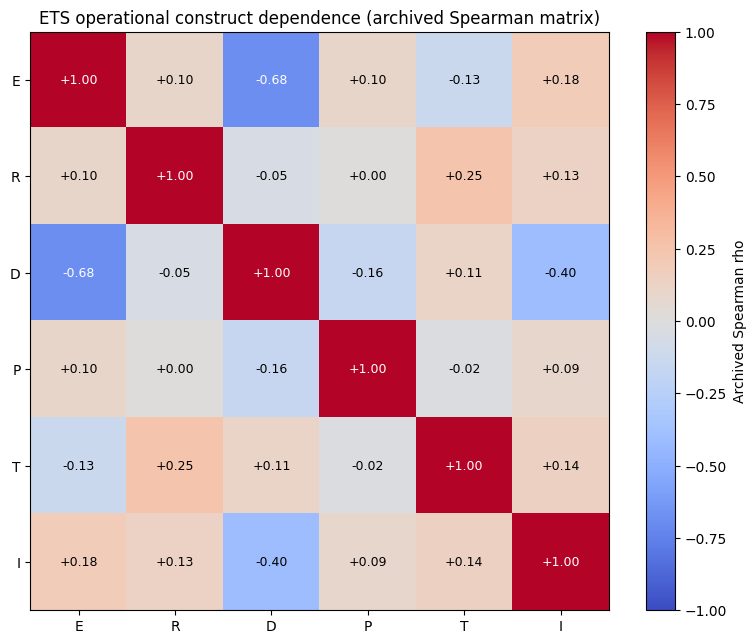

Archived matrix: pairwise summary, different eligibility rules may apply across dimensions.


,ER_QUADRANT_FINAL,N,sample_percent
0,HIGH_E_HIGH_R,6705,1.460221
1,HIGH_E_ONLY,39355,8.570769
2,HIGH_R_ONLY,39211,8.539409
3,NEITHER,373906,81.429601


Original dependence diagnostic records: 7


,MEDIDA,SPEARMAN_COM_D
0,P antigo: cobertura temporal,0.869596
1,P antigo: entropia temporal,0.729600
2,P final: diversidade temporal pairwise,-0.156504
3,P final: continuidade após t+1,0.460289
4,I antigo: número de PPGs,0.955295
5,I antigo: PPGs/hit,-0.612409
6,I final: diversidade institucional pairwise,-0.400852


In [65]:
# CELL 59 | Archived six-dimension correlation structure, quadrant distribution and diagnostics
import matplotlib.pyplot as plt
assert all(v in globals() for v in ['Q11','read_csv','paths'])
cor=read_csv('dimension_correlations')
names=['E_EMERGENCE','R_RECOMBINATION','D_DIFFUSION','P_PERSISTENCE','T_TRANSLATION','I_INSTITUTIONALIZATION']
label_col=cor.columns[0]
cor=cor.set_index(label_col)
assert set(names).issubset(cor.index) and set(names).issubset(cor.columns)
mat=cor.loc[names,names].apply(pd.to_numeric,errors='raise').to_numpy(float)
assert np.isfinite(mat).all() and np.allclose(mat,mat.T,atol=1e-8)
assert np.allclose(np.diag(mat),1,atol=1e-8)
pd.DataFrame(mat,index=names,columns=names).to_csv(Q11/'59_archived_six_dimensional_correlation_matrix.csv')
fig,ax=plt.subplots(figsize=(8,6.5))
im=ax.imshow(mat,vmin=-1,vmax=1,cmap='coolwarm')
short=['E','R','D','P','T','I']
ax.set_xticks(range(6),short);ax.set_yticks(range(6),short)
for i in range(6):
 for j in range(6):
  ax.text(j,i,f'{mat[i,j]:+.2f}',ha='center',va='center',fontsize=9,
          color='white' if abs(mat[i,j])>.55 else 'black')
fig.colorbar(im,ax=ax,label='Archived Spearman rho')
ax.set_title('ETS operational construct dependence (archived Spearman matrix)')
fig.tight_layout();fig.savefig(Q11/'59_six_dimension_spearman_heatmap.png',dpi=220);plt.show();plt.close(fig)
quad=read_csv('er_quadrants')
assert {'ER_QUADRANT_FINAL','N'}.issubset(quad.columns) and int(quad.N.sum())==459177
quad=quad[['ER_QUADRANT_FINAL','N']].copy();quad['sample_percent']=100*quad.N/quad.N.sum()
quad.to_csv(Q11/'59_er_quadrant_balance.csv',index=False)
dep=read_csv('dependency_dpi')
dep.to_csv(Q11/'59_archived_dependency_diagnostics.csv',index=False)
print('Archived matrix: pairwise summary, different eligibility rules may apply across dimensions.')
display(quad)
print('Original dependence diagnostic records:',len(dep))
display(dep)

# Manuscript-ready evidence tables and synthesis freeze

In [66]:
# CELL 60 | Journal-ready tables, manuscript text, and verified provenance manifest
import hashlib, json
from datetime import datetime, timezone
assert all(v in globals() for v in ['Q11','ledger','fam','trans','quad','Q10_JOINT'])
# Single-table evidence index, with provenance and scale labels.
idx=pd.DataFrame([
 {'table':'Table 1','file':'57_six_dimension_estimand_ledger.csv','subject':'Construct definitions, coverage and model eligibility','status':'ARCHIVED definitions and verified risk sets'},
 {'table':'Table 2','file':'58_archived_conditional_model_families.csv','subject':'D, P, T and I outcome-specific models','status':'ARCHIVED fitted estimates'},
 {'table':'Table 3','file':'58_new_translation_reweighting_evidence.csv','subject':'Within-area translation weighting sensitivity','status':'NEW refitted same-risk-set clustered estimates'},
 {'table':'Supplementary Table S1','file':'59_archived_six_dimensional_correlation_matrix.csv','subject':'Six-dimensional dependence matrix','status':'ARCHIVED descriptive correlations'},
 {'table':'Supplementary Table S2','file':'59_er_quadrant_balance.csv','subject':'E–R quadrant distribution','status':'ARCHIVED descriptive tabulation'}])
idx.to_csv(Q11/'60_manuscript_table_index.csv',index=False)
primary=trans.loc[trans.cap_quantile.eq(1.)].set_index('area')
capped=trans.loc[trans.cap_quantile.eq(.95)].set_index('area')
assert len(primary)==8 and len(capped)==8
multi=primary.loc['MULTIDISCIPLINAR']; multi95=capped.loc['MULTIDISCIPLINAR']
exact=primary.loc['CIÊNCIAS EXATAS E DA TERRA']
health95=capped.loc['CIÊNCIAS DA SAÚDE']
text_lines=[
 '## Results — archived ETS model evidence and new robustness extensions',
 '',
 'The archived ETS analytical population contains 459,177 focal postgraduate documents. Emergence and recombination are available across the frozen MAIN44 analytical sample, while prospective outcomes have different eligibility conditions. Conditional diffusion uses 427,649 exposure-eligible documents; persistence t+3 given uptake at t+1 uses 290,520; translation uses 363,690 documents with future uptake; and pairwise institutional diversity uses 302,956.',
 '',
 'The original distribution-aware models for conditional diffusion, persistence, translation and institutionalization are reported separately because their estimands and link scales are not interchangeable. Archived correlations and E–R quadrants characterize dependence among operational measures rather than independent criterion validity.',
 '',
 f'In the new eight-area, same-document reweighting experiment, the event-weighted minus document-weighted difference in the emergence P90–P10 translation contrast was {multi.estimate_pp:+.2f} percentage points in Multidisciplinary (95% CI {multi.ci95_low_pp:+.2f} to {multi.ci95_high_pp:+.2f}) and {exact.estimate_pp:+.2f} points in Exact and Earth Sciences (95% CI {exact.ci95_low_pp:+.2f} to {exact.ci95_high_pp:+.2f}).',
 f'With event weights capped at the within-area 95th percentile while retaining the same documents, the corresponding difference was {multi95.estimate_pp:+.2f} points in Multidisciplinary (95% CI {multi95.ci95_low_pp:+.2f} to {multi95.ci95_high_pp:+.2f}), and {health95.estimate_pp:+.2f} points in Health Sciences (95% CI {health95.ci95_low_pp:+.2f} to {health95.ci95_high_pp:+.2f}).',
 '',
 'These results show specification-dependent associations and disciplinary heterogeneity. They do not establish causal influence, recovery of epistemically relevant antecedents, or external criterion validity. These paragraphs are a checked numerical starting point for manuscript revision, not a complete Results section.',
 '']
(Q11/'60_results_synthesis_draft_EN.md').write_text('\n'.join(text_lines),encoding='utf-8')
# Evidence preservation: file hashes include the integrated files and exclude the manifest itself.
files=[]
for path in sorted(Q11.iterdir()):
 if path.is_file() and path.name!='60_freeze_manifest.json':
  files.append({'name':path.name,'bytes':path.stat().st_size,
                'sha256':hashlib.sha256(path.read_bytes()).hexdigest()})
manifest={'journal':'Quality & Quantity — International Journal of Methodology',
 'paper':'Beyond disruption scores: Epistemic Transition Signatures in Brazil’s postgraduate research system, 2013–2024',
 'timestamp_utc':datetime.now(timezone.utc).isoformat(),
 'methodological_status':'Archive-to-manuscript synthesis; no model refitting in Cells 57–60',
 'sample_main44':459177,'translation_eligible_n':363690,'translation_eligible_areas':8,
 'source_experiments':'Original ETS archived stages plus QQ_EIGHT_AREA_WEIGHTING_V10',
 'caveats':['Eight CAPES broad areas observed in translation-eligible sample; no ninth group imputed.',
 'Risk sets differ by outcome; no pooling of regression link-scale coefficients.',
 'No expert criterion-validation or causal inference is claimed.',
 'Archived original E_C/R_C coding is not assumed equivalent to new centered percentile predictors.'],
 'files':files}
(Q11/'60_freeze_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
assert all((Q11/f).is_file() for f in idx.file)
print('COMPLETE — integrated ETS manuscript evidence:',Q11)
print('Evidence artifacts:',len(files)+1,'| all six constructs:',','.join(ledger.symbol))
display(idx)
print('\n'.join(text_lines[:12]))

COMPLETE — integrated ETS manuscript evidence: /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026/QQ_MANUSCRIPT_EVIDENCE_V11
Evidence artifacts: 11 | all six constructs: E,R,D,P,T,I


,table,file,subject,status
0,Table 1,57_six_dimension_estimand_ledger.csv,"Construct definitions, coverage and model elig...",ARCHIVED definitions and verified risk sets
1,Table 2,58_archived_conditional_model_families.csv,"D, P, T and I outcome-specific models",ARCHIVED fitted estimates
2,Table 3,58_new_translation_reweighting_evidence.csv,Within-area translation weighting sensitivity,NEW refitted same-risk-set clustered estimates
3,Supplementary Table S1,59_archived_six_dimensional_correlation_matrix...,Six-dimensional dependence matrix,ARCHIVED descriptive correlations
4,Supplementary Table S2,59_er_quadrant_balance.csv,E–R quadrant distribution,ARCHIVED descriptive tabulation


## Results — archived ETS model evidence and new robustness extensions

The archived ETS analytical population contains 459,177 focal postgraduate documents. Emergence and recombination are available across the frozen MAIN44 analytical sample, while prospective outcomes have different eligibility conditions. Conditional diffusion uses 427,649 exposure-eligible documents; persistence t+3 given uptake at t+1 uses 290,520; translation uses 363,690 documents with future uptake; and pairwise institutional diversity uses 302,956.

The original distribution-aware models for conditional diffusion, persistence, translation and institutionalization are reported separately because their estimands and link scales are not interchangeable. Archived correlations and E–R quadrants characterize dependence among operational measures rather than independent criterion validity.

In the new eight-area, same-document reweighting experiment, the event-weighted minus document-weighted difference in the emerge

# Direct six-construct dependence re-estimation and pairwise denominators

PASS: direct operational matrix recomputed from 459,177 focals
Operational measure coverage:


,dimension,nonmissing_n,source_variable
0,E,459177,E_PCT_AREA_ANO
1,R,459177,R_PCT_AREA_ANO
2,D,459177,D_PCT_AREA_ANO
3,P,302956,P_TEMPORAL_DIVERSITY_PAIRWISE
4,T,363690,T_CROSS_GRANDE_SHARE
5,I,302956,I_PROGRAM_DIVERSITY_PAIRWISE


Spearman rho:


,E,R,D,P,T,I
E,1.0000,0.0961,-0.6841,0.0945,-0.1170,0.1648
R,0.0961,1.0000,-0.0520,0.0044,0.2418,0.1353
D,-0.6841,-0.0520,1.0000,-0.1524,0.0995,-0.3812
P,0.0945,0.0044,-0.1524,1.0000,-0.0179,0.0849
T,-0.1170,0.2418,0.0995,-0.0179,1.0000,0.1827
I,0.1648,0.1353,-0.3812,0.0849,0.1827,1.0000


Pairwise N (NOT necessarily model estimation N):


,E,R,D,P,T,I
E,459177,459177,459177,302956,363690,302956
R,459177,459177,459177,302956,363690,302956
D,459177,459177,459177,302956,363690,302956
P,302956,302956,302956,302956,302956,302956
T,363690,363690,363690,302956,363690,302956
I,302956,302956,302956,302956,302956,302956


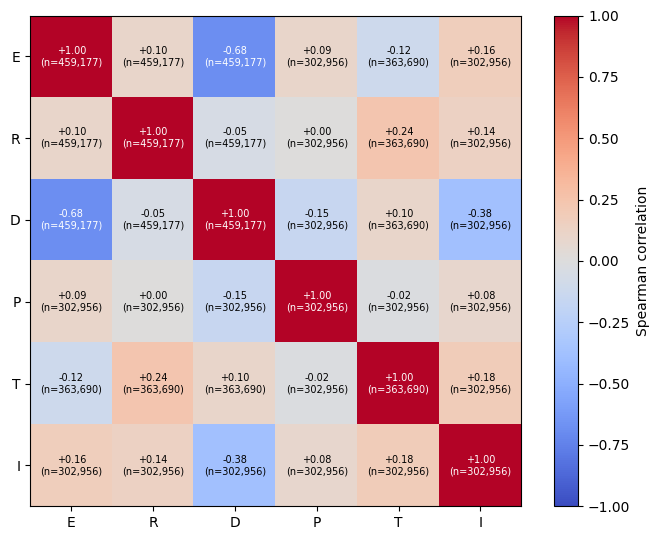

In [67]:
# CELL 61 | Recompute ETS operational dependence from frozen MAIN44 microdata
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
assert all(k in globals() for k in ('frame','OUT')), 'Run the source notebook first.'
V12 = Path(OUT) / 'QQ_CONSTRUCT_DEPENDENCE_V12'
V12.mkdir(parents=True, exist_ok=True)

# Explicit descriptive operationalizations; NOT an interchangeable substitute for model-specific outcomes.
ETS_MEASURES = {
    'E': 'E_PCT_AREA_ANO',
    'R': 'R_PCT_AREA_ANO',
    'D': 'D_PCT_AREA_ANO',
    'P': 'P_TEMPORAL_DIVERSITY_PAIRWISE',
    'T': 'T_CROSS_GRANDE_SHARE',
    'I': 'I_PROGRAM_DIVERSITY_PAIRWISE',
}
missing=[k for k in ETS_MEASURES.values() if k not in frame.columns]
assert not missing, f'Missing explicit source columns: {missing}'
X=frame[list(ETS_MEASURES.values())].apply(pd.to_numeric,errors='coerce').rename(
    columns={val:key for key,val in ETS_MEASURES.items()})
assert len(X)==459177, f'Unexpected MAIN44 universe: {len(X)}'
coverage=X.notna().sum().rename('nonmissing_n').reset_index().rename(columns={'index':'dimension'})
coverage['source_variable']=coverage['dimension'].map(ETS_MEASURES)
cor=X.corr(method='spearman',min_periods=50).loc[list(ETS_MEASURES),list(ETS_MEASURES)]
N=pd.DataFrame(index=cor.index,columns=cor.columns,dtype=int)
for i in cor.index:
    for j in cor.columns:
        N.loc[i,j]=int(X[[i,j]].notna().all(axis=1).sum()) if i!=j else int(X[i].notna().sum())
assert np.allclose(cor.values,cor.values.T,equal_nan=True)
assert np.array_equal(N.values,N.values.T)
assert int(coverage.set_index('dimension').loc['P','nonmissing_n'])==302956
assert int(coverage.set_index('dimension').loc['D','nonmissing_n'])==459177
coverage.to_csv(V12/'61_construct_coverage.csv',index=False)
cor.to_csv(V12/'61_empirical_spearman_rho.csv')
N.astype(int).to_csv(V12/'61_pairwise_complete_case_n.csv')
print('PASS: direct operational matrix recomputed from',format(len(X),','),'focals')
print('Operational measure coverage:');display(coverage)
print('Spearman rho:');display(cor.round(4))
print('Pairwise N (NOT necessarily model estimation N):');display(N.astype(int))
fig,ax=plt.subplots(figsize=(7,5.5));image=ax.imshow(cor.to_numpy(),vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(6),list(cor.columns));ax.set_yticks(range(6),list(cor.index))
for i in range(6):
    for j in range(6):
        ax.text(j,i,f'{cor.iloc[i,j]:+.2f}\n(n={int(N.iloc[i,j]):,})',ha='center',va='center',fontsize=7,
                color='white' if abs(cor.iloc[i,j])>.55 else 'black')
fig.colorbar(image,ax=ax,label='Spearman correlation');fig.tight_layout()
fig.savefig(V12/'61_ETS_construct_dependence_pairwise_n.png',dpi=220);plt.show()


# Audit archived correlations against reconstructed operational measures

In [68]:
# CELL 62 | Reconcile archive and reconstructed correlations, without forcing agreement
assert all(k in globals() for k in ('cor','N','V12','read_csv')), 'Execute cell 61 and earlier laboratory cells.'
arch=read_csv('dimension_correlations').copy()
arch=arch.loc[:,~arch.columns.astype(str).str.startswith('Unnamed')]
lookup={'E':'E_EMERGENCE','R':'R_RECOMBINATION','D':'D_DIFFUSION',
        'P':'P_PERSISTENCE','T':'T_TRANSLATION','I':'I_INSTITUTIONALIZATION'}
# Archive may carry a first-column row-label, or may already have named index.
label_cols=[col for col in arch.columns if col not in lookup.values()]
if label_cols:
    lab=label_cols[0]
    arch=arch.set_index(lab)
else:
    assert len(arch)==6, 'Unrecognized archived correlation layout.'
    arch.index=list(lookup.values())
expected=list(lookup.values())
assert set(expected).issubset(arch.index) and set(expected).issubset(arch.columns), \
       'Archived matrix labels differ; inspect before comparing.'
rows=[]
for a in lookup:
    for b in lookup:
        if list(lookup).index(a)>=list(lookup).index(b): continue
        frozen=float(arch.loc[lookup[a],lookup[b]])
        direct=float(cor.loc[a,b]);diff=direct-frozen
        rows.append({'pair':f'{a}-{b}','archived_rho':frozen,'direct_rho':direct,
                     'difference':diff,'absolute_difference':abs(diff),
                     'pairwise_n':int(N.loc[a,b]),
                     'within_0_001':abs(diff)<0.001})
reconciliation=pd.DataFrame(rows)
reconciliation.to_csv(V12/'62_archive_vs_direct_correlation_reconciliation.csv',index=False)
print('Archive reconciliation (differences are documented, NOT silently corrected):')
display(reconciliation.sort_values('absolute_difference',ascending=False))
print('Max absolute rho difference:',reconciliation.absolute_difference.max())
print('Pairs differing >=0.001:',int((~reconciliation.within_0_001).sum()))
print('Note: E/R/D/P/T/I labels may represent different outcome variants in archived analyses.')


Archive reconciliation (differences are documented, NOT silently corrected):


,pair,archived_rho,direct_rho,difference,absolute_difference,pairwise_n,within_0_001
14,T-I,0.139777,0.182706,4.292828e-02,4.292828e-02,302956,False
11,D-I,-0.400852,-0.381202,1.965024e-02,1.965024e-02,302956,False
4,E-I,0.181739,0.164845,-1.689382e-02,1.689382e-02,302956,False
10,D-T,0.113728,0.099515,-1.421297e-02,1.421297e-02,363690,False
3,E-T,-0.127280,-0.116997,1.028366e-02,1.028366e-02,363690,False
8,R-I,0.129274,0.135272,5.997925e-03,5.997925e-03,302956,False
7,R-T,0.247772,0.241795,-5.977453e-03,5.977453e-03,363690,False
9,D-P,-0.156504,-0.152411,4.093561e-03,4.093561e-03,302956,False
2,E-P,0.097020,0.094501,-2.518790e-03,2.518790e-03,302956,False
13,P-I,0.086822,0.084946,-1.876316e-03,1.876316e-03,302956,False


Max absolute rho difference: 0.0429282836648649
Pairs differing >=0.001: 10
Note: E/R/D/P/T/I labels may represent different outcome variants in archived analyses.


# Publication-facing six-construct matrix and inference boundaries

In [69]:
# CELL 63 | Publishable empirical ledger and claim boundaries
import json
from datetime import datetime, timezone
assert all(k in globals() for k in ('V12','coverage','reconciliation','Q11','ledger')), 'Execute cells 57–62 first.'
risk=ledger[['symbol','construct','archived_variable','archived_valid_n',
             'primary_model_variable','primary_model_eligible_n']].copy()
risk.to_csv(V12/'63_table_1_operational_constructs_and_risk_sets.csv',index=False)
# Strongest two original construct-dependence associations, derived from the recomputation.
pairs=reconciliation.copy().sort_values('absolute_difference',ascending=False)
claim_matrix=pd.DataFrame([
 {'claim':'Six constructs are operationally distinct, not externally validated',
  'evidence':'Explicit six-variable MAIN44 matrix and pairwise N',
  'interpretation':'Descriptive dependence; no ground-truth validation'},
 {'claim':'D differs between descriptive coverage and conditional diffusion modeling',
  'evidence':'Archived D coverage 459177; grouped-binomial risk set 427649',
  'interpretation':'Condition on positive future semantic exposure'},
 {'claim':'P variants have different eligible populations',
  'evidence':'Pairwise temporal diversity 302956; t+3 given t+1 290520',
  'interpretation':'Do not interpret these as identical Persistence estimands'},
 {'claim':'Translation weighting is area-sensitive',
  'evidence':'V10 same-document paired clustered comparisons across eight observed areas',
  'interpretation':'Associational sensitivity, not causal or criterion validity'},
])
claim_matrix.to_csv(V12/'63_manuscript_claims_and_limits.csv',index=False)
text=(
 'The six Epistemic Transition Signature (ETS) dimensions were audited against the frozen '
 'MAIN44 corpus of 459,177 focal documents. Descriptive construct dependence was '
 'recomputed directly from explicitly mapped operational variables, with pairwise complete-case '
 'sample sizes reported for every Spearman coefficient. This descriptive matrix must not '
 'be interpreted as an external validation of epistemic relevance, nor as the correlation '
 'matrix of four identical conditional-outcome estimands. Conditional diffusion was modeled '
 'among 427,649 exposure-eligible documents, while persistence at t+3 given uptake at t+1 '
 'used 290,520 observations. Temporal pairwise diversity was available for 302,956 documents, '
 'demonstrating why coverage must be separated from model eligibility. New same-document '
 'reweighting analyses for translation showed substantial disciplinary variation in the '
 'estimated associations, supporting specification-sensitivity conclusions rather than '
 'claims of causal diffusion or criterion validity.\n'
)
(V12/'63_results_text_english.md').write_text('## Construct dependence and estimand eligibility\n\n'+text,encoding='utf-8')
manifest={'journal':'Quality & Quantity','stage':'ETS construct dependence V12',
          'created_utc':datetime.now(timezone.utc).isoformat(),
          'main44_n':int(len(frame)),'dimensions':list(ETS_MEASURES),
          'archived_correlation_max_abs_difference':float(reconciliation.absolute_difference.max()),
          'status':'Direct descriptive re-estimation; archived outcome regression models were NOT refitted',
          'outputs':[f.name for f in V12.iterdir() if f.is_file()]}
(V12/'63_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
print('COMPLETE:',V12,'files',len(list(V12.iterdir())))
print('Next editorial step: revise Methods and Results, preserving precise outcome estimands.')


COMPLETE: /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026/QQ_CONSTRUCT_DEPENDENCE_V12 files 9
Next editorial step: revise Methods and Results, preserving precise outcome estimands.


# Forensic operational-definition reconciliation (V13)

In [70]:
# CELL 64 | Forensic sensitivity to ETS variable definitions: independent archived fingerprints
from pathlib import Path
import numpy as np, pandas as pd, json
assert all(k in globals() for k in ('frame','arch','lookup','ETS_MEASURES','V12')), 'Execute V12 cells 61–63 first.'
V13 = Path(OUT) / 'QQ_OPERATIONAL_RECONCILIATION_V13'
V13.mkdir(parents=True, exist_ok=True)

# Fully explicit eligible candidates: never identify variables from substring searches.
ALT = {
 'P': ['P_TEMPORAL_DIVERSITY_PAIRWISE','P_PAIRWISE_PCT_AREA_ANO','P_T3_GIVEN_T1','P_CONTINUE_AFTER_T1', 'P_TEMPORAL_ENTROPY_CONDITIONAL','P_COVERAGE_PCT_AREA_ANO'],
 'T': ['T_CROSS_GRANDE_SHARE','T_CROSS_AREA_SHARE','T_PCT_AREA_ANO'],
 'I': ['I_PROGRAM_DIVERSITY_PAIRWISE','I_PAIRWISE_PCT_AREA_ANO','I_N_FUTURE_PROGRAMS','I_PROGRAMS_PER_HIT','I_BREADTH_PCT_AREA_ANO'],
}
base={'E':'E_PCT_AREA_ANO','R':'R_PCT_AREA_ANO','D':'D_PCT_AREA_ANO',
      'P':'P_TEMPORAL_DIVERSITY_PAIRWISE','T':'T_CROSS_GRANDE_SHARE','I':'I_PROGRAM_DIVERSITY_PAIRWISE'}
for k in ('E','R','D'):
    assert base[k] in frame, f'Missing frozen base column {base[k]}'
archive=lambda a,b:float(arch.loc[lookup[a],lookup[b]])
results=[]
for target, candidates in ALT.items():
    # Anchors: unaffected historical dimensions, plus two complementary outcome axes.
    anchors=[s for s in ('E','R','D','P','T','I') if s!=target]
    for col in candidates:
        if col not in frame.columns:
            results.append({'target':target,'candidate':col,'status':'MISSING_COLUMN','n_valid':0,
                            'mean_abs_deviation_all5':np.nan,'max_abs_deviation_all5':np.nan,
                            'mean_abs_deviation_ERD':np.nan,'n_anchors':0})
            continue
        vec=pd.to_numeric(frame[col],errors='coerce').replace([np.inf,-np.inf],np.nan)
        deviations=[];erd=[];records={}
        for anchor in anchors:
            acol=base[anchor]
            if acol not in frame:continue
            pair=pd.concat([vec,pd.to_numeric(frame[acol],errors='coerce')],axis=1).dropna()
            rho=float(pair.iloc[:,0].corr(pair.iloc[:,1],method='spearman')) if len(pair)>=50 and pair.iloc[:,0].nunique()>1 and pair.iloc[:,1].nunique()>1 else np.nan
            frozen=archive(target,anchor)
            d=rho-frozen
            records[f'rho_with_{anchor}']=rho
            records[f'archived_with_{anchor}']=frozen
            records[f'pair_n_with_{anchor}']=len(pair)
            records[f'abs_gap_with_{anchor}']=abs(d) if np.isfinite(d) else np.nan
            if np.isfinite(d):
                deviations.append(abs(d))
                if anchor in ('E','R','D'):erd.append(abs(d))
        results.append(dict(target=target,candidate=col,status='AVAILABLE',
            n_valid=int(vec.notna().sum()),mean_abs_deviation_all5=float(np.mean(deviations)) if deviations else np.nan,
            max_abs_deviation_all5=float(np.max(deviations)) if deviations else np.nan,
            mean_abs_deviation_ERD=float(np.mean(erd)) if erd else np.nan,
            n_anchors=len(deviations),**records))
comparison=pd.DataFrame(results).sort_values(['target','mean_abs_deviation_ERD','mean_abs_deviation_all5'],na_position='last')
comparison.to_csv(V13/'64_candidate_definitions_vs_archived_fingerprints.csv',index=False)
print('FORENSIC COMPARISON ONLY — closest agreement does not demonstrate original provenance.')
display(comparison[['target','candidate','status','n_valid','mean_abs_deviation_ERD','mean_abs_deviation_all5','max_abs_deviation_all5','n_anchors']])
print('E–R–D anchor comparisons test candidate definitions while avoiding arbitrary reuse of model-conditioned N.')


FORENSIC COMPARISON ONLY — closest agreement does not demonstrate original provenance.


,target,candidate,status,n_valid,mean_abs_deviation_ERD,mean_abs_deviation_all5,max_abs_deviation_all5,n_anchors
10,I,I_PAIRWISE_PCT_AREA_ANO,AVAILABLE,302956,1.341149e-13,0.006830,0.032531,5
9,I,I_PROGRAM_DIVERSITY_PAIRWISE,AVAILABLE,302956,1.418066e-02,0.017469,0.042928,5
12,I,I_PROGRAMS_PER_HIT,AVAILABLE,363690,1.321651e-01,0.094848,0.205722,5
13,I,I_BREADTH_PCT_AREA_ANO,AVAILABLE,363690,1.378605e-01,0.112552,0.211557,5
11,I,I_N_FUTURE_PROGRAMS,AVAILABLE,459177,8.024318e-01,0.538193,1.337802,5
1,P,P_PAIRWISE_PCT_AREA_ANO,AVAILABLE,302956,4.949715e-14,0.000899,0.004306,5
0,P,P_TEMPORAL_DIVERSITY_PAIRWISE,AVAILABLE,302956,2.265738e-03,0.001894,0.004094,5
3,P,P_CONTINUE_AFTER_T1,AVAILABLE,290520,3.578760e-01,0.274403,0.616793,5
2,P,P_T3_GIVEN_T1,AVAILABLE,290520,4.123010e-01,0.323454,0.711145,5
4,P,P_TEMPORAL_ENTROPY_CONDITIONAL,AVAILABLE,363690,5.121443e-01,0.396865,0.872681,5


E–R–D anchor comparisons test candidate definitions while avoiding arbitrary reuse of model-conditioned N.


# Complete-case harmonization and a provenance decision ledger

Six-dimensional complete-case sample: 302,956 of 459,177


,pair,archived_rho,operational_pairwise_rho,operational_common_support_rho,pairwise_n,common_n,absolute_archival_gap_pairwise,absolute_archival_gap_common
14,T-I,0.139777,0.182706,0.182706,302956,302956,4.292828e-02,0.042928
11,D-I,-0.400852,-0.381202,-0.381202,302956,302956,1.965024e-02,0.019650
4,E-I,0.181739,0.164845,0.164845,302956,302956,1.689382e-02,0.016894
10,D-T,0.113728,0.099515,0.072731,363690,302956,1.421297e-02,0.040998
3,E-T,-0.127280,-0.116997,-0.089498,363690,302956,1.028366e-02,0.037783
8,R-I,0.129274,0.135272,0.135272,302956,302956,5.997925e-03,0.005998
7,R-T,0.247772,0.241795,0.281867,363690,302956,5.977453e-03,0.034095
9,D-P,-0.156504,-0.152411,-0.152411,302956,302956,4.093561e-03,0.004094
2,E-P,0.097020,0.094501,0.094501,302956,302956,2.518790e-03,0.002519
13,P-I,0.086822,0.084946,0.084946,302956,302956,1.876316e-03,0.001876


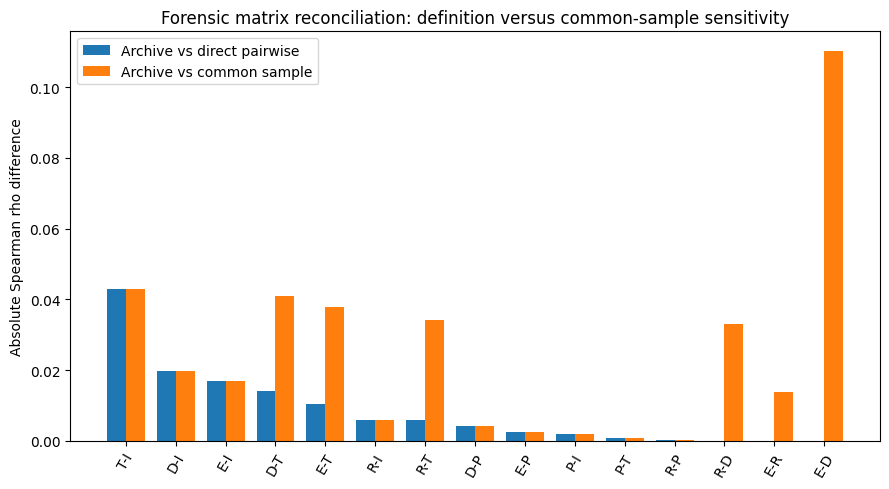

V13 COMPLETE: /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026/QQ_OPERATIONAL_RECONCILIATION_V13
CRITICAL: Candidate fingerprint agreement does not prove the original coding choices.


In [71]:
# CELL 65 | Pairwise vs common-support matrix and provenance status
assert all(k in globals() for k in ('X','cor','N','arch','lookup','comparison','V13')), 'Execute cells 61–64.'
import matplotlib.pyplot as plt
cc=X.dropna(subset=['E','R','D','P','T','I'])
assert len(cc)>0, 'No six-dimensional common support'
ccrho=cc.corr(method='spearman').loc[list(ETS_MEASURES),list(ETS_MEASURES)]
rows=[]
axes=list(ETS_MEASURES)
for i,a in enumerate(axes):
    for b in axes[i+1:]:
        frozen=float(arch.loc[lookup[a],lookup[b]])
        pair=float(cor.loc[a,b]); common=float(ccrho.loc[a,b]);
        rows.append(dict(pair=f'{a}-{b}',archived_rho=frozen,operational_pairwise_rho=pair,
                         operational_common_support_rho=common,pairwise_n=int(N.loc[a,b]),
                         common_n=len(cc),archive_minus_pairwise=frozen-pair,
                         pairwise_minus_common=pair-common,
                         archive_minus_common=frozen-common,
                         absolute_archival_gap_pairwise=abs(frozen-pair),
                         absolute_archival_gap_common=abs(frozen-common)))
ledger65=pd.DataFrame(rows).sort_values('absolute_archival_gap_pairwise',ascending=False)
ledger65.to_csv(V13/'65_pairwise_vs_common_support_reconciliation.csv',index=False)
ccrho.to_csv(V13/'65_common_support_operational_spearman.csv')
print('Six-dimensional complete-case sample:',f'{len(cc):,}', 'of',f'{len(X):,}')
display(ledger65[['pair','archived_rho','operational_pairwise_rho','operational_common_support_rho','pairwise_n','common_n','absolute_archival_gap_pairwise','absolute_archival_gap_common']])
fig,ax=plt.subplots(figsize=(9,5));idx=np.arange(len(ledger65));width=0.38
ax.bar(idx-width/2,ledger65.absolute_archival_gap_pairwise,width,label='Archive vs direct pairwise')
ax.bar(idx+width/2,ledger65.absolute_archival_gap_common,width,label='Archive vs common sample')
ax.set_xticks(idx,ledger65.pair,rotation=60);ax.set_ylabel('Absolute Spearman rho difference')
ax.set_title('Forensic matrix reconciliation: definition versus common-sample sensitivity')
ax.legend();fig.tight_layout();fig.savefig(V13/'65_reconciliation_discrepancies.png',dpi=200);plt.show()
flags=[]
for s in ('P','T','I'):
    sub=comparison[(comparison.target==s)&(comparison.status=='AVAILABLE')].copy()
    candidate=str(sub.iloc[0].candidate) if len(sub) else 'NONE'
    flags.append({'dimension':s,'closest_anchored_candidate_NOT_VERIFIED':candidate,
      'published_selection':'DO_NOT_REPLACE_ARCHIVE_AUTOMATICALLY',
      'required_evidence':'Original scripts, exact source variable and eligibility code',
      'status':'PROVENANCE_UNRESOLVED'})
flags=pd.DataFrame(flags)
flags.to_csv(V13/'65_provenance_decision_ledger.csv',index=False)
(V13/'65_editorial_interpretation.md').write_text(
"""# Forensic evidence on the archived ETS correlation matrix

The reconstructed matrix uses explicitly mapped descriptive variables. Some archived Spearman correlations differ from the recomputed estimates. The comparison of alternative source columns is a diagnostic fingerprint search, **not proof** of the archived construction. The six-construct complete-case matrix constitutes a separate descriptive sensitivity analysis; it must not be represented as the primary or original matrix without a prior methodological decision. Original scripts and outcome eligibility must be recovered to establish exact provenance. Pending this, the article should report the explicitly reproducible direct matrix, with the archived discrepancy documented in the audit trail and relevant supplementary material. The results do not establish external criterion validity.
""",encoding='utf-8')
manifest={'stage':'V13','journal':'Quality & Quantity','main44_n':len(X),
          'six_dimension_common_sample_n':len(cc),'source':'frozen MAIN44 and archived ETS Spearman matrix',
          'status':'Exploratory archival reconciliation; provenance not fully established',
          'outputs':sorted([x.name for x in V13.iterdir() if x.is_file()])}
(V13/'65_reconciliation_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('V13 COMPLETE:',V13)
print('CRITICAL: Candidate fingerprint agreement does not prove the original coding choices.')


# ETS Laboratory V14: Archived-Matrix Reconciliation

In [72]:
# CELL 66 | Reconstruct the archived ETS matrix with explicit percentile definitions
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

assert all(x in globals() for x in ["frame", "arch", "lookup", "OUT"]), \
    "Run the original laboratory through cell 65 before this continuation."
V14 = Path(OUT) / "QQ_MATRIX_PROVENANCE_V14"
V14.mkdir(parents=True, exist_ok=True)

MAPPING = {
    "E": "E_PCT_AREA_ANO",
    "R": "R_PCT_AREA_ANO",
    "D": "D_PCT_AREA_ANO",
    "P": "P_PAIRWISE_PCT_AREA_ANO",
    "T": "T_PCT_AREA_ANO",
    "I": "I_PAIRWISE_PCT_AREA_ANO",
}
ORDER = list(MAPPING)
missing = [c for c in MAPPING.values() if c not in frame.columns]
assert not missing, f"Required frozen fields missing: {missing}"

z = frame[[MAPPING[k] for k in ORDER]].copy()
z.columns = ORDER
for name in ORDER:
    z[name] = pd.to_numeric(z[name], errors="coerce").replace([np.inf, -np.inf], np.nan)
assert len(z) == 459177, f"Unexpected MAIN44 population: {len(z)}"
rho = z.corr(method="spearman").loc[ORDER, ORDER]
n_pairs = pd.DataFrame(index=ORDER, columns=ORDER, dtype="int64")
for a in ORDER:
    for b in ORDER:
        n_pairs.loc[a, b] = int(z[[a,b]].dropna().shape[0]) if a != b else int(z[a].notna().sum())

arch_rho = pd.DataFrame(index=ORDER, columns=ORDER, dtype=float)
for a in ORDER:
    for b in ORDER:
        arch_rho.loc[a,b] = float(arch.loc[lookup[a], lookup[b]])

rows = []
for i,a in enumerate(ORDER):
    for b in ORDER[i+1:]:
        diff = float(rho.loc[a,b] - arch_rho.loc[a,b])
        rows.append(dict(pair=f"{a}-{b}", source_a=MAPPING[a], source_b=MAPPING[b],
                         rho_direct=float(rho.loc[a,b]),
                         rho_archive=float(arch_rho.loc[a,b]),
                         delta=diff, abs_delta=abs(diff),
                         n_pair=int(n_pairs.loc[a,b])))
audit66 = pd.DataFrame(rows).sort_values("abs_delta", ascending=False)
tol = 1e-8
numeric_reproduction = bool((audit66.abs_delta <= tol).all())
rho.to_csv(V14/"66_reconstructed_percentile_spearman.csv", float_format="%.15g")
n_pairs.to_csv(V14/"66_pairwise_sample_sizes.csv")
audit66.to_csv(V14/"66_full_archive_reconciliation.csv", index=False)
pd.DataFrame([{"dimension":k, "frozen_column":v, "n_nonmissing":int(z[k].notna().sum())}
              for k,v in MAPPING.items()]).to_csv(V14/"66_exact_variable_mapping.csv", index=False)
print("NUMERICALLY_REPRODUCED_ARCHIVED_MATRIX:", numeric_reproduction)
print("MAX_ABSOLUTE_RHO_DISCREPANCY:", audit66.abs_delta.max())
display(audit66)
if not numeric_reproduction:
    print("NOT RECONCILED: archive differs beyond tolerance; do not replace archived provenance.")
else:
    print("FULL 15-PAIR RECONSTRUCTION: archived matrix reproduced using percentile variables.")
print("This is numerical reconstruction; it does not prove which original script generated the archive.")

NUMERICALLY_REPRODUCED_ARCHIVED_MATRIX: True
MAX_ABSOLUTE_RHO_DISCREPANCY: 8.326672684688674e-17


,pair,source_a,source_b,rho_direct,rho_archive,delta,abs_delta,n_pair
2,E-P,E_PCT_AREA_ANO,P_PAIRWISE_PCT_AREA_ANO,0.097020,0.097020,8.326673e-17,8.326673e-17,302956
10,D-T,D_PCT_AREA_ANO,T_PCT_AREA_ANO,0.113728,0.113728,8.326673e-17,8.326673e-17,363690
8,R-I,R_PCT_AREA_ANO,I_PAIRWISE_PCT_AREA_ANO,0.129274,0.129274,8.326673e-17,8.326673e-17,302956
14,T-I,T_PCT_AREA_ANO,I_PAIRWISE_PCT_AREA_ANO,0.139777,0.139777,8.326673e-17,8.326673e-17,302956
6,R-P,R_PCT_AREA_ANO,P_PAIRWISE_PCT_AREA_ANO,0.004580,0.004580,6.765422e-17,6.765422e-17,302956
7,R-T,R_PCT_AREA_ANO,T_PCT_AREA_ANO,0.247772,0.247772,5.551115e-17,5.551115e-17,363690
3,E-T,E_PCT_AREA_ANO,T_PCT_AREA_ANO,-0.127280,-0.127280,-5.551115e-17,5.551115e-17,363690
13,P-I,P_PAIRWISE_PCT_AREA_ANO,I_PAIRWISE_PCT_AREA_ANO,0.086822,0.086822,5.551115e-17,5.551115e-17,302956
12,P-T,P_PAIRWISE_PCT_AREA_ANO,T_PCT_AREA_ANO,-0.018742,-0.018742,-4.163336e-17,4.163336e-17,302956
5,R-D,R_PCT_AREA_ANO,D_PCT_AREA_ANO,-0.052034,-0.052034,-2.775558e-17,2.775558e-17,459177


FULL 15-PAIR RECONSTRUCTION: archived matrix reproduced using percentile variables.
This is numerical reconstruction; it does not prove which original script generated the archive.


# Separate percentile scaling from raw diversity constructs

In [73]:
# CELL 67 | Quantify raw-versus-percentile dependence and define the reporting distinction
assert all(x in globals() for x in ["z","MAPPING","rho","V14"])
RAW = {
    "E": "E_PCT_AREA_ANO",
    "R": "R_PCT_AREA_ANO",
    "D": "D_PCT_AREA_ANO",
    "P": "P_TEMPORAL_DIVERSITY_PAIRWISE",
    "T": "T_CROSS_GRANDE_SHARE",
    "I": "I_PROGRAM_DIVERSITY_PAIRWISE",
}
raw = frame[[RAW[k] for k in ORDER]].copy()
raw.columns = ORDER
for name in ORDER:
    raw[name] = pd.to_numeric(raw[name],errors="coerce").replace([np.inf,-np.inf],np.nan)
raw_rho = raw.corr(method="spearman").loc[ORDER,ORDER]
results = []
for j,a in enumerate(ORDER):
    for b in ORDER[j+1:]:
        num = int(raw[[a,b]].dropna().shape[0])
        rp = float(rho.loc[a,b])
        rr = float(raw_rho.loc[a,b])
        results.append(dict(pair=f"{a}-{b}", n_raw_pair=num,
                            percentile_rho=rp, raw_rho=rr, percentile_minus_raw=rp-rr,
                            percentile_measure_a=MAPPING[a], percentile_measure_b=MAPPING[b],
                            raw_measure_a=RAW[a],raw_measure_b=RAW[b]))
compar67=pd.DataFrame(results).sort_values("percentile_minus_raw",key=lambda s:s.abs(),ascending=False)
compar67.to_csv(V14/"67_raw_vs_area_year_percentile_correlations.csv",index=False)
raw_rho.to_csv(V14/"67_raw_operational_spearman.csv")
print("The archived matrix is a different statistical object from pooled raw-measure correlations.")
display(compar67[["pair","n_raw_pair","percentile_rho","raw_rho","percentile_minus_raw"]])
print("No causal or criterion-validity interpretation is assigned to either matrix.")

The archived matrix is a different statistical object from pooled raw-measure correlations.


,pair,n_raw_pair,percentile_rho,raw_rho,percentile_minus_raw
14,T-I,302956,0.139777,0.182706,-0.042928
11,D-I,302956,-0.400852,-0.381202,-0.019650
4,E-I,302956,0.181739,0.164845,0.016894
10,D-T,363690,0.113728,0.099515,0.014213
3,E-T,363690,-0.127280,-0.116997,-0.010284
8,R-I,302956,0.129274,0.135272,-0.005998
7,R-T,363690,0.247772,0.241795,0.005977
9,D-P,302956,-0.156504,-0.152411,-0.004094
2,E-P,302956,0.097020,0.094501,0.002519
13,P-I,302956,0.086822,0.084946,0.001876


No causal or criterion-validity interpretation is assigned to either matrix.


# Freeze publication-ready material with a provenance gate

In [74]:
# CELL 68 | Publication table, audited conclusions and execution manifest
import json, hashlib
from datetime import datetime, timezone

assert all(x in globals() for x in ["audit66", "compar67", "numeric_reproduction", "V14","MAPPING","n_pairs"])
v14_summary = {
    "target_journal":"Quality & Quantity",
    "article":"Beyond disruption scores: Epistemic Transition Signatures in Brazil’s postgraduate research system, 2013–2024",
    "timestamp_utc":datetime.now(timezone.utc).isoformat(),
    "frozen_main44_n":len(frame),
    "full_archive_matrix_reproduced":numeric_reproduction,
    "comparison_tolerance_absolute_rho":1e-8,
    "max_abs_difference":float(audit66.abs_delta.max()),
    "definition":"Area-year percentile version of E/R/D/P/T/I in pairwise-available samples",
    "limitations":["The source script that generated the original archived CSV is not proven solely by numerical agreement.",
                   "Pairwise correlations have different sample sizes.",
                   "The correlation matrix does not constitute external criterion validity.",
                   "The percentile measures and raw operational measures must not be presented as interchangeable.",
                   "Conditional D and P models have distinct risk sets from the correlation matrix."]
}
if numeric_reproduction:
    safe_table = rho.copy()
    safe_table.to_csv(V14/"68_TABLE_S1_REPRODUCED_ETS_PERCENTILE_CORRELATIONS.csv",
                      float_format="%.6f")
    n_pairs.to_csv(V14/"68_TABLE_S1_PAIRWISE_N.csv")
    text_method = (
        "The six-dimensional descriptive dependence matrix was calculated using area-year "
        "percentile measures of emergence, recombination, diffusion, pairwise temporal "
        "persistence diversity, disciplinary translation, and pairwise institutional "
        "diversity. Spearman correlations were calculated using available pairs, and "
        "pairwise sample sizes were reported. The complete set of 15 coefficients was "
        "numerically reconciled against the archived matrix at an absolute tolerance of 1e-8. "
        "The correlation matrix is descriptive and does not provide external criterion validation."
    )
else:
    text_method = (
        "The archived six-dimensional correlation matrix did not reproduce exactly under "
        "the tested percentile specification. The reconstructed and archived versions "
        "are documented separately, and the discrepancy requires further provenance review."
    )
(V14/"68_METHODS_AND_RESULTS_ENGLISH.md").write_text(
    "# Methods — Matrix definitions\n\n"+text_method+
    "\n\n# Provenance distinction\n\nNumerical reproduction does not establish the "
    "historical authorship or implementation of the source script. Raw and percentile "
    "measure matrices answer different descriptive questions.\n", encoding="utf-8")
files=[]
for f in sorted(V14.iterdir()):
    if f.is_file():
        files.append({"file":f.name,"bytes":f.stat().st_size,
                      "sha256":hashlib.sha256(f.read_bytes()).hexdigest()})
v14_summary["files"]=files
(V14/"68_manifest.json").write_text(json.dumps(v14_summary,indent=2,ensure_ascii=False),encoding="utf-8")
print("V14 COMPLETED:", V14, "outputs:",len(files)+1)
print("Archived percentile matrix numerically reproduced:",numeric_reproduction)
print("Ready for manuscript matrix table:",numeric_reproduction)


V14 COMPLETED: /content/drive/MyDrive/CAPES_Epistemic_Change/36_Quality_Quantity_ETS_Methodology_2026/QQ_MATRIX_PROVENANCE_V14 outputs: 10
Archived percentile matrix numerically reproduced: True
Ready for manuscript matrix table: True
